# 13/10/29 - 3D Transport Data

In [546]:
from pytweezer.experiment.motmaster_client import MotMasterClient
from pytweezer.drivers.imagemX2 import ImagEMX2Camera
from pytweezer.drivers.slm import SLM
from pytweezer.drivers.thorcam import ThorCamera
from pytweezer.experiment.experiment_parameter_manager import ExpParameterManager
import pytweezer.phasemask as pm
import pytweezer.analysis as an
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pytweezer.data_manager as DM

ExpParams = ExpParameterManager()

In [2]:
exp : MotMasterClient = MotMasterClient()
slm : SLM = SLM()
hamcam : ImagEMX2Camera = ImagEMX2Camera()

Rb MotMasterClient initialised.
SLM 1 initialised: 1024x1024 @ 8-bit, serial 7752, 40.230 degC
SLM 1 loaded LUT "C:\Program Files\Meadowlark Optics\Blink Plus\LUT Files\slm40_at852.LUT"
ImagEM X2 camera initialised.


In [29]:
slm.close()
hamcam.close()

SLM 1 closed.
ImagEM X2 camera closed.


In [3]:
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)
exp.set_motmaster_experiment("RbTweezerBasic2026_2")

hamcam.set_trigger_source("ext")
hamcam.set_external_exposure_mode()
hamcam.enable_em_gain(True)
hamcam.enable_direct_em_gain(True)
hamcam.set_sensitivity(600)
hamcam.timeout = 60*5
X0, Y0, WIDTH, HEIGHT = 110, 220, 256, 256
hamcam.set_roi(X0, WIDTH, Y0, HEIGHT)

In [615]:
hamcam.timeout = 60*5

## Phasemask Generator

In [616]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

gauss2d = lambda x, y, A, x0, y0, sx, sy, offset: (A * np.exp(-(((x - x0) ** 2) / (2 * sx ** 2) + ((y - y0) ** 2) / (2 * sy ** 2)))) + offset
A, x0, y0, sx, sy, offset = [-2.14197604e+03, -1.11443850e+01 - dx, 2.09919600e+00 - dy, 2.95002910e+03, 2.64281503e+03, 2.14239505e+03]

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


Phasemask 1

In [617]:
W1 = np.ones((13,13))
spacing_um = 5.0

w_n, theta_n, x_n1, y_n1, z_n1 = PM.generate_weighted_array(W1, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n1, y_n1, A, x0, y0, sx, sy, offset)

terms1 = [w_n, theta_n, x_n1, y_n1, z_n1]
pm_array1, terms1, _ = PM.superposition_optimization(terms1, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 13x13
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 6.33e-06 | Uniformity: 44.07% | Min/Max ratio: 0.018
Iteration 010 | Mean-Squared Error: 4.05e-08 | Uniformity: 78.44% | Min/Max ratio: 0.416
Iteration 020 | Mean-Squared Error: 1.32e-08 | Uniformity: 78.84% | Min/Max ratio: 0.421
Iteration 030 | Mean-Squared Error: 1.83e-09 | Uniformity: 78.80% | Min/Max ratio: 0.433
Iteration 040 | Mean-Squared Error: 2.85e-09 | Uniformity: 78.74% | Min/Max ratio: 0.436
Iteration 050 | Mean-Squared Error: 2.93e-09 | Uniformity: 78.83% | Min/Max ratio: 0.428
Iteration 060 | Mean-Squared Error: 1.43e-09 | Uniformity: 78.95% | Min/Max ratio: 0.431
Iteration 070 | Mean-Squared Error: 3.94e-10 | Uniformity: 78.98% | Min/Max ratio: 0.435
Iteration 080 | Mean-Squared Error: 1.49e-10 | Uniformity: 78.96% | Min/Max ratio: 0.437
Iteration 090 | Mean-Squared Error: 1.18e-10 | Uniformity: 78.95% | Min/Max ratio: 0.437


Phasemask 2

In [618]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.28e-05 | Uniformity: 45.39% | Min/Max ratio: 0.053
Iteration 010 | Mean-Squared Error: 3.79e-07 | Uniformity: 83.41% | Min/Max ratio: 0.515
Iteration 020 | Mean-Squared Error: 5.38e-08 | Uniformity: 85.15% | Min/Max ratio: 0.553
Iteration 030 | Mean-Squared Error: 8.40e-09 | Uniformity: 85.02% | Min/Max ratio: 0.557
Iteration 040 | Mean-Squared Error: 1.14e-08 | Uniformity: 85.03% | Min/Max ratio: 0.556
Iteration 050 | Mean-Squared Error: 7.59e-08 | Uniformity: 86.20% | Min/Max ratio: 0.551
Iteration 060 | Mean-Squared Error: 1.94e-08 | Uniformity: 85.59% | Min/Max ratio: 0.570
Iteration 070 | Mean-Squared Error: 4.01e-09 | Uniformity: 85.21% | Min/Max ratio: 0.569
Iteration 080 | Mean-Squared Error: 9.63e-10 | Uniformity: 85.17% | Min/Max ratio: 0.566
Iteration 090 | Mean-Squared Error: 3.22e-10 | Uniformity: 85.17% | Min/Max ratio: 0.565
It

Phasemask 3

In [619]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.28e-05 | Uniformity: 55.28% | Min/Max ratio: 0.103
Iteration 010 | Mean-Squared Error: 2.55e-07 | Uniformity: 83.95% | Min/Max ratio: 0.487
Iteration 020 | Mean-Squared Error: 5.08e-08 | Uniformity: 84.59% | Min/Max ratio: 0.540
Iteration 030 | Mean-Squared Error: 1.97e-08 | Uniformity: 84.98% | Min/Max ratio: 0.552
Iteration 040 | Mean-Squared Error: 4.02e-09 | Uniformity: 85.10% | Min/Max ratio: 0.557
Iteration 050 | Mean-Squared Error: 6.90e-10 | Uniformity: 85.18% | Min/Max ratio: 0.561
Iteration 060 | Mean-Squared Error: 4.55e-10 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 070 | Mean-Squared Error: 3.76e-10 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 080 | Mean-Squared Error: 2.84e-10 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 2.17e-10 | Uniformity: 85.19% | Min/Max ratio: 0.563
It

Upload initial phasemask

In [620]:
pm_composite = PM.superimpose([pm_array1, PM.fresnel, PM.blaze, PM.zernike])
pm_composite_uint8 = PM.transform_phase_8bit(pm_composite).get()
slm.update_mask(pm_composite_uint8)

---
---

In [10]:
exp_params = ExpParams.load_parameters()['motmaster_parameters']
for key, value in exp_params.items():
    print(f"{key}: {value}")

tMOTLoadCoolVCO: 4.2631578947368425
tMOTLoadRepVCO: 1.8421052631578947
tMolCoolVCO1: 1.0996864762445278
tMolRepVCO1: 3.11
tMolCoolVVA1: 1.0
tMolRepVVA1: 0.8350746613039681
tMolCoolVCO2: 2.7309107154960333
tMolRepVCO2: 3.26
tMolCoolVVA2: 0.6911883206654206
tMolRepVVA2: 1.0
tMOTShimXccValue: 1.0681520021497488
tMOTShimYccValue: 0.0
tMOTShimZccValue: -0.47448379939831087
tMOTLoadRepVVA: 0.6526315789473685
tMOTLoadCoolVVA: 0.9210526315789475
tImgCoolVCO: 1.894736842105263
tImgCoolVVA: 0.9051724137931035
tMolassesShimXccValue: 10.0
tMolassesShimYccValue: 2.798186679547726
tMolassesShimZccValue: 0.4081770358068526


## Baseline

Parameter 'conversion_factor' set to 0.009508957628343926.
Parameter 'conversion_offset' set to 1916.6092529296875.
Parameters saved.


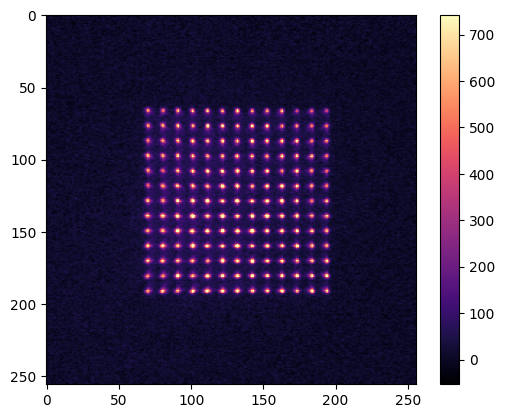

In [623]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
    "BackgroundDrop": 1})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)

ExpParams.set_parameter("conversion_factor", hamcam.dcam.get_attribute_value("CONVERSION FACTOR COEFF"))
ExpParams.set_parameter("conversion_offset", hamcam.dcam.get_attribute_value("CONVERSION FACTOR OFFSET"))
ExpParams.save_parameters()

Looking for trap sites...
169 Atoms Detected.
Parameter 'x_centre' set to 131.4378698224852.
Parameter 'y_centre' set to 128.30769230769232.
Parameters saved.


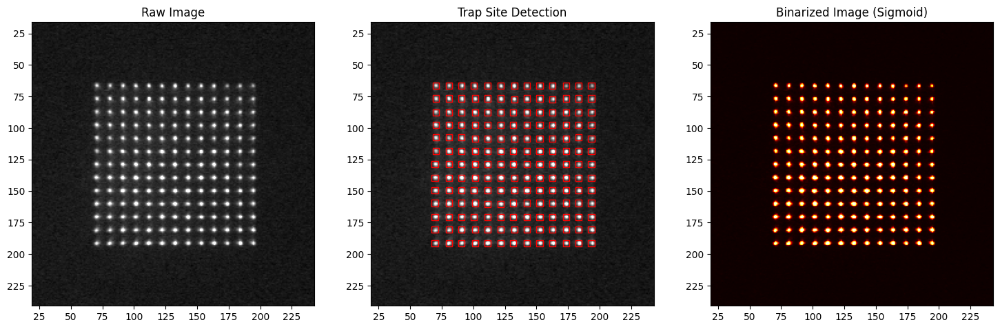

Trap (0) Loading Probability : 49.00 %
Trap (1) Loading Probability : 54.00 %
Trap (2) Loading Probability : 41.00 %
Trap (3) Loading Probability : 60.00 %
Trap (4) Loading Probability : 57.00 %
Trap (5) Loading Probability : 54.00 %
Trap (6) Loading Probability : 65.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 57.00 %
Trap (9) Loading Probability : 59.00 %
Trap (10) Loading Probability : 58.00 %
Trap (11) Loading Probability : 57.00 %
Trap (12) Loading Probability : 60.00 %
Trap (13) Loading Probability : 52.00 %
Trap (14) Loading Probability : 56.00 %
Trap (15) Loading Probability : 57.00 %
Trap (16) Loading Probability : 52.00 %
Trap (17) Loading Probability : 57.00 %
Trap (18) Loading Probability : 57.00 %
Trap (19) Loading Probability : 56.00 %
Trap (20) Loading Probability : 54.00 %
Trap (21) Loading Probability : 68.00 %
Trap (22) Loading Probability : 54.00 %
Trap (23) Loading Probability : 57.00 %
Trap (24) Loading Probability : 60.00 %
Trap (25) 

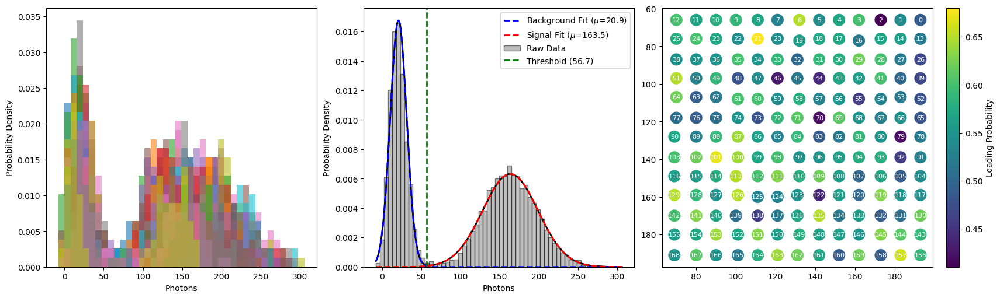

In [624]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 13*13, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

Trap (0) Loading Probability : 49.00 %
Trap (1) Loading Probability : 54.00 %
Trap (2) Loading Probability : 41.00 %
Trap (3) Loading Probability : 60.00 %
Trap (4) Loading Probability : 57.00 %
Trap (5) Loading Probability : 54.00 %
Trap (6) Loading Probability : 65.00 %
Trap (7) Loading Probability : 54.00 %
Trap (8) Loading Probability : 57.00 %
Trap (9) Loading Probability : 59.00 %
Trap (10) Loading Probability : 59.00 %
Trap (11) Loading Probability : 57.00 %
Trap (12) Loading Probability : 60.00 %
Trap (13) Loading Probability : 52.00 %
Trap (14) Loading Probability : 56.00 %
Trap (15) Loading Probability : 57.00 %
Trap (16) Loading Probability : 52.00 %
Trap (17) Loading Probability : 58.00 %
Trap (18) Loading Probability : 57.00 %
Trap (19) Loading Probability : 56.00 %
Trap (20) Loading Probability : 54.00 %
Trap (21) Loading Probability : 68.00 %
Trap (22) Loading Probability : 54.00 %
Trap (23) Loading Probability : 57.00 %
Trap (24) Loading Probability : 60.00 %
Trap (25) 

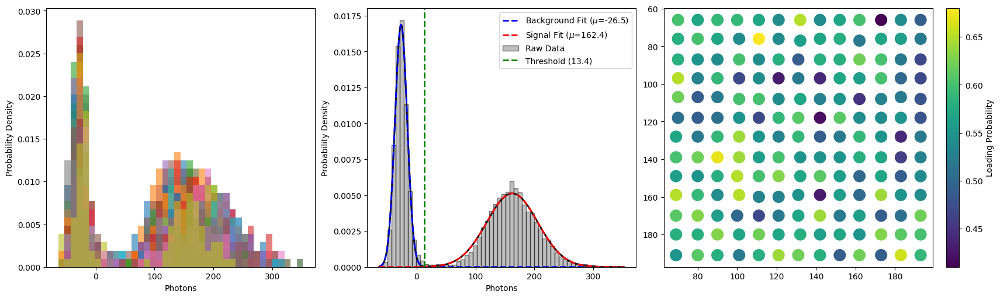

In [625]:
# Analyse images (fliplr) with indexed grid positions - PSF
psf_window = 9

# Templates come from the raw frames - the matched filter needs no top-hat.
scorer = an.SiteScorer.from_images(imgs1, grid_positions, window_size=psf_window)
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(
    imgs1, grid_positions, scorer=scorer, threshold_detection=True, binning=60)

scorer.threshold = threshold_1 * 1.0
print(f"PSF threshold {scorer.threshold:.2f} photons, detection fidelity {fidelity*100:.3f} %")

#### Save Data

In [16]:
import pytweezer.data_manager as DM

dataset_title = "Baseline_13x13_5um_initial"

context_info = """ 
    200 images of initial stochastic loading of a 13x13 tweezer array with 5um spacing. Included initial and final images.
    Also saved the grid positions, loading probabilities, and detection threshold for future analysis. 
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": imgs1, 
           "imgs2": imgs2, 
           "photons": photons, 
           "loading_probabilities": loading_probabilities, 
           "threshold": threshold_1, 
           "fidelity": fidelity}

images = {"imgs1": imgs1, "imgs2": imgs2}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\Baseline_13x13_5um_initial


## Baseline

Parameter 'conversion_factor' set to 0.009508957628343926.
Parameter 'conversion_offset' set to 1916.6536865234375.
Parameters saved.


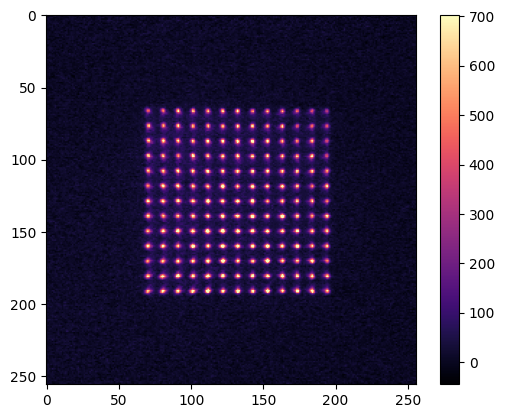

In [30]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
    "BackgroundDrop": 1})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)

ExpParams.set_parameter("conversion_factor", hamcam.dcam.get_attribute_value("CONVERSION FACTOR COEFF"))
ExpParams.set_parameter("conversion_offset", hamcam.dcam.get_attribute_value("CONVERSION FACTOR OFFSET"))
ExpParams.save_parameters()

Looking for trap sites...
169 Atoms Detected.
Parameter 'x_centre' set to 131.59171597633136.
Parameter 'y_centre' set to 128.4023668639053.
Parameters saved.


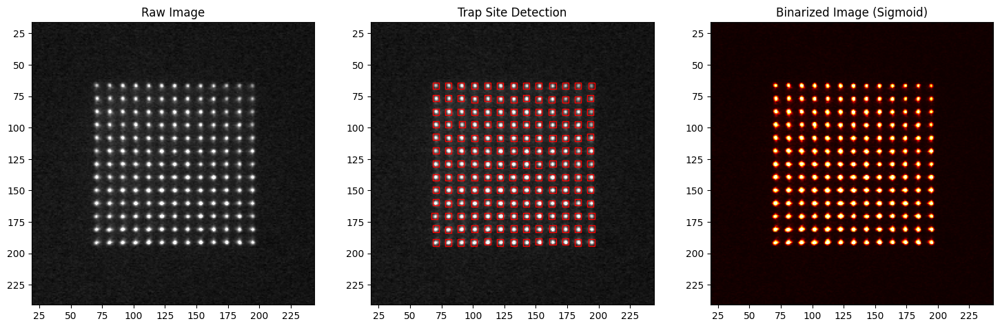

Trap (0) Loading Probability : 45.00 %
Trap (1) Loading Probability : 45.00 %
Trap (2) Loading Probability : 51.00 %
Trap (3) Loading Probability : 45.00 %
Trap (4) Loading Probability : 55.00 %
Trap (5) Loading Probability : 49.00 %
Trap (6) Loading Probability : 54.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 56.00 %
Trap (9) Loading Probability : 60.00 %
Trap (10) Loading Probability : 65.00 %
Trap (11) Loading Probability : 54.00 %
Trap (12) Loading Probability : 53.00 %
Trap (13) Loading Probability : 43.00 %
Trap (14) Loading Probability : 51.00 %
Trap (15) Loading Probability : 39.00 %
Trap (16) Loading Probability : 60.00 %
Trap (17) Loading Probability : 44.00 %
Trap (18) Loading Probability : 53.00 %
Trap (19) Loading Probability : 55.00 %
Trap (20) Loading Probability : 46.00 %
Trap (21) Loading Probability : 48.00 %
Trap (22) Loading Probability : 53.00 %
Trap (23) Loading Probability : 56.00 %
Trap (24) Loading Probability : 55.00 %
Trap (25) 

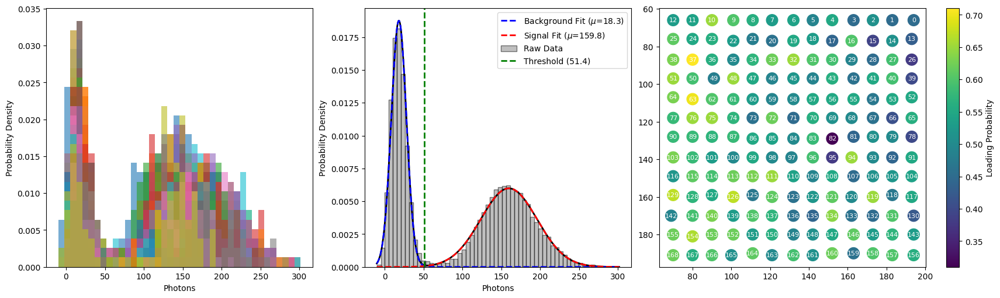

In [31]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 13*13, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

Trap (0) Loading Probability : 53.50 %
Trap (1) Loading Probability : 51.50 %
Trap (2) Loading Probability : 46.00 %
Trap (3) Loading Probability : 58.00 %
Trap (4) Loading Probability : 52.50 %
Trap (5) Loading Probability : 50.50 %
Trap (6) Loading Probability : 59.00 %
Trap (7) Loading Probability : 51.50 %
Trap (8) Loading Probability : 52.00 %
Trap (9) Loading Probability : 57.50 %
Trap (10) Loading Probability : 57.50 %
Trap (11) Loading Probability : 53.00 %
Trap (12) Loading Probability : 57.50 %
Trap (13) Loading Probability : 43.50 %
Trap (14) Loading Probability : 50.00 %
Trap (15) Loading Probability : 46.00 %
Trap (16) Loading Probability : 53.00 %
Trap (17) Loading Probability : 45.00 %
Trap (18) Loading Probability : 48.00 %
Trap (19) Loading Probability : 57.00 %
Trap (20) Loading Probability : 51.00 %
Trap (21) Loading Probability : 51.50 %
Trap (22) Loading Probability : 56.00 %
Trap (23) Loading Probability : 58.00 %
Trap (24) Loading Probability : 56.00 %
Trap (25) 

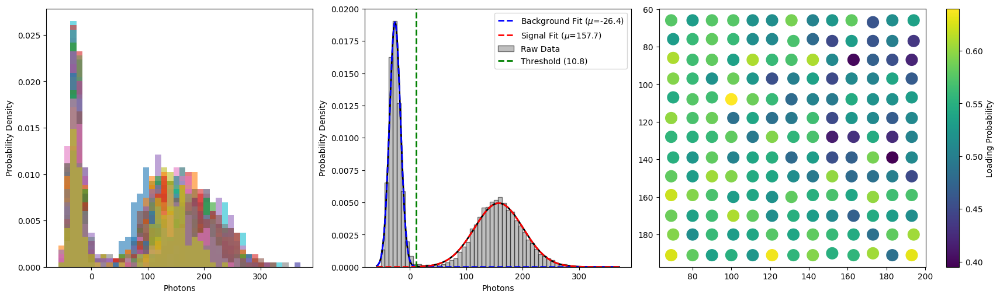

In [ ]:
# Analyse images (fliplr) with indexed grid positions - PSF
psf_window = 9

# Templates come from the raw frames - the matched filter needs no top-hat.
scorer = an.SiteScorer.from_images(imgs1, grid_positions, window_size=psf_window)
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(
    imgs1, grid_positions, scorer=scorer, threshold_detection=True, binning=60)

scorer.threshold = threshold_1 * 1.0
print(f"PSF threshold {scorer.threshold:.2f} photons, detection fidelity {fidelity*100:.3f} %")

#### Save Data

In [23]:
import pytweezer.data_manager as DM

dataset_title = "Baseline_13x13_5um_initial_2"

context_info = """ 
    200 images of initial stochastic loading of a 13x13 tweezer array with 5um spacing. Included initial and final images.
    Also saved the grid positions, loading probabilities, and detection threshold for future analysis. 
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": imgs1, 
           "imgs2": imgs2, 
           "photons": photons, 
           "loading_probabilities": loading_probabilities, 
           "threshold": threshold_1, 
           "fidelity": fidelity}

images = {"imgs1": imgs1, "imgs2": imgs2}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\Baseline_13x13_5um_initial_2


## Routine MOT Shim Coil Optimisation

In [32]:
from skopt.space import Real, Integer
from skopt.utils import use_named_args
from skopt import Optimizer

In [ ]:
# --- 1. Define the Experimental Search Space ---
dimensions = [  
    Real(name='tMOTShimXccValue', low=0.0, high=5.0),
    Real(name='tMOTShimYccValue', low=0.0, high=5.0),
    Real(name='tMOTShimZccValue', low=-1.0, high=0.0)
]

# Experiment and camera setup
n_iterations = 50
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)

@use_named_args(dimensions=dimensions)
def tweezer_exp_objective(tMOTShimXccValue, tMOTShimYccValue, tMOTShimZccValue):
    hamcam.start_acquisition()
    exp.start_motmaster_experiment({
        "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
        "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
        "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
        "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
        "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
        "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
        "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
        "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
        "tMOTShimXccValue": tMOTShimXccValue, "tMOTShimYccValue": tMOTShimYccValue, "tMOTShimZccValue": tMOTShimZccValue,
        "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
        "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
        "BackgroundDrop": 1})

    imgs = hamcam.acquire_n_frames(n_iterations * 2)
    imgs1, imgs2 = imgs[::2], imgs[1::2]
    imgs_filtered_1 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]

    _, loading_probabilities, _, _ = an.get_array_loading_statistics(imgs_filtered_1, grid_positions, threshold_detection=False, threshold=threshold_1, binning=60, show_histogram=False, verbose=False)    
    mean_loading_probability = np.mean(loading_probabilities)
    measured_loss = 1.0 - mean_loading_probability

    print(f"Parameters: tMOTShimXccValue = {tMOTShimXccValue:.2f}, tMOTShimYccValue = {tMOTShimYccValue:.2f}, tMOTShimZccValue = {tMOTShimZccValue:.2f}  |  Mean Loading Probability = {mean_loading_probability:.4f}")
    return measured_loss

In [34]:
print("Starting Bayesian Optimization with dynamic exploration...")

n_calls = 50
n_initial_points = 10
xi_start = 0.100
xi_end = 0.001

opt = Optimizer(
    dimensions=dimensions,
    n_initial_points=n_initial_points,
    acq_func='EI',
    random_state=50
)

# Custom optimization loop
for i in range(n_calls):
    current_xi = xi_start - (xi_start - xi_end) * (i / (n_calls - 1))
    opt.acq_func_kwargs = {'xi': current_xi}
    suggested_params = opt.ask()
    loss = tweezer_exp_objective(suggested_params)
    result = opt.tell(suggested_params, loss)
    print(f"Iteration {i+1}/{n_calls} (xi = {current_xi:.4f})")
    print(f"  Current score: {(1-loss):.4f}")
    print(f"  Best score: {(1-result.fun):.4f}\n")

# --- 4. Analyze the Results ---
print("\n" + "="*40)
print("Optimization Complete!")
print("="*40)

high_score = 1 - result.fun
best_params = result.x

print(f"Best Parameters Found:")
for dim, value in zip(dimensions, best_params):
    print(f"  {dim.name}: {value:.4f}")

Starting Bayesian Optimization with dynamic exploration...
Parameters: tMOTShimXccValue = 0.65, tMOTShimYccValue = 0.37, tMOTShimZccValue = -0.39  |  Mean Loading Probability = 0.5482
Iteration 1/50 (xi = 0.1000)
  Current score: 0.5482
  Best score: 0.5482

Parameters: tMOTShimXccValue = 0.11, tMOTShimYccValue = 0.76, tMOTShimZccValue = -0.05  |  Mean Loading Probability = 0.3850
Iteration 2/50 (xi = 0.0980)
  Current score: 0.3850
  Best score: 0.5482

Parameters: tMOTShimXccValue = 4.02, tMOTShimYccValue = 1.22, tMOTShimZccValue = -0.67  |  Mean Loading Probability = 0.4858
Iteration 3/50 (xi = 0.0960)
  Current score: 0.4858
  Best score: 0.5482

Parameters: tMOTShimXccValue = 2.20, tMOTShimYccValue = 0.67, tMOTShimZccValue = -0.41  |  Mean Loading Probability = 0.5480
Iteration 4/50 (xi = 0.0939)
  Current score: 0.5480
  Best score: 0.5482

Parameters: tMOTShimXccValue = 4.89, tMOTShimYccValue = 0.44, tMOTShimZccValue = -0.71  |  Mean Loading Probability = 0.4660
Iteration 5/50 (

In [35]:
ExpParams.set_parameter("tMOTShimXccValue", best_params[0])
ExpParams.set_parameter("tMOTShimYccValue", best_params[1])
ExpParams.set_parameter("tMOTShimZccValue", best_params[2])
ExpParams.save_parameters()

Parameter 'tMOTShimXccValue' set to 1.0681520021497488.
Parameter 'tMOTShimYccValue' set to 0.0.
Parameter 'tMOTShimZccValue' set to -0.47448379939831087.
Parameters saved.


## Baseline

Parameter 'conversion_factor' set to 0.009508957628343926.
Parameter 'conversion_offset' set to 1916.9437255859375.
Parameters saved.


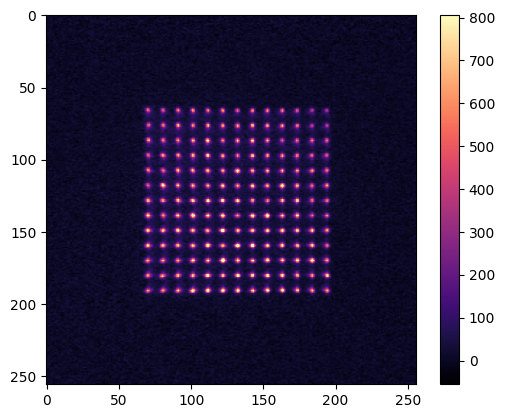

In [36]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0,
    "BackgroundDrop": 1})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)

ExpParams.set_parameter("conversion_factor", hamcam.dcam.get_attribute_value("CONVERSION FACTOR COEFF"))
ExpParams.set_parameter("conversion_offset", hamcam.dcam.get_attribute_value("CONVERSION FACTOR OFFSET"))
ExpParams.save_parameters()

Looking for trap sites...
169 Atoms Detected.
Parameter 'x_centre' set to 131.6449704142012.
Parameter 'y_centre' set to 128.01775147928993.
Parameters saved.


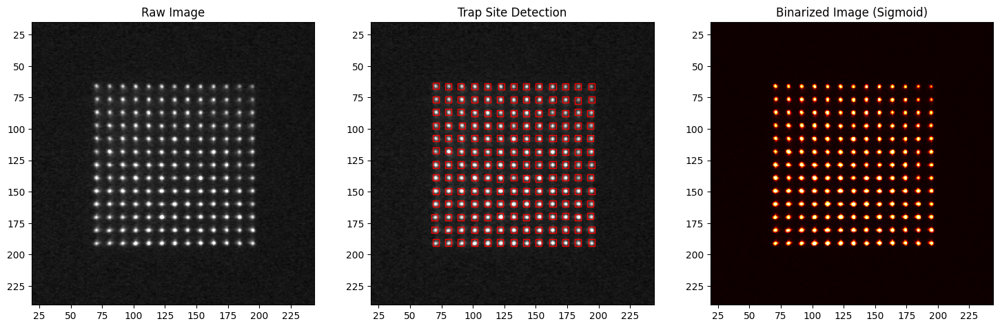

Trap (0) Loading Probability : 43.00 %
Trap (1) Loading Probability : 42.00 %
Trap (2) Loading Probability : 51.00 %
Trap (3) Loading Probability : 50.00 %
Trap (4) Loading Probability : 57.00 %
Trap (5) Loading Probability : 55.00 %
Trap (6) Loading Probability : 43.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 53.00 %
Trap (9) Loading Probability : 61.00 %
Trap (10) Loading Probability : 56.00 %
Trap (11) Loading Probability : 51.00 %
Trap (12) Loading Probability : 60.00 %
Trap (13) Loading Probability : 42.00 %
Trap (14) Loading Probability : 40.00 %
Trap (15) Loading Probability : 51.00 %
Trap (16) Loading Probability : 61.00 %
Trap (17) Loading Probability : 47.00 %
Trap (18) Loading Probability : 54.00 %
Trap (19) Loading Probability : 55.00 %
Trap (20) Loading Probability : 45.00 %
Trap (21) Loading Probability : 57.00 %
Trap (22) Loading Probability : 50.00 %
Trap (23) Loading Probability : 57.00 %
Trap (24) Loading Probability : 56.00 %
Trap (25) 

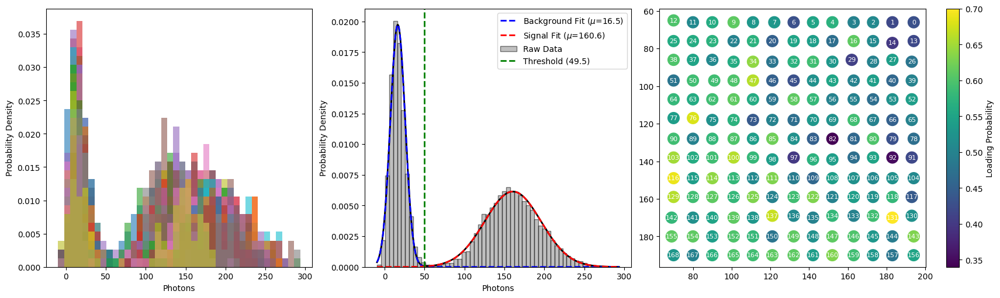

In [37]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 13*13, detection_step=100)
an.set_array_centre(grid_positions)
grid_positions = an.index_grid_positions(grid_positions, x_n1, y_n1)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

Trap (0) Loading Probability : 44.00 %
Trap (1) Loading Probability : 42.00 %
Trap (2) Loading Probability : 51.00 %
Trap (3) Loading Probability : 50.00 %
Trap (4) Loading Probability : 58.00 %
Trap (5) Loading Probability : 55.00 %
Trap (6) Loading Probability : 43.00 %
Trap (7) Loading Probability : 53.00 %
Trap (8) Loading Probability : 53.00 %
Trap (9) Loading Probability : 61.00 %
Trap (10) Loading Probability : 55.00 %
Trap (11) Loading Probability : 51.00 %
Trap (12) Loading Probability : 61.00 %
Trap (13) Loading Probability : 42.00 %
Trap (14) Loading Probability : 40.00 %
Trap (15) Loading Probability : 53.00 %
Trap (16) Loading Probability : 61.00 %
Trap (17) Loading Probability : 47.00 %
Trap (18) Loading Probability : 54.00 %
Trap (19) Loading Probability : 55.00 %
Trap (20) Loading Probability : 45.00 %
Trap (21) Loading Probability : 57.00 %
Trap (22) Loading Probability : 50.00 %
Trap (23) Loading Probability : 57.00 %
Trap (24) Loading Probability : 56.00 %
Trap (25) 

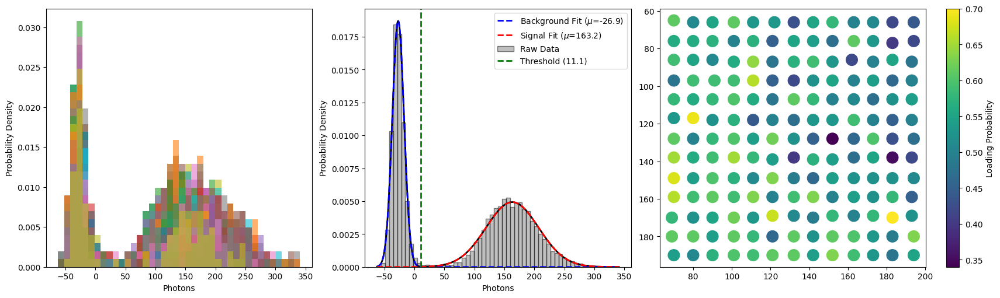

In [38]:
# Analyse images (fliplr) with indexed grid positions - PSF
psf_window = 9

# Templates come from the raw frames - the matched filter needs no top-hat.
scorer = an.SiteScorer.from_images(imgs1, grid_positions, window_size=psf_window)
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(
    imgs1, grid_positions, scorer=scorer, threshold_detection=True, binning=60)

scorer.threshold = threshold_1 * 1.0
print(f"PSF threshold {scorer.threshold:.2f} photons, detection fidelity {fidelity*100:.3f} %")

#### Save Data

In [39]:
import pytweezer.data_manager as DM

dataset_title = "Baseline_13x13_5um_initial_3"

context_info = """ 
    200 images of initial stochastic loading of a 13x13 tweezer array with 5um spacing. Included initial and final images.
    Also saved the grid positions, loading probabilities, and detection threshold for future analysis. 
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": imgs1, 
           "imgs2": imgs2, 
           "photons": photons, 
           "loading_probabilities": loading_probabilities, 
           "threshold": threshold_1, 
           "fidelity": fidelity}

images = {"imgs1": imgs1, "imgs2": imgs2}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\Baseline_13x13_5um_initial_3


## Baseline Survival

In [40]:
# Experiment and camera setup
n_iterations = 200
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(n_iterations)
hamcam.setup_acquisition("snap", n_iterations * 2)
hamcam.start_acquisition()
exp.start_motmaster_experiment({
    "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
    "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
    "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"),
    "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
    "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"),
    "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
    "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"),
    "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
    "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
    "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
    "tTweezerSetVVA0": 0.0, "tTweezerSetVVA1": 0.0, "tDelay2": 5000,
    "BackgroundDrop": 0})

imgs = hamcam.acquire_n_frames(n_iterations * 2)
imgs1, imgs2 = imgs[::2], imgs[1::2]

Trap (0) Loading Probability : 49.00 %
Trap (1) Loading Probability : 46.00 %
Trap (2) Loading Probability : 46.00 %
Trap (3) Loading Probability : 52.00 %
Trap (4) Loading Probability : 60.00 %
Trap (5) Loading Probability : 54.00 %
Trap (6) Loading Probability : 58.50 %
Trap (7) Loading Probability : 56.00 %
Trap (8) Loading Probability : 58.00 %
Trap (9) Loading Probability : 61.50 %
Trap (10) Loading Probability : 53.50 %
Trap (11) Loading Probability : 55.50 %
Trap (12) Loading Probability : 55.00 %
Trap (13) Loading Probability : 40.50 %
Trap (14) Loading Probability : 46.50 %
Trap (15) Loading Probability : 47.50 %
Trap (16) Loading Probability : 50.50 %
Trap (17) Loading Probability : 48.00 %
Trap (18) Loading Probability : 56.50 %
Trap (19) Loading Probability : 54.50 %
Trap (20) Loading Probability : 49.00 %
Trap (21) Loading Probability : 49.50 %
Trap (22) Loading Probability : 53.50 %
Trap (23) Loading Probability : 60.00 %
Trap (24) Loading Probability : 55.00 %
Trap (25) 

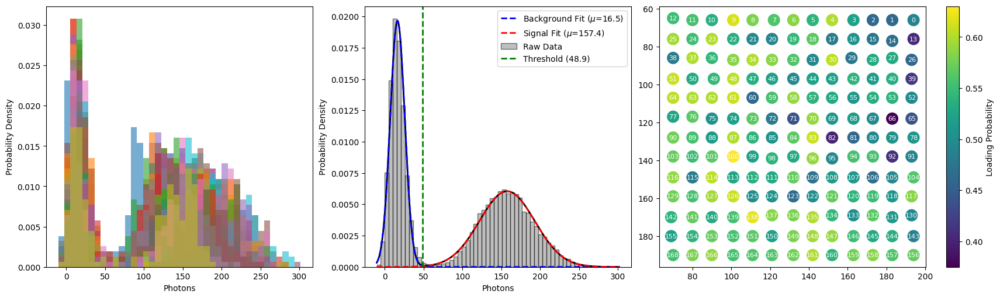

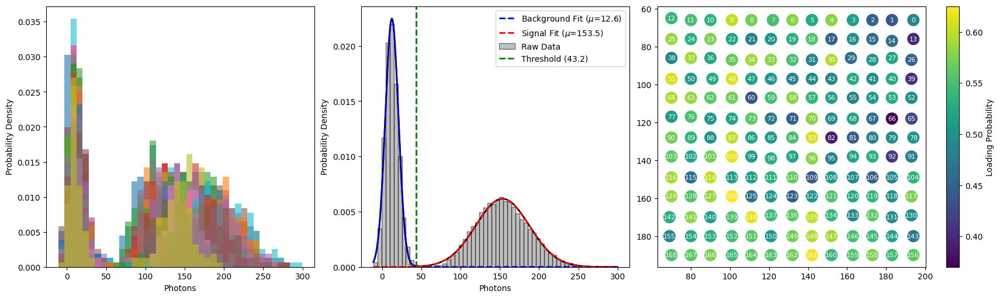

In [41]:
imgs_filtered_1 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
imgs_filtered_2 = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs2]
baseline_survival_probability = an.extract_survival_probability(imgs_filtered_1, imgs_filtered_2, grid_positions, window_size=window)
out1 = an.get_array_loading_statistics(imgs_filtered_1, grid_positions, threshold_detection=True, window_size=window, binning=60, show_site_labels=True)
out2 = an.get_array_loading_statistics(imgs_filtered_2, grid_positions, threshold_detection=True, window_size=window, binning=60, show_site_labels=True)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

#### Save Data

In [42]:
dataset_title = "Baseline_13x13_5um_survival_probability"

context_info = """ 
    Survival probability measurement of a 13x13 tweezer array with 5um spacing. Included initial and final images, as well as the survival probability for each site.
    50 ms delay between the initial and final images. 10 ms imaging exposure time. Standard exp parameters. 
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": imgs1, 
           "imgs2": imgs2, 
           "baseline_survival_probability": baseline_survival_probability,
           "statistics1": out1,
           "statistics2": out2}

images = {"imgs1": imgs1, "imgs2": imgs2}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\Baseline_13x13_5um_survival_probability


---
## Rearrangement + Transport Test 1 - Test

Phasemask 2

In [43]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.61e-05 | Uniformity: 50.47% | Min/Max ratio: 0.068
Iteration 010 | Mean-Squared Error: 3.25e-07 | Uniformity: 84.74% | Min/Max ratio: 0.554
Iteration 020 | Mean-Squared Error: 2.57e-08 | Uniformity: 85.05% | Min/Max ratio: 0.562
Iteration 030 | Mean-Squared Error: 1.75e-08 | Uniformity: 85.24% | Min/Max ratio: 0.554
Iteration 040 | Mean-Squared Error: 1.53e-08 | Uniformity: 85.01% | Min/Max ratio: 0.554
Iteration 050 | Mean-Squared Error: 4.91e-09 | Uniformity: 85.17% | Min/Max ratio: 0.561
Iteration 060 | Mean-Squared Error: 9.39e-09 | Uniformity: 85.02% | Min/Max ratio: 0.553
Iteration 070 | Mean-Squared Error: 7.59e-09 | Uniformity: 85.03% | Min/Max ratio: 0.551
Iteration 080 | Mean-Squared Error: 1.14e-09 | Uniformity: 85.13% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 3.05e-10 | Uniformity: 85.15% | Min/Max ratio: 0.562
It

Phasemask 3

In [45]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 0.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.23e-05 | Uniformity: 54.11% | Min/Max ratio: 0.091
Iteration 010 | Mean-Squared Error: 2.03e-07 | Uniformity: 84.74% | Min/Max ratio: 0.523
Iteration 020 | Mean-Squared Error: 5.64e-09 | Uniformity: 85.14% | Min/Max ratio: 0.561
Iteration 030 | Mean-Squared Error: 1.52e-08 | Uniformity: 85.16% | Min/Max ratio: 0.565
Iteration 040 | Mean-Squared Error: 3.15e-08 | Uniformity: 85.16% | Min/Max ratio: 0.567
Iteration 050 | Mean-Squared Error: 2.18e-08 | Uniformity: 85.14% | Min/Max ratio: 0.569
Iteration 060 | Mean-Squared Error: 7.02e-09 | Uniformity: 85.12% | Min/Max ratio: 0.559
Iteration 070 | Mean-Squared Error: 5.78e-09 | Uniformity: 85.14% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 5.51e-09 | Uniformity: 85.17% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 2.13e-09 | Uniformity: 85.18% | Min/Max ratio: 0.558
It

In [46]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 11.1).
Transport node initialised.


In [47]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [49]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 31 frames, 29.5087 ms total
Transport complete: 2 frames, 3.8637 ms total
Images acquired from rearrangement node.


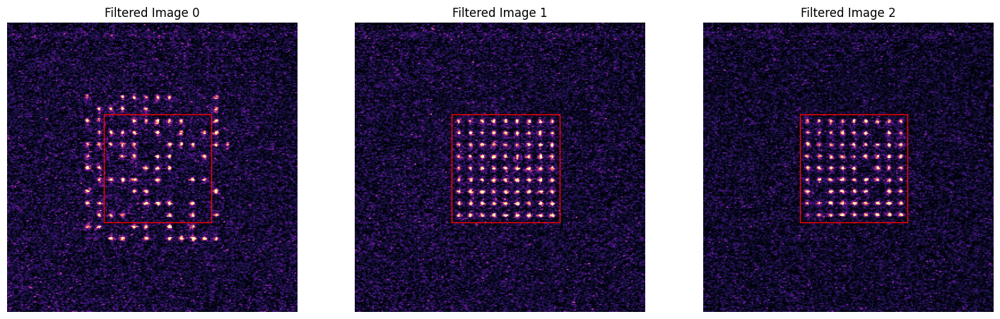

In [50]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [52]:
dataset_title = "rearrange_transport_exp_1"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. Defect free example.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_1


---
## Rearrangement + Transport Test 2 - 10 um dx Transport

Phasemask 2

In [53]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.71e-05 | Uniformity: 58.54% | Min/Max ratio: 0.057
Iteration 010 | Mean-Squared Error: 1.18e-07 | Uniformity: 84.39% | Min/Max ratio: 0.529
Iteration 020 | Mean-Squared Error: 2.86e-08 | Uniformity: 85.44% | Min/Max ratio: 0.558
Iteration 030 | Mean-Squared Error: 4.56e-08 | Uniformity: 85.03% | Min/Max ratio: 0.548
Iteration 040 | Mean-Squared Error: 1.44e-08 | Uniformity: 85.24% | Min/Max ratio: 0.563
Iteration 050 | Mean-Squared Error: 2.81e-09 | Uniformity: 85.23% | Min/Max ratio: 0.563
Iteration 060 | Mean-Squared Error: 1.14e-09 | Uniformity: 85.19% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 2.23e-09 | Uniformity: 85.17% | Min/Max ratio: 0.564
Iteration 080 | Mean-Squared Error: 4.39e-09 | Uniformity: 85.10% | Min/Max ratio: 0.565
Iteration 090 | Mean-Squared Error: 3.17e-09 | Uniformity: 85.09% | Min/Max ratio: 0.567
It

Phasemask 3

In [54]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 10.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.29e-05 | Uniformity: 51.83% | Min/Max ratio: 0.040
Iteration 010 | Mean-Squared Error: 2.42e-07 | Uniformity: 85.44% | Min/Max ratio: 0.524
Iteration 020 | Mean-Squared Error: 4.78e-08 | Uniformity: 84.87% | Min/Max ratio: 0.557
Iteration 030 | Mean-Squared Error: 3.36e-09 | Uniformity: 85.02% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 5.69e-09 | Uniformity: 85.01% | Min/Max ratio: 0.565
Iteration 050 | Mean-Squared Error: 3.21e-09 | Uniformity: 85.18% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 6.15e-09 | Uniformity: 85.28% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 9.07e-09 | Uniformity: 85.19% | Min/Max ratio: 0.561
Iteration 080 | Mean-Squared Error: 3.29e-08 | Uniformity: 84.97% | Min/Max ratio: 0.556
Iteration 090 | Mean-Squared Error: 1.02e-08 | Uniformity: 84.98% | Min/Max ratio: 0.554
It

In [55]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 11.1).
Transport node initialised.


In [56]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [61]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.1593 ms total
Transport complete: 22 frames, 18.1139 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.4511 ms total
Transport complete: 22 frames, 17.7916 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 33 frames, 27.3134 ms total
Transport complete: 22 frames, 18.2810 ms total
Images acquired from rearrange

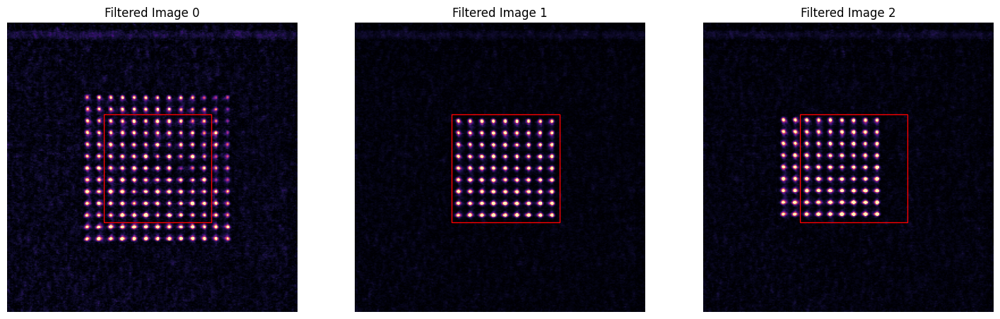

In [62]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [63]:
dataset_title = "rearrange_transport_exp_2_10um_dx_transport"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. 10 um transport in x direction.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_exp_2_10um_dx_transport' already exists. Renaming to 'rearrange_transport_exp_2_10um_dx_transport_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_2_10um_dx_transport_1


---
## Rearrangement + Transport Test 2 - 5 um dz Transport

Phasemask 2

In [65]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.88e-05 | Uniformity: 48.74% | Min/Max ratio: 0.021
Iteration 010 | Mean-Squared Error: 3.33e-07 | Uniformity: 84.23% | Min/Max ratio: 0.522
Iteration 020 | Mean-Squared Error: 2.56e-08 | Uniformity: 85.35% | Min/Max ratio: 0.562
Iteration 030 | Mean-Squared Error: 4.10e-08 | Uniformity: 85.34% | Min/Max ratio: 0.552
Iteration 040 | Mean-Squared Error: 2.39e-08 | Uniformity: 85.46% | Min/Max ratio: 0.559
Iteration 050 | Mean-Squared Error: 3.27e-09 | Uniformity: 85.17% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 3.14e-09 | Uniformity: 85.13% | Min/Max ratio: 0.566
Iteration 070 | Mean-Squared Error: 1.74e-09 | Uniformity: 85.11% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 8.35e-10 | Uniformity: 85.10% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 7.29e-10 | Uniformity: 85.10% | Min/Max ratio: 0.563
It

Phasemask 3

In [66]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

for i in range(len(z_n3)):
    if i % 2 == 0:
        z_n3[i] += 5.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.90e-05 | Uniformity: 55.23% | Min/Max ratio: 0.074
Iteration 010 | Mean-Squared Error: 5.68e-08 | Uniformity: 84.76% | Min/Max ratio: 0.540
Iteration 020 | Mean-Squared Error: 1.30e-08 | Uniformity: 85.34% | Min/Max ratio: 0.561
Iteration 030 | Mean-Squared Error: 6.23e-09 | Uniformity: 85.31% | Min/Max ratio: 0.560
Iteration 040 | Mean-Squared Error: 2.65e-09 | Uniformity: 85.17% | Min/Max ratio: 0.560
Iteration 050 | Mean-Squared Error: 1.84e-09 | Uniformity: 85.13% | Min/Max ratio: 0.561
Iteration 060 | Mean-Squared Error: 2.13e-09 | Uniformity: 85.11% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 2.50e-09 | Uniformity: 85.13% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 4.11e-09 | Uniformity: 85.19% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 6.40e-09 | Uniformity: 85.22% | Min/Max ratio: 0.564
It

In [67]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 11.1).
Transport node initialised.


In [68]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [71]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 24.8627 ms total
Transport complete: 6 frames, 7.0717 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 32 frames, 26.5025 ms total
Transport complete: 6 frames, 7.0317 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.3506 ms total
Transport complete: 6 frames, 6.0581 ms total
Images acquired from rearrangement n

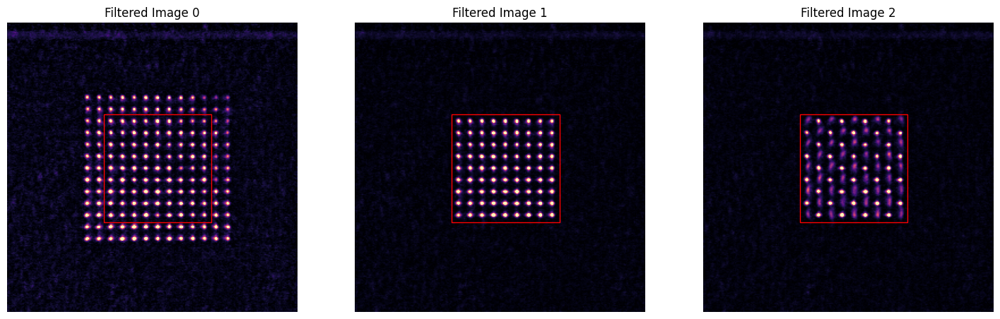

In [72]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [73]:
dataset_title = "rearrange_transport_exp_2_5um_dz_transport"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. 5 um transport in z direction for alternating traps.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_2_5um_dz_transport


---
## Rearrangement + Transport Test 2a - 5 um dz Global Transport

Phasemask 2

In [232]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.24e-05 | Uniformity: 52.62% | Min/Max ratio: 0.058
Iteration 010 | Mean-Squared Error: 2.75e-07 | Uniformity: 84.90% | Min/Max ratio: 0.517
Iteration 020 | Mean-Squared Error: 2.59e-08 | Uniformity: 85.03% | Min/Max ratio: 0.562
Iteration 030 | Mean-Squared Error: 8.19e-09 | Uniformity: 85.07% | Min/Max ratio: 0.556
Iteration 040 | Mean-Squared Error: 3.85e-09 | Uniformity: 85.05% | Min/Max ratio: 0.561
Iteration 050 | Mean-Squared Error: 1.17e-09 | Uniformity: 85.09% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 6.08e-10 | Uniformity: 85.12% | Min/Max ratio: 0.562
Iteration 070 | Mean-Squared Error: 5.19e-10 | Uniformity: 85.13% | Min/Max ratio: 0.562
Iteration 080 | Mean-Squared Error: 6.99e-10 | Uniformity: 85.15% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 1.17e-09 | Uniformity: 85.18% | Min/Max ratio: 0.563
It

Phasemask 3

In [238]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

for i in range(len(z_n3)):
    if i % 2 == 0:
        z_n3[i] += 10.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.61e-05 | Uniformity: 59.27% | Min/Max ratio: 0.110
Iteration 010 | Mean-Squared Error: 1.34e-07 | Uniformity: 84.66% | Min/Max ratio: 0.543
Iteration 020 | Mean-Squared Error: 3.08e-08 | Uniformity: 85.59% | Min/Max ratio: 0.573
Iteration 030 | Mean-Squared Error: 1.57e-08 | Uniformity: 85.32% | Min/Max ratio: 0.554
Iteration 040 | Mean-Squared Error: 1.58e-08 | Uniformity: 85.06% | Min/Max ratio: 0.558
Iteration 050 | Mean-Squared Error: 2.57e-09 | Uniformity: 85.06% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 1.60e-09 | Uniformity: 85.08% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 1.04e-09 | Uniformity: 85.13% | Min/Max ratio: 0.562
Iteration 080 | Mean-Squared Error: 6.35e-10 | Uniformity: 85.17% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 4.35e-10 | Uniformity: 85.19% | Min/Max ratio: 0.562
It

In [239]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 10.3).
Transport node initialised.


In [240]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [241]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 32 frames, 26.4398 ms total
Transport complete: 11 frames, 9.9304 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 33 frames, 26.5012 ms total
Transport complete: 11 frames, 9.8421 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.8172 ms total
Transport complete: 11 frames, 9.9549 ms total
Images acquired from rearrangemen

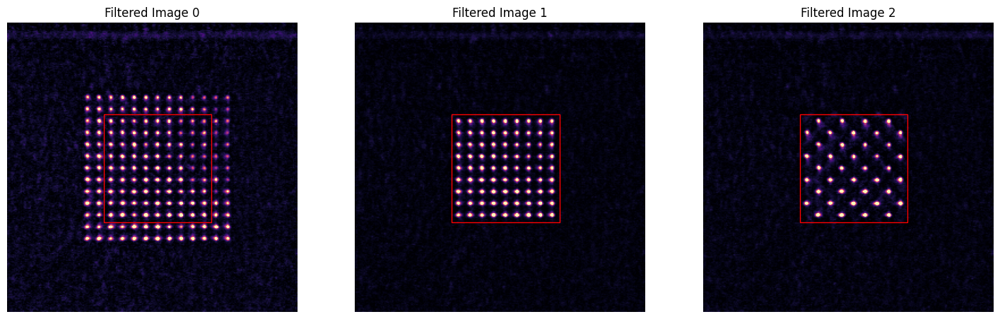

In [242]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [245]:
dataset_title = "rearrange_transport_exp_2_10um_dz_transport"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. 10 um transport in z direction for alternating traps.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_2_10um_dz_transport


---
## Rearrangement + Transport Test 2a - 2.5 um dz Global Transport

Phasemask 2

In [247]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.13e-05 | Uniformity: 47.50% | Min/Max ratio: 0.089
Iteration 010 | Mean-Squared Error: 2.79e-07 | Uniformity: 84.72% | Min/Max ratio: 0.535
Iteration 020 | Mean-Squared Error: 6.44e-08 | Uniformity: 85.49% | Min/Max ratio: 0.554
Iteration 030 | Mean-Squared Error: 2.00e-08 | Uniformity: 85.21% | Min/Max ratio: 0.557
Iteration 040 | Mean-Squared Error: 5.02e-09 | Uniformity: 85.12% | Min/Max ratio: 0.559
Iteration 050 | Mean-Squared Error: 2.56e-09 | Uniformity: 85.13% | Min/Max ratio: 0.563
Iteration 060 | Mean-Squared Error: 4.78e-09 | Uniformity: 85.05% | Min/Max ratio: 0.562
Iteration 070 | Mean-Squared Error: 2.63e-09 | Uniformity: 85.05% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.93e-09 | Uniformity: 85.11% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 2.16e-09 | Uniformity: 85.14% | Min/Max ratio: 0.562
It

Phasemask 3

In [248]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

for i in range(len(z_n3)):
    if i % 2 == 0:
        z_n3[i] += 2.5

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.29e-05 | Uniformity: 51.70% | Min/Max ratio: 0.051
Iteration 010 | Mean-Squared Error: 8.68e-08 | Uniformity: 85.44% | Min/Max ratio: 0.545
Iteration 020 | Mean-Squared Error: 3.01e-08 | Uniformity: 85.17% | Min/Max ratio: 0.557
Iteration 030 | Mean-Squared Error: 1.07e-08 | Uniformity: 85.03% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 3.18e-09 | Uniformity: 85.09% | Min/Max ratio: 0.562
Iteration 050 | Mean-Squared Error: 1.29e-09 | Uniformity: 85.17% | Min/Max ratio: 0.564
Iteration 060 | Mean-Squared Error: 9.48e-10 | Uniformity: 85.22% | Min/Max ratio: 0.567
Iteration 070 | Mean-Squared Error: 1.91e-09 | Uniformity: 85.29% | Min/Max ratio: 0.568
Iteration 080 | Mean-Squared Error: 2.18e-09 | Uniformity: 85.31% | Min/Max ratio: 0.568
Iteration 090 | Mean-Squared Error: 8.26e-10 | Uniformity: 85.24% | Min/Max ratio: 0.566
It

In [249]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 10.3).
Transport node initialised.


In [250]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [252]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 26.0380 ms total
Transport complete: 4 frames, 6.3282 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.0699 ms total
Transport complete: 4 frames, 6.0427 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.0171 ms total
Transport complete: 4 frames, 5.3453 ms total
Images acquired from rearrangement n

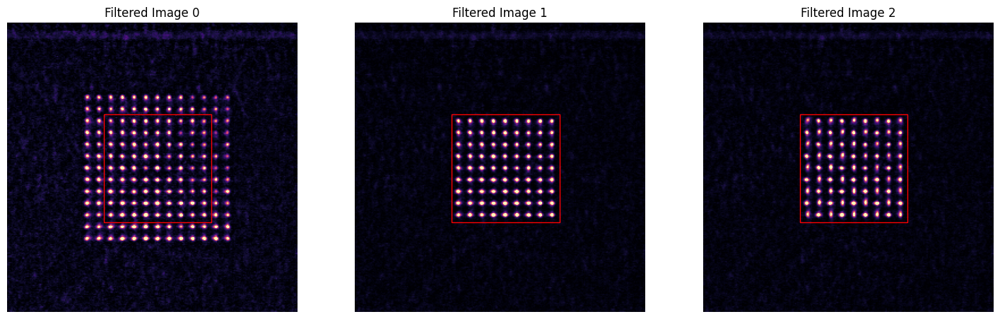

In [253]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [254]:
dataset_title = "rearrange_transport_exp_2_2_5um_dz_transport"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. 2.5 um transport in z direction for alternating traps.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_2_2_5um_dz_transport


---
## Rearrangement + Transport Test 2a - 7.5 um dz Global Transport

Phasemask 2

In [303]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 4.13e-05 | Uniformity: 41.43% | Min/Max ratio: 0.060
Iteration 010 | Mean-Squared Error: 3.44e-07 | Uniformity: 84.93% | Min/Max ratio: 0.524
Iteration 020 | Mean-Squared Error: 9.02e-08 | Uniformity: 84.60% | Min/Max ratio: 0.524
Iteration 030 | Mean-Squared Error: 3.82e-08 | Uniformity: 85.05% | Min/Max ratio: 0.557
Iteration 040 | Mean-Squared Error: 1.98e-08 | Uniformity: 85.11% | Min/Max ratio: 0.561
Iteration 050 | Mean-Squared Error: 3.34e-08 | Uniformity: 85.44% | Min/Max ratio: 0.558
Iteration 060 | Mean-Squared Error: 4.87e-09 | Uniformity: 85.11% | Min/Max ratio: 0.557
Iteration 070 | Mean-Squared Error: 1.33e-09 | Uniformity: 85.12% | Min/Max ratio: 0.561
Iteration 080 | Mean-Squared Error: 7.71e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 8.37e-10 | Uniformity: 85.17% | Min/Max ratio: 0.564
It

Phasemask 3

In [304]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

for i in range(len(z_n3)):
    if i % 2 == 0:
        z_n3[i] += 7.5

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.02e-05 | Uniformity: 54.86% | Min/Max ratio: 0.124
Iteration 010 | Mean-Squared Error: 1.43e-07 | Uniformity: 84.61% | Min/Max ratio: 0.532
Iteration 020 | Mean-Squared Error: 2.64e-08 | Uniformity: 85.45% | Min/Max ratio: 0.556
Iteration 030 | Mean-Squared Error: 3.79e-09 | Uniformity: 85.21% | Min/Max ratio: 0.560
Iteration 040 | Mean-Squared Error: 2.21e-09 | Uniformity: 85.14% | Min/Max ratio: 0.563
Iteration 050 | Mean-Squared Error: 1.25e-09 | Uniformity: 85.14% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 6.56e-10 | Uniformity: 85.14% | Min/Max ratio: 0.566
Iteration 070 | Mean-Squared Error: 3.89e-10 | Uniformity: 85.15% | Min/Max ratio: 0.566
Iteration 080 | Mean-Squared Error: 2.79e-10 | Uniformity: 85.16% | Min/Max ratio: 0.565
Iteration 090 | Mean-Squared Error: 2.59e-10 | Uniformity: 85.16% | Min/Max ratio: 0.564
It

In [305]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])


await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 9.5).
Transport node initialised.


In [306]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [309]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 27.8493 ms total
Transport complete: 9 frames, 10.6837 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.0254 ms total
Transport complete: 9 frames, 9.3697 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.9585 ms total
Transport complete: 9 frames, 8.9083 ms total
Images acquired from rearrangement 

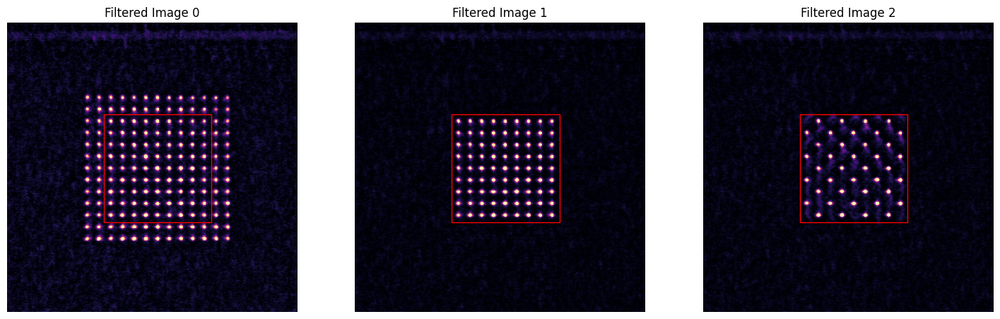

In [310]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

#### Save Data

In [311]:
dataset_title = "rearrange_transport_exp_2_7_5um_dz_transport"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Single shot. 7.5 um transport in z direction for alternating traps.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_exp_2_7_5um_dz_transport' already exists. Renaming to 'rearrange_transport_exp_2_7_5um_dz_transport_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_exp_2_7_5um_dz_transport_1


---
## Rearrangement + Transport Test 3 - 1 um dz Back and Forth Transport

In [132]:
def extract_survival_probability(imgs1, imgs2, grid_positions1, grid_positions2, threshold='auto', window_size=5):
    if threshold == 'auto':
        pr_1, eta_1, thresh_1, fidelity_1 = an.get_array_loading_statistics(imgs1, grid_positions1, threshold_detection=True, window_size=window_size, binning=60, show_histogram=False, verbose=False)
        pr_2, eta_2, thresh_2, fidelity_2 = an.get_array_loading_statistics(imgs2, grid_positions2, threshold_detection=True, window_size=window_size, binning=60, show_histogram=False, verbose=False)
    else:
        pr_1, eta_1, thresh_1, fidelity_1 = an.get_array_loading_statistics(imgs1, grid_positions1, threshold_detection=False, threshold=threshold, window_size=window_size, binning=60, show_histogram=False, verbose=False)
        pr_2, eta_2, thresh_2, fidelity_2 = an.get_array_loading_statistics(imgs2, grid_positions2, threshold_detection=False, threshold=threshold, window_size=window_size, binning=60, show_histogram=False, verbose=False)
    survival_fractions = []
    for i in range(pr_1.shape[0]):

        pr_mat_1 = pr_1[i]
        pr_mat_2 = pr_2[i]

        pr_mat_1_binary = (pr_mat_1 > thresh_1).astype(int)
        pr_mat_2_binary = (pr_mat_2 > thresh_2).astype(int)
        survival_matrix = pr_mat_1_binary * pr_mat_2_binary

        init_occupation = pr_mat_1_binary.sum()
        final_occupation = pr_mat_2_binary.sum()
        survival_count = survival_matrix.sum()
        survival_fraction = survival_count / init_occupation if init_occupation > 0 else 0
        survival_fractions.append(survival_fraction)

    survival_probability = np.mean(survival_fractions)
    return survival_probability

Phasemask 2

In [96]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.66e-05 | Uniformity: 61.19% | Min/Max ratio: 0.133
Iteration 010 | Mean-Squared Error: 1.19e-07 | Uniformity: 84.70% | Min/Max ratio: 0.552
Iteration 020 | Mean-Squared Error: 2.62e-08 | Uniformity: 85.13% | Min/Max ratio: 0.562
Iteration 030 | Mean-Squared Error: 2.94e-09 | Uniformity: 85.19% | Min/Max ratio: 0.565
Iteration 040 | Mean-Squared Error: 2.01e-09 | Uniformity: 85.22% | Min/Max ratio: 0.565
Iteration 050 | Mean-Squared Error: 1.92e-09 | Uniformity: 85.21% | Min/Max ratio: 0.564
Iteration 060 | Mean-Squared Error: 1.69e-09 | Uniformity: 85.18% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 3.94e-09 | Uniformity: 85.16% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 5.35e-09 | Uniformity: 85.12% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 2.21e-09 | Uniformity: 85.13% | Min/Max ratio: 0.562
It

Phasemask 3

In [97]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.58e-05 | Uniformity: 52.52% | Min/Max ratio: 0.091
Iteration 010 | Mean-Squared Error: 1.72e-07 | Uniformity: 84.52% | Min/Max ratio: 0.506
Iteration 020 | Mean-Squared Error: 8.61e-08 | Uniformity: 85.29% | Min/Max ratio: 0.560
Iteration 030 | Mean-Squared Error: 2.69e-08 | Uniformity: 85.30% | Min/Max ratio: 0.565
Iteration 040 | Mean-Squared Error: 9.40e-09 | Uniformity: 85.08% | Min/Max ratio: 0.572
Iteration 050 | Mean-Squared Error: 7.61e-09 | Uniformity: 85.10% | Min/Max ratio: 0.569
Iteration 060 | Mean-Squared Error: 6.27e-09 | Uniformity: 85.18% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 2.46e-09 | Uniformity: 85.23% | Min/Max ratio: 0.558
Iteration 080 | Mean-Squared Error: 1.72e-09 | Uniformity: 85.24% | Min/Max ratio: 0.558
Iteration 090 | Mean-Squared Error: 1.40e-09 | Uniformity: 85.23% | Min/Max ratio: 0.559
It

In [120]:
DZ = 1.0

In [121]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [122]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [123]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 26.5977 ms total
Transport complete: 30 frames, 26.0699 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.8853 ms total
Transport complete: 30 frames, 25.7880 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 24.7319 ms total
Transport complete: 30 frames, 25.8280 ms total
Images acquired from rearrange

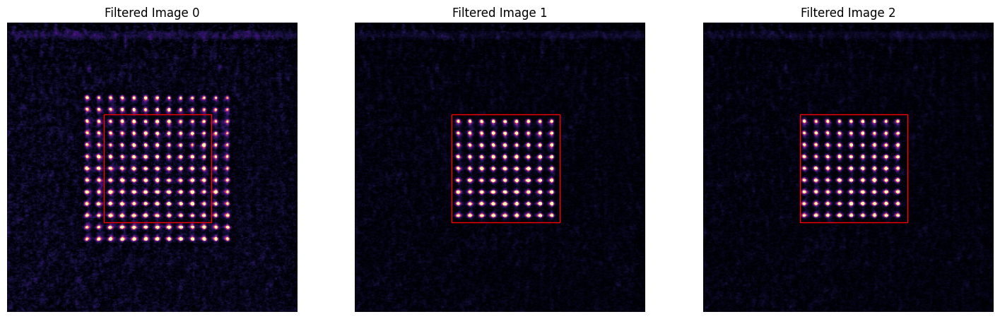

In [124]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 93.00 %
Trap (5) Loading Probability : 99.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 95.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 93.00 %
Trap (10) Loading Probability : 98.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 95.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 97.00 %
Trap (15) Loading Probability : 99.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 99.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 91.00 %
Trap (20) Loading Probability : 96.00 %
Trap (21) Loading Probability : 95.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 91.00 %
Trap 

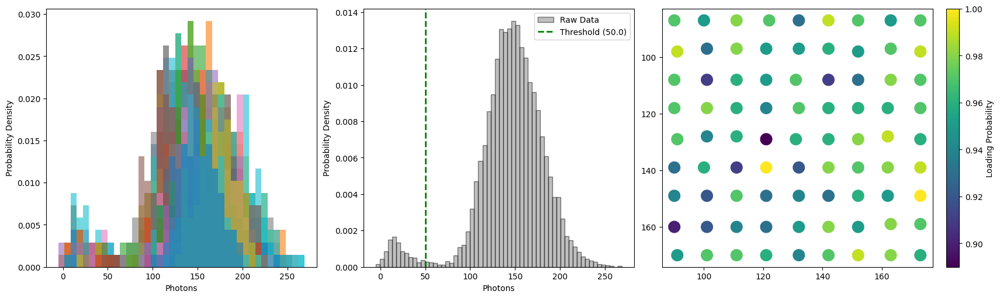

In [126]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 90.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 92.00 %
Trap (4) Loading Probability : 90.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 91.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 91.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 90.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 92.00 %
Trap (14) Loading Probability : 94.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 93.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 86.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 90.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 87.00 %
Trap 

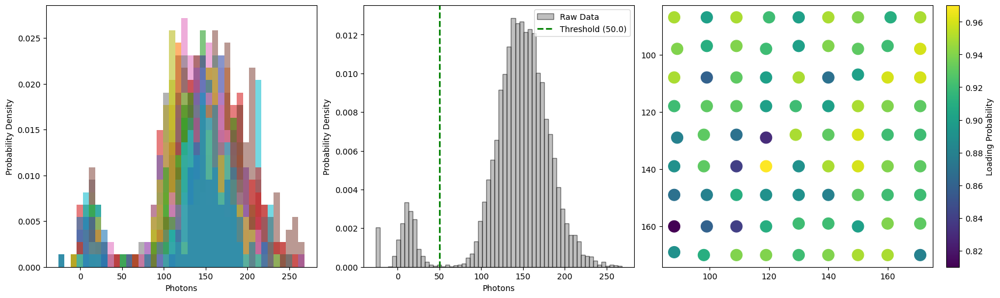

In [127]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [133]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9428


#### Save Data

In [134]:
dataset_title = "rearrange_transport_dz_1um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 1 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_1um_survival_probability


---
## Rearrangement + Transport Test 3 - 0 um dz Back and Forth Transport

Phasemask 2

In [184]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.43e-05 | Uniformity: 45.90% | Min/Max ratio: 0.092
Iteration 010 | Mean-Squared Error: 2.28e-07 | Uniformity: 84.21% | Min/Max ratio: 0.512
Iteration 020 | Mean-Squared Error: 5.97e-08 | Uniformity: 84.66% | Min/Max ratio: 0.552
Iteration 030 | Mean-Squared Error: 2.97e-08 | Uniformity: 84.92% | Min/Max ratio: 0.529
Iteration 040 | Mean-Squared Error: 5.92e-09 | Uniformity: 85.26% | Min/Max ratio: 0.558
Iteration 050 | Mean-Squared Error: 5.14e-10 | Uniformity: 85.19% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 2.41e-10 | Uniformity: 85.16% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 2.16e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 2.19e-10 | Uniformity: 85.16% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 2.79e-10 | Uniformity: 85.16% | Min/Max ratio: 0.564
It

Phasemask 3

In [185]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.83e-05 | Uniformity: 60.13% | Min/Max ratio: 0.125
Iteration 010 | Mean-Squared Error: 1.64e-07 | Uniformity: 84.55% | Min/Max ratio: 0.516
Iteration 020 | Mean-Squared Error: 6.42e-08 | Uniformity: 85.07% | Min/Max ratio: 0.570
Iteration 030 | Mean-Squared Error: 3.43e-08 | Uniformity: 84.68% | Min/Max ratio: 0.538
Iteration 040 | Mean-Squared Error: 9.37e-09 | Uniformity: 85.06% | Min/Max ratio: 0.563
Iteration 050 | Mean-Squared Error: 1.66e-09 | Uniformity: 85.17% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 1.76e-09 | Uniformity: 85.22% | Min/Max ratio: 0.562
Iteration 070 | Mean-Squared Error: 4.97e-09 | Uniformity: 85.31% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.06e-08 | Uniformity: 85.42% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 3.49e-09 | Uniformity: 85.30% | Min/Max ratio: 0.564
It

In [186]:
DZ = 0.0

In [187]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [188]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [189]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.5600 ms total
Transport complete: 12 frames, 13.3388 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 38 frames, 30.7267 ms total
Transport complete: 12 frames, 12.3506 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.4953 ms total
Transport complete: 12 frames, 13.0219 ms total
Images acquired from rearrange

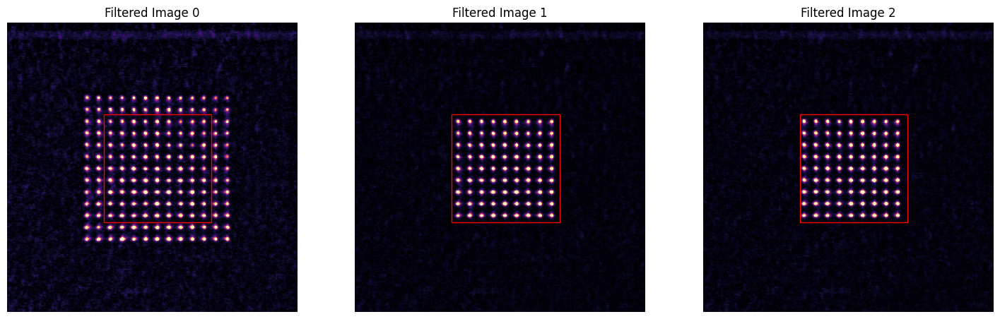

In [190]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 100.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 100.00 %
Trap (6) Loading Probability : 96.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 99.00 %
Trap (11) Loading Probability : 93.00 %
Trap (12) Loading Probability : 99.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 94.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 97.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 99.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 97.00 %
Tra

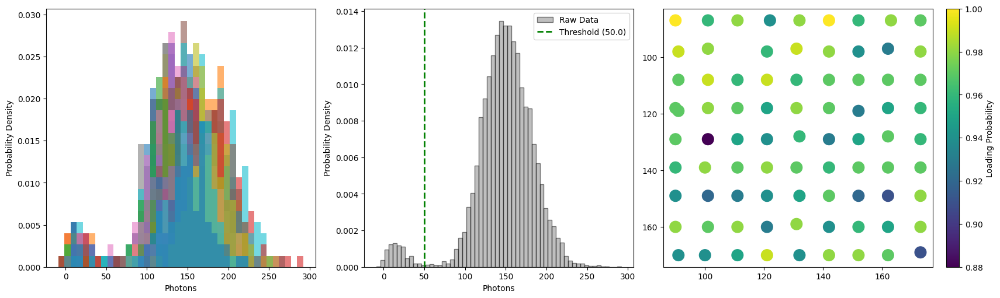

In [191]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 95.00 %
Trap (3) Loading Probability : 89.00 %
Trap (4) Loading Probability : 97.00 %
Trap (5) Loading Probability : 100.00 %
Trap (6) Loading Probability : 95.00 %
Trap (7) Loading Probability : 94.00 %
Trap (8) Loading Probability : 94.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 94.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 91.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 93.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 92.00 %
Trap (23) Loading Probability : 93.00 %
Trap

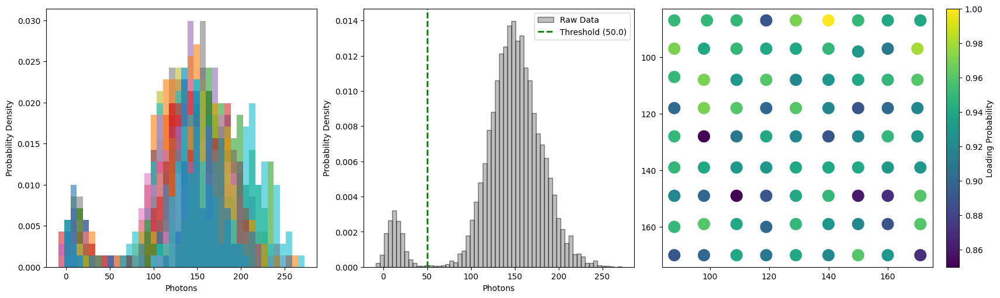

In [192]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [193]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9456


#### Save Data

In [194]:
dataset_title = "rearrange_transport_dz_0um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 0 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_0um_survival_probability


---
## Rearrangement + Transport Test 3 - 2 um dz Back and Forth Transport

Phasemask 2

In [135]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.14e-05 | Uniformity: 55.92% | Min/Max ratio: 0.142
Iteration 010 | Mean-Squared Error: 2.18e-07 | Uniformity: 85.21% | Min/Max ratio: 0.552
Iteration 020 | Mean-Squared Error: 8.61e-08 | Uniformity: 85.57% | Min/Max ratio: 0.573
Iteration 030 | Mean-Squared Error: 4.15e-09 | Uniformity: 85.26% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 9.31e-10 | Uniformity: 85.20% | Min/Max ratio: 0.562
Iteration 050 | Mean-Squared Error: 6.57e-10 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 1.33e-09 | Uniformity: 85.20% | Min/Max ratio: 0.561
Iteration 070 | Mean-Squared Error: 2.02e-09 | Uniformity: 85.19% | Min/Max ratio: 0.560
Iteration 080 | Mean-Squared Error: 1.17e-09 | Uniformity: 85.18% | Min/Max ratio: 0.561
Iteration 090 | Mean-Squared Error: 4.69e-10 | Uniformity: 85.18% | Min/Max ratio: 0.562
It

Phasemask 3

In [136]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.30e-05 | Uniformity: 52.28% | Min/Max ratio: 0.065
Iteration 010 | Mean-Squared Error: 1.59e-07 | Uniformity: 84.99% | Min/Max ratio: 0.556
Iteration 020 | Mean-Squared Error: 5.24e-08 | Uniformity: 85.12% | Min/Max ratio: 0.542
Iteration 030 | Mean-Squared Error: 3.32e-08 | Uniformity: 84.95% | Min/Max ratio: 0.537
Iteration 040 | Mean-Squared Error: 1.38e-08 | Uniformity: 85.14% | Min/Max ratio: 0.558
Iteration 050 | Mean-Squared Error: 1.14e-08 | Uniformity: 85.21% | Min/Max ratio: 0.564
Iteration 060 | Mean-Squared Error: 5.57e-09 | Uniformity: 85.16% | Min/Max ratio: 0.566
Iteration 070 | Mean-Squared Error: 1.10e-09 | Uniformity: 85.14% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 1.94e-10 | Uniformity: 85.16% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 5.78e-11 | Uniformity: 85.17% | Min/Max ratio: 0.564
It

In [137]:
DZ = 2.0

In [138]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [139]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [140]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.5606 ms total
Transport complete: 31 frames, 27.5802 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.1283 ms total
Transport complete: 31 frames, 26.8335 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.9353 ms total
Transport complete: 31 frames, 26.6127 ms total
Images acquired from rearrange

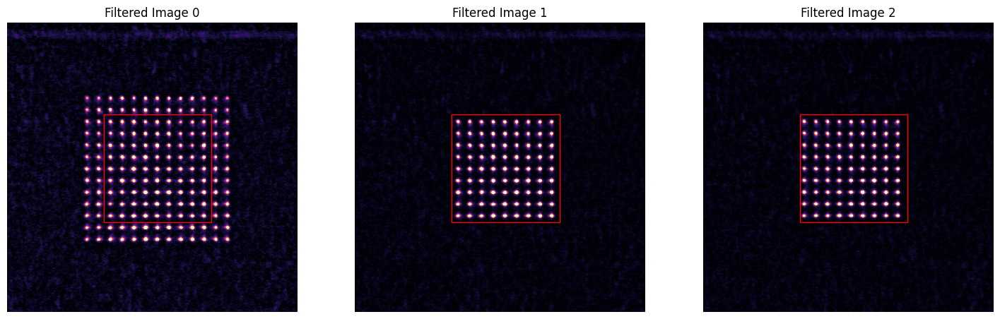

In [145]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 100.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 94.00 %
Trap (3) Loading Probability : 95.00 %
Trap (4) Loading Probability : 97.00 %
Trap (5) Loading Probability : 98.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 97.00 %
Trap (12) Loading Probability : 99.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 99.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 95.00 %
Trap (18) Loading Probability : 98.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 99.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 93.00 %
Trap

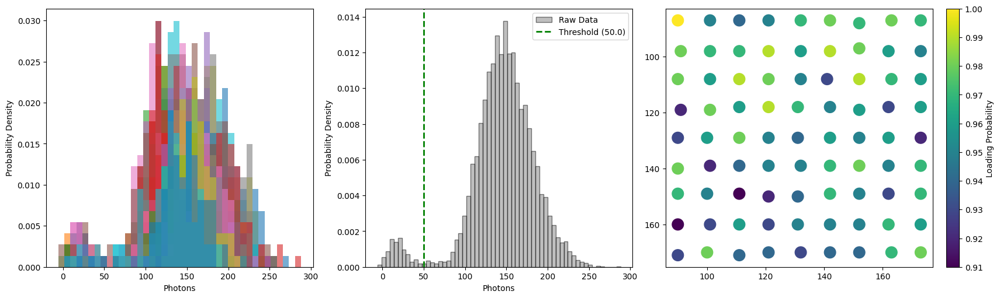

In [142]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 94.00 %
Trap (2) Loading Probability : 90.00 %
Trap (3) Loading Probability : 92.00 %
Trap (4) Loading Probability : 94.00 %
Trap (5) Loading Probability : 91.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 94.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 91.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 94.00 %
Trap (17) Loading Probability : 91.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 98.00 %
Trap (21) Loading Probability : 94.00 %
Trap (22) Loading Probability : 92.00 %
Trap (23) Loading Probability : 92.00 %
Trap 

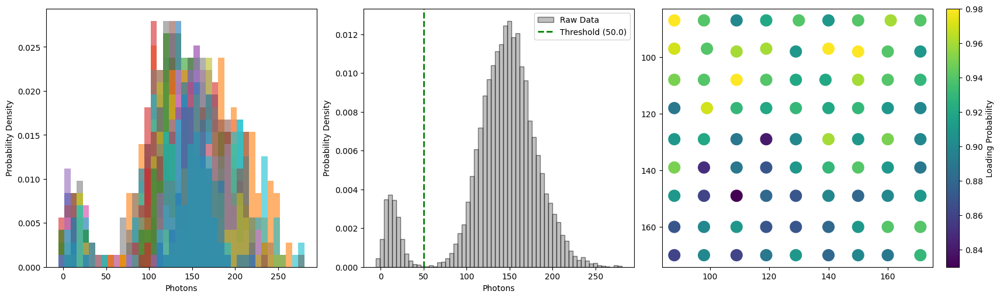

In [143]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [144]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9271


#### Save Data

In [146]:
dataset_title = "rearrange_transport_dz_2um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 2 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_2um_survival_probability


---
## Rearrangement + Transport Test 3 - 3 um dz Back and Forth Transport

Phasemask 2

In [147]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.95e-05 | Uniformity: 57.44% | Min/Max ratio: 0.112
Iteration 010 | Mean-Squared Error: 1.25e-07 | Uniformity: 84.85% | Min/Max ratio: 0.518
Iteration 020 | Mean-Squared Error: 1.41e-08 | Uniformity: 85.01% | Min/Max ratio: 0.550
Iteration 030 | Mean-Squared Error: 1.50e-08 | Uniformity: 85.03% | Min/Max ratio: 0.551
Iteration 040 | Mean-Squared Error: 9.58e-09 | Uniformity: 85.11% | Min/Max ratio: 0.560
Iteration 050 | Mean-Squared Error: 2.97e-08 | Uniformity: 84.94% | Min/Max ratio: 0.551
Iteration 060 | Mean-Squared Error: 3.45e-08 | Uniformity: 85.02% | Min/Max ratio: 0.567
Iteration 070 | Mean-Squared Error: 5.29e-09 | Uniformity: 85.09% | Min/Max ratio: 0.559
Iteration 080 | Mean-Squared Error: 6.84e-10 | Uniformity: 85.15% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 1.02e-10 | Uniformity: 85.17% | Min/Max ratio: 0.563
It

Phasemask 3

In [148]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.19e-05 | Uniformity: 46.76% | Min/Max ratio: 0.057
Iteration 010 | Mean-Squared Error: 2.29e-07 | Uniformity: 84.56% | Min/Max ratio: 0.498
Iteration 020 | Mean-Squared Error: 1.01e-07 | Uniformity: 85.83% | Min/Max ratio: 0.541
Iteration 030 | Mean-Squared Error: 7.97e-09 | Uniformity: 85.19% | Min/Max ratio: 0.570
Iteration 040 | Mean-Squared Error: 2.72e-09 | Uniformity: 85.14% | Min/Max ratio: 0.565
Iteration 050 | Mean-Squared Error: 1.33e-09 | Uniformity: 85.13% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 6.56e-10 | Uniformity: 85.14% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 3.33e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.91e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 1.22e-10 | Uniformity: 85.16% | Min/Max ratio: 0.563
It

In [151]:
DZ = 3.0

In [152]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [153]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [154]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.4302 ms total
Transport complete: 31 frames, 26.0750 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.9475 ms total
Transport complete: 31 frames, 25.5417 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 38 frames, 31.0994 ms total
Transport complete: 31 frames, 26.7054 ms total
Images acquired from rearrange

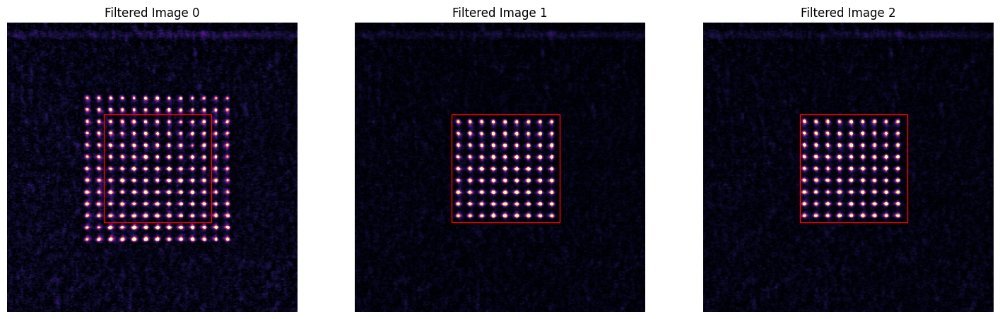

In [155]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 96.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 98.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 94.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 99.00 %
Trap (8) Loading Probability : 93.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 99.00 %
Trap (11) Loading Probability : 97.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 97.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 98.00 %
Trap (20) Loading Probability : 94.00 %
Trap (21) Loading Probability : 99.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 98.00 %
Trap 

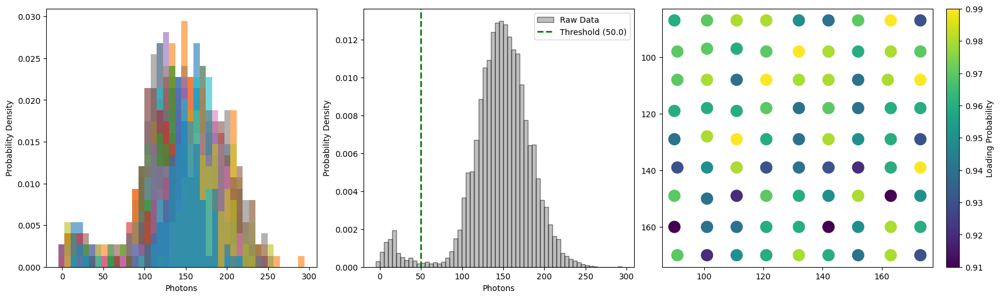

In [156]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 89.00 %
Trap (1) Loading Probability : 92.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 87.00 %
Trap (4) Loading Probability : 94.00 %
Trap (5) Loading Probability : 88.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 88.00 %
Trap (8) Loading Probability : 93.00 %
Trap (9) Loading Probability : 90.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 89.00 %
Trap (13) Loading Probability : 92.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 89.00 %
Trap (16) Loading Probability : 84.00 %
Trap (17) Loading Probability : 91.00 %
Trap (18) Loading Probability : 93.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 91.00 %
Trap (21) Loading Probability : 94.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 90.00 %
Trap 

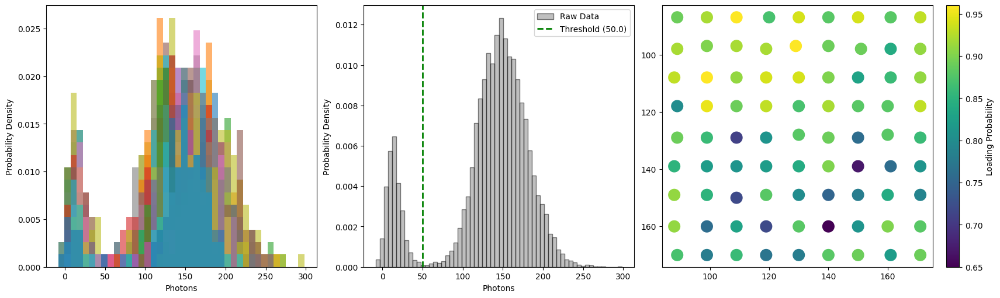

In [157]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [158]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8875


#### Save Data

In [159]:
dataset_title = "rearrange_transport_dz_3um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 3 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_3um_survival_probability


---
## Rearrangement + Transport Test 3 - 4 um dz Back and Forth Transport

Phasemask 2

In [182]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.03e-05 | Uniformity: 55.16% | Min/Max ratio: 0.092
Iteration 010 | Mean-Squared Error: 1.36e-07 | Uniformity: 84.39% | Min/Max ratio: 0.578
Iteration 020 | Mean-Squared Error: 9.02e-08 | Uniformity: 85.59% | Min/Max ratio: 0.575
Iteration 030 | Mean-Squared Error: 7.72e-09 | Uniformity: 85.15% | Min/Max ratio: 0.566
Iteration 040 | Mean-Squared Error: 2.96e-09 | Uniformity: 85.24% | Min/Max ratio: 0.565
Iteration 050 | Mean-Squared Error: 1.06e-08 | Uniformity: 85.29% | Min/Max ratio: 0.565
Iteration 060 | Mean-Squared Error: 1.64e-08 | Uniformity: 84.79% | Min/Max ratio: 0.547
Iteration 070 | Mean-Squared Error: 7.04e-09 | Uniformity: 84.95% | Min/Max ratio: 0.556
Iteration 080 | Mean-Squared Error: 3.43e-09 | Uniformity: 85.07% | Min/Max ratio: 0.558
Iteration 090 | Mean-Squared Error: 6.81e-10 | Uniformity: 85.13% | Min/Max ratio: 0.563
It

Phasemask 3

In [183]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.93e-05 | Uniformity: 58.34% | Min/Max ratio: 0.122
Iteration 010 | Mean-Squared Error: 1.70e-07 | Uniformity: 84.74% | Min/Max ratio: 0.528
Iteration 020 | Mean-Squared Error: 4.73e-08 | Uniformity: 84.91% | Min/Max ratio: 0.561
Iteration 030 | Mean-Squared Error: 8.13e-09 | Uniformity: 85.18% | Min/Max ratio: 0.556
Iteration 040 | Mean-Squared Error: 2.31e-09 | Uniformity: 85.21% | Min/Max ratio: 0.560
Iteration 050 | Mean-Squared Error: 1.77e-09 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 1.51e-09 | Uniformity: 85.16% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 8.49e-10 | Uniformity: 85.16% | Min/Max ratio: 0.564
Iteration 080 | Mean-Squared Error: 3.65e-10 | Uniformity: 85.16% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 1.65e-10 | Uniformity: 85.17% | Min/Max ratio: 0.564
It

In [162]:
DZ = 4.0

In [163]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [164]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [165]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.3119 ms total
Transport complete: 31 frames, 26.2524 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.9019 ms total
Transport complete: 31 frames, 26.1754 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.7483 ms total
Transport complete: 31 frames, 26.1949 ms total
Images acquired from rearrange

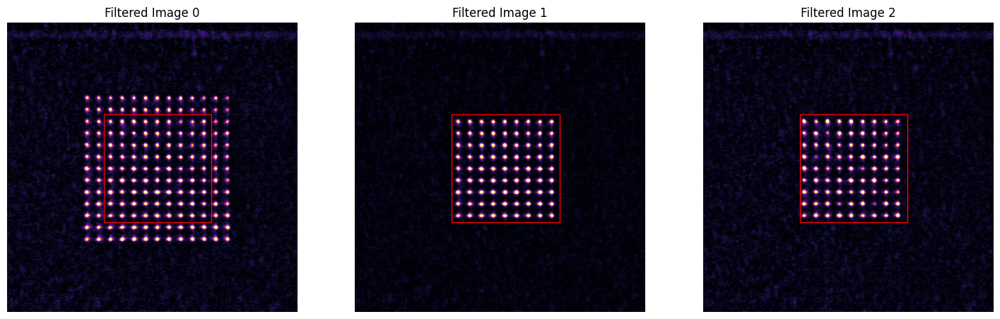

In [166]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 99.00 %
Trap (1) Loading Probability : 98.00 %
Trap (2) Loading Probability : 99.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 98.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 99.00 %
Trap (9) Loading Probability : 95.00 %
Trap (10) Loading Probability : 99.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 97.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 98.00 %
Trap (21) Loading Probability : 95.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 97.00 %
Trap 

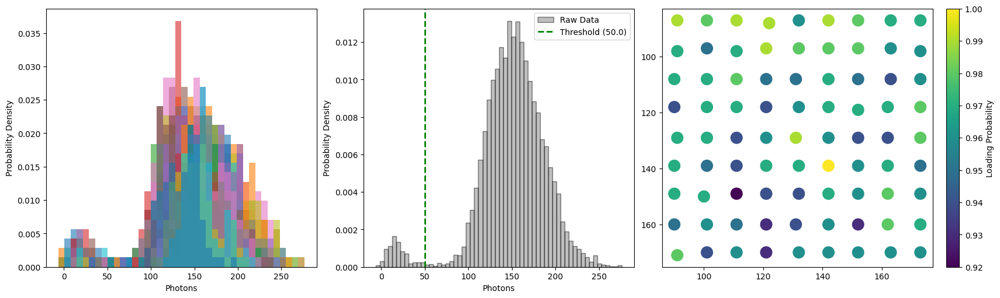

In [167]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 74.00 %
Trap (1) Loading Probability : 51.00 %
Trap (2) Loading Probability : 85.00 %
Trap (3) Loading Probability : 73.00 %
Trap (4) Loading Probability : 79.00 %
Trap (5) Loading Probability : 67.00 %
Trap (6) Loading Probability : 66.00 %
Trap (7) Loading Probability : 59.00 %
Trap (8) Loading Probability : 55.00 %
Trap (9) Loading Probability : 66.00 %
Trap (10) Loading Probability : 60.00 %
Trap (11) Loading Probability : 73.00 %
Trap (12) Loading Probability : 33.00 %
Trap (13) Loading Probability : 81.00 %
Trap (14) Loading Probability : 74.00 %
Trap (15) Loading Probability : 67.00 %
Trap (16) Loading Probability : 48.00 %
Trap (17) Loading Probability : 46.00 %
Trap (18) Loading Probability : 61.00 %
Trap (19) Loading Probability : 59.00 %
Trap (20) Loading Probability : 67.00 %
Trap (21) Loading Probability : 43.00 %
Trap (22) Loading Probability : 48.00 %
Trap (23) Loading Probability : 58.00 %
Trap 

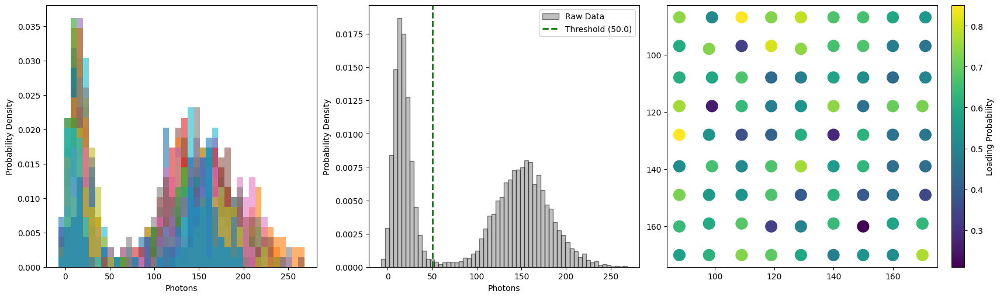

In [168]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [169]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.5792


#### Save Data

In [170]:
dataset_title = "rearrange_transport_dz_4um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 4 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_4um_survival_probability


---
## Rearrangement + Transport Test 3 - 5 um dz Back and Forth Transport

Phasemask 2

In [195]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.05e-05 | Uniformity: 55.55% | Min/Max ratio: 0.084
Iteration 010 | Mean-Squared Error: 1.09e-07 | Uniformity: 85.09% | Min/Max ratio: 0.546
Iteration 020 | Mean-Squared Error: 2.81e-08 | Uniformity: 85.28% | Min/Max ratio: 0.545
Iteration 030 | Mean-Squared Error: 8.07e-09 | Uniformity: 85.27% | Min/Max ratio: 0.560
Iteration 040 | Mean-Squared Error: 5.72e-09 | Uniformity: 85.25% | Min/Max ratio: 0.561
Iteration 050 | Mean-Squared Error: 2.24e-09 | Uniformity: 85.26% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 3.29e-09 | Uniformity: 85.30% | Min/Max ratio: 0.564
Iteration 070 | Mean-Squared Error: 6.42e-09 | Uniformity: 85.23% | Min/Max ratio: 0.565
Iteration 080 | Mean-Squared Error: 7.67e-09 | Uniformity: 85.01% | Min/Max ratio: 0.559
Iteration 090 | Mean-Squared Error: 2.64e-09 | Uniformity: 84.99% | Min/Max ratio: 0.560
It

Phasemask 3

In [196]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.91e-05 | Uniformity: 58.49% | Min/Max ratio: 0.096
Iteration 010 | Mean-Squared Error: 1.86e-07 | Uniformity: 85.36% | Min/Max ratio: 0.536
Iteration 020 | Mean-Squared Error: 2.39e-08 | Uniformity: 84.96% | Min/Max ratio: 0.559
Iteration 030 | Mean-Squared Error: 1.86e-08 | Uniformity: 84.99% | Min/Max ratio: 0.553
Iteration 040 | Mean-Squared Error: 8.77e-09 | Uniformity: 84.92% | Min/Max ratio: 0.554
Iteration 050 | Mean-Squared Error: 5.24e-09 | Uniformity: 84.98% | Min/Max ratio: 0.557
Iteration 060 | Mean-Squared Error: 6.55e-09 | Uniformity: 84.98% | Min/Max ratio: 0.556
Iteration 070 | Mean-Squared Error: 5.18e-09 | Uniformity: 85.07% | Min/Max ratio: 0.559
Iteration 080 | Mean-Squared Error: 2.69e-09 | Uniformity: 85.12% | Min/Max ratio: 0.561
Iteration 090 | Mean-Squared Error: 6.12e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
It

In [197]:
DZ = 5.0

In [198]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [199]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [200]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 24.8864 ms total
Transport complete: 31 frames, 25.8696 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.7387 ms total
Transport complete: 31 frames, 27.4691 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.1341 ms total
Transport complete: 31 frames, 26.1968 ms total
Images acquired from rearrange

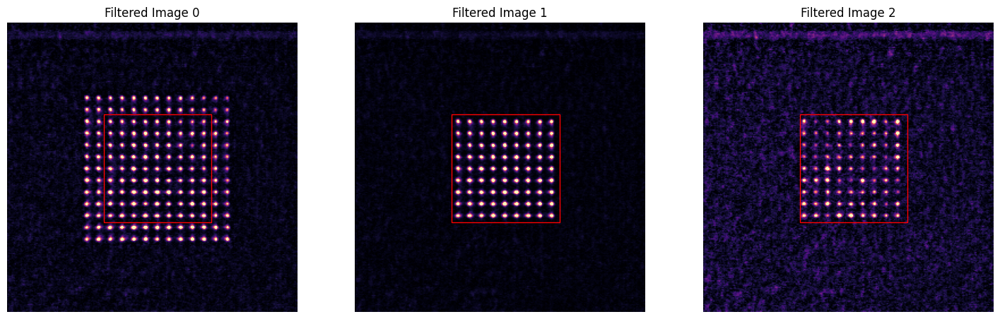

In [201]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 99.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 100.00 %
Trap (7) Loading Probability : 100.00 %
Trap (8) Loading Probability : 99.00 %
Trap (9) Loading Probability : 100.00 %
Trap (10) Loading Probability : 95.00 %
Trap (11) Loading Probability : 99.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 99.00 %
Trap (17) Loading Probability : 98.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 92.00 %
Trap (24) Loading Probability : 95.00 %
Trap (2

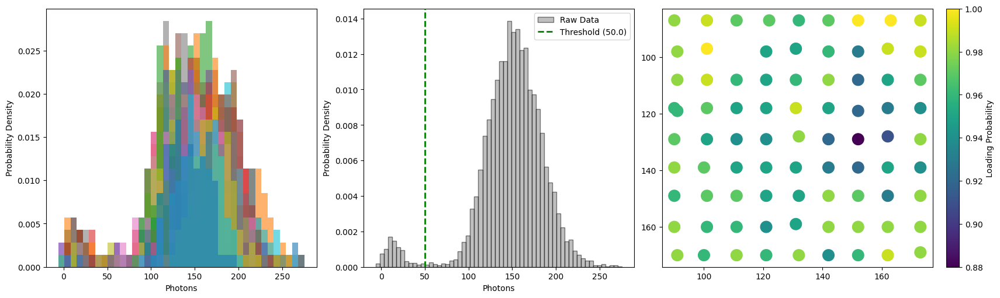

In [202]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 27.00 %
Trap (1) Loading Probability : 11.00 %
Trap (2) Loading Probability : 13.00 %
Trap (3) Loading Probability : 30.00 %
Trap (4) Loading Probability : 32.00 %
Trap (5) Loading Probability : 41.00 %
Trap (6) Loading Probability : 43.00 %
Trap (7) Loading Probability : 16.00 %
Trap (8) Loading Probability : 44.00 %
Trap (9) Loading Probability : 22.00 %
Trap (10) Loading Probability : 15.00 %
Trap (11) Loading Probability : 14.00 %
Trap (12) Loading Probability : 16.00 %
Trap (13) Loading Probability : 19.00 %
Trap (14) Loading Probability : 17.00 %
Trap (15) Loading Probability : 18.00 %
Trap (16) Loading Probability : 46.00 %
Trap (17) Loading Probability : 16.00 %
Trap (18) Loading Probability : 16.00 %
Trap (19) Loading Probability : 10.00 %
Trap (20) Loading Probability : 11.00 %
Trap (21) Loading Probability : 19.00 %
Trap (22) Loading Probability : 9.00 %
Trap (23) Loading Probability : 19.00 %
Trap (24) Loading Probability : 21.00 %
Trap (25) L

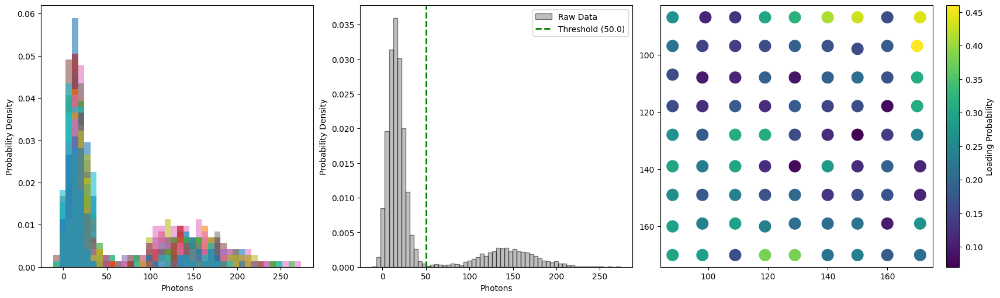

In [203]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [204]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.2110


#### Save Data

In [205]:
dataset_title = "rearrange_transport_dz_5um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 5 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_5um_survival_probability


---
## Rearrangement + Transport Test 3 - 6 um dz Back and Forth Transport

Phasemask 2

In [206]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.95e-05 | Uniformity: 58.17% | Min/Max ratio: 0.161
Iteration 010 | Mean-Squared Error: 1.89e-07 | Uniformity: 84.32% | Min/Max ratio: 0.523
Iteration 020 | Mean-Squared Error: 8.54e-08 | Uniformity: 84.40% | Min/Max ratio: 0.538
Iteration 030 | Mean-Squared Error: 8.65e-09 | Uniformity: 85.34% | Min/Max ratio: 0.559
Iteration 040 | Mean-Squared Error: 4.87e-09 | Uniformity: 85.35% | Min/Max ratio: 0.564
Iteration 050 | Mean-Squared Error: 2.77e-09 | Uniformity: 85.30% | Min/Max ratio: 0.564
Iteration 060 | Mean-Squared Error: 4.12e-09 | Uniformity: 85.28% | Min/Max ratio: 0.560
Iteration 070 | Mean-Squared Error: 4.54e-09 | Uniformity: 85.27% | Min/Max ratio: 0.558
Iteration 080 | Mean-Squared Error: 1.17e-09 | Uniformity: 85.20% | Min/Max ratio: 0.560
Iteration 090 | Mean-Squared Error: 7.59e-10 | Uniformity: 85.15% | Min/Max ratio: 0.562
It

Phasemask 3

In [207]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 1.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.26e-05 | Uniformity: 53.86% | Min/Max ratio: 0.112
Iteration 010 | Mean-Squared Error: 2.62e-07 | Uniformity: 84.78% | Min/Max ratio: 0.510
Iteration 020 | Mean-Squared Error: 5.05e-08 | Uniformity: 85.22% | Min/Max ratio: 0.563
Iteration 030 | Mean-Squared Error: 6.64e-09 | Uniformity: 85.31% | Min/Max ratio: 0.562
Iteration 040 | Mean-Squared Error: 1.73e-09 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 050 | Mean-Squared Error: 5.22e-09 | Uniformity: 85.16% | Min/Max ratio: 0.562
Iteration 060 | Mean-Squared Error: 3.67e-09 | Uniformity: 85.19% | Min/Max ratio: 0.562
Iteration 070 | Mean-Squared Error: 5.00e-09 | Uniformity: 85.14% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.35e-08 | Uniformity: 85.04% | Min/Max ratio: 0.566
Iteration 090 | Mean-Squared Error: 8.44e-09 | Uniformity: 85.14% | Min/Max ratio: 0.564
It

In [208]:
DZ = 6.0

In [209]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.1, d0_z_transport=DZ+0.1,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=False,
    d_lift=DZ*10
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [210]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [211]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 33 frames, 27.3176 ms total
Transport complete: 31 frames, 25.7248 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.1713 ms total
Transport complete: 31 frames, 25.9227 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 38 frames, 30.5739 ms total
Transport complete: 31 frames, 26.2324 ms total
Images acquired from rearrange

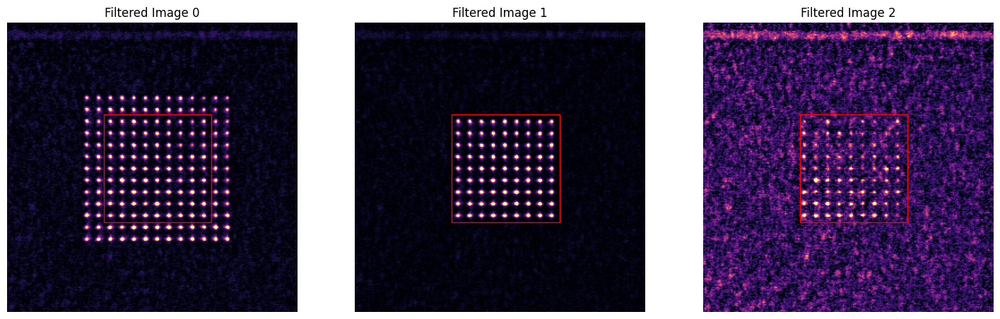

In [212]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Trap (0) Loading Probability : 96.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 98.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 96.00 %
Trap (6) Loading Probability : 99.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 98.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 97.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 93.00 %
Trap (15) Loading Probability : 97.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 100.00 %
Trap (18) Loading Probability : 93.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 86.00 %
Trap (24) Loading Probability : 95.00 %
Trap (25)

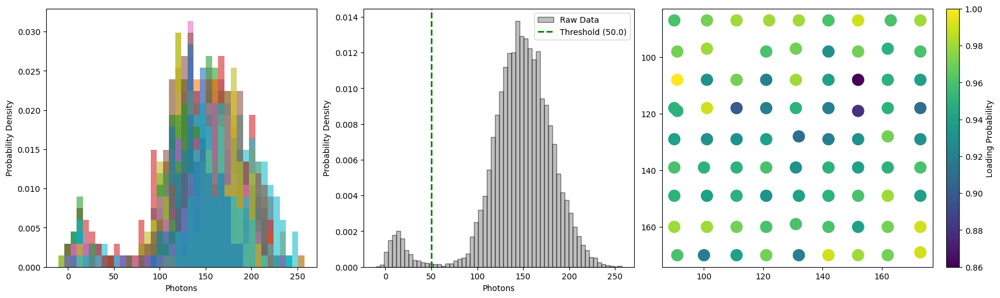

In [213]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 7.00 %
Trap (1) Loading Probability : 2.00 %
Trap (2) Loading Probability : 13.00 %
Trap (3) Loading Probability : 5.00 %
Trap (4) Loading Probability : 3.00 %
Trap (5) Loading Probability : 5.00 %
Trap (6) Loading Probability : 6.00 %
Trap (7) Loading Probability : 3.00 %
Trap (8) Loading Probability : 11.00 %
Trap (9) Loading Probability : 13.00 %
Trap (10) Loading Probability : 5.00 %
Trap (11) Loading Probability : 10.00 %
Trap (12) Loading Probability : 14.00 %
Trap (13) Loading Probability : 6.00 %
Trap (14) Loading Probability : 5.00 %
Trap (15) Loading Probability : 8.00 %
Trap (16) Loading Probability : 5.00 %
Trap (17) Loading Probability : 4.00 %
Trap (18) Loading Probability : 8.00 %
Trap (19) Loading Probability : 9.00 %
Trap (20) Loading Probability : 7.00 %
Trap (21) Loading Probability : 6.00 %
Trap (22) Loading Probability : 4.00 %
Trap (23) Loading Probability : 5.00 %
Trap (24) Loading Probability : 5.00 %
Trap (25) Loading Probability 

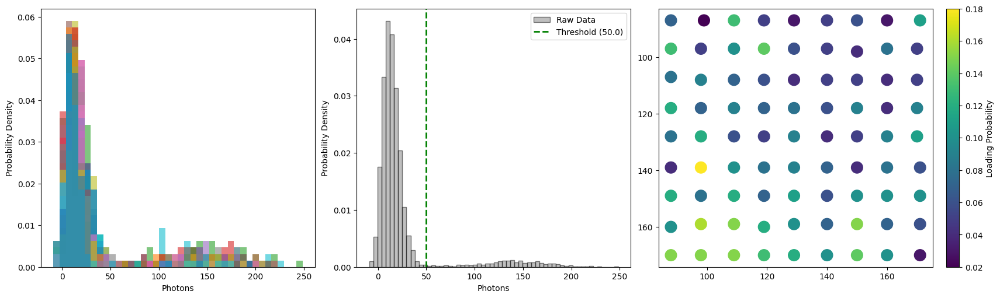

In [214]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [215]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.0848


#### Save Data

In [216]:
dataset_title = "rearrange_transport_dz_6um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Followed by a 6 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dz_6um_survival_probability


---
## Rearrangement + Transport Test 4 - 0 um dx Transport

In [341]:
DX = 0.0

Phasemask 2

In [342]:
W2 = np.ones((9,9))
spacing_um = 7.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.82e-05 | Uniformity: 44.56% | Min/Max ratio: 0.068
Iteration 010 | Mean-Squared Error: 3.19e-07 | Uniformity: 79.13% | Min/Max ratio: 0.435
Iteration 020 | Mean-Squared Error: 1.29e-07 | Uniformity: 80.14% | Min/Max ratio: 0.447
Iteration 030 | Mean-Squared Error: 8.31e-08 | Uniformity: 79.32% | Min/Max ratio: 0.445
Iteration 040 | Mean-Squared Error: 3.02e-08 | Uniformity: 79.93% | Min/Max ratio: 0.465
Iteration 050 | Mean-Squared Error: 3.23e-09 | Uniformity: 79.54% | Min/Max ratio: 0.457
Iteration 060 | Mean-Squared Error: 2.72e-09 | Uniformity: 79.46% | Min/Max ratio: 0.455
Iteration 070 | Mean-Squared Error: 8.27e-10 | Uniformity: 79.55% | Min/Max ratio: 0.457
Iteration 080 | Mean-Squared Error: 2.51e-10 | Uniformity: 79.60% | Min/Max ratio: 0.459
Iteration 090 | Mean-Squared Error: 1.12e-10 | Uniformity: 79.61% | Min/Max ratio: 0.460
It

Phasemask 3

In [343]:
W3 = np.ones((9,9))
spacing_um = 7.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += DX

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.91e-05 | Uniformity: 45.34% | Min/Max ratio: 0.054
Iteration 010 | Mean-Squared Error: 3.47e-07 | Uniformity: 79.81% | Min/Max ratio: 0.386
Iteration 020 | Mean-Squared Error: 1.79e-08 | Uniformity: 79.46% | Min/Max ratio: 0.457
Iteration 030 | Mean-Squared Error: 3.80e-08 | Uniformity: 79.78% | Min/Max ratio: 0.450
Iteration 040 | Mean-Squared Error: 9.01e-09 | Uniformity: 79.79% | Min/Max ratio: 0.455
Iteration 050 | Mean-Squared Error: 5.31e-09 | Uniformity: 79.62% | Min/Max ratio: 0.454
Iteration 060 | Mean-Squared Error: 1.15e-08 | Uniformity: 79.36% | Min/Max ratio: 0.450
Iteration 070 | Mean-Squared Error: 8.44e-09 | Uniformity: 79.33% | Min/Max ratio: 0.454
Iteration 080 | Mean-Squared Error: 3.92e-09 | Uniformity: 79.55% | Min/Max ratio: 0.458
Iteration 090 | Mean-Squared Error: 1.05e-08 | Uniformity: 79.56% | Min/Max ratio: 0.455
It

In [269]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=DX+0.1, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear",
    smooth_corners=False,
    only_moving=False,
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [270]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [271]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.1519 ms total
Transport complete: 2 frames, 4.8274 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 15 frames, 17.0269 ms total
Transport complete: 2 frames, 4.9175 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 19 frames, 17.3049 ms total
Transport complete: 2 frames, 3.4918 ms total
Images acquired from rearrangement n

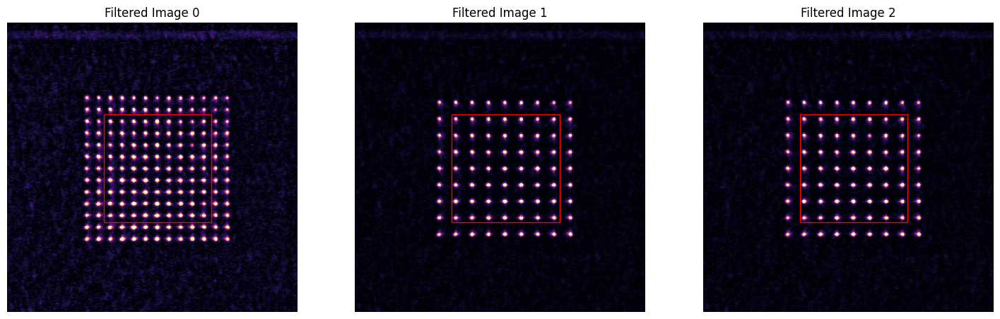

In [272]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 99.00 %
Trap (3) Loading Probability : 99.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 95.00 %
Trap (7) Loading Probability : 95.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 93.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 97.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 100.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 95.00 %
Trap

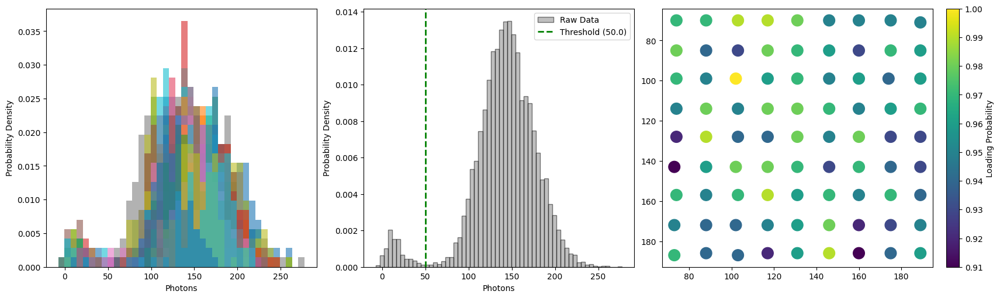

In [273]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 94.00 %
Trap (1) Loading Probability : 93.00 %
Trap (2) Loading Probability : 94.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 88.00 %
Trap (6) Loading Probability : 93.00 %
Trap (7) Loading Probability : 91.00 %
Trap (8) Loading Probability : 91.00 %
Trap (9) Loading Probability : 93.00 %
Trap (10) Loading Probability : 91.00 %
Trap (11) Loading Probability : 93.00 %
Trap (12) Loading Probability : 93.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 93.00 %
Trap (18) Loading Probability : 93.00 %
Trap (19) Loading Probability : 92.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 91.00 %
Trap (22) Loading Probability : 84.00 %
Trap (23) Loading Probability : 92.00 %
Trap 

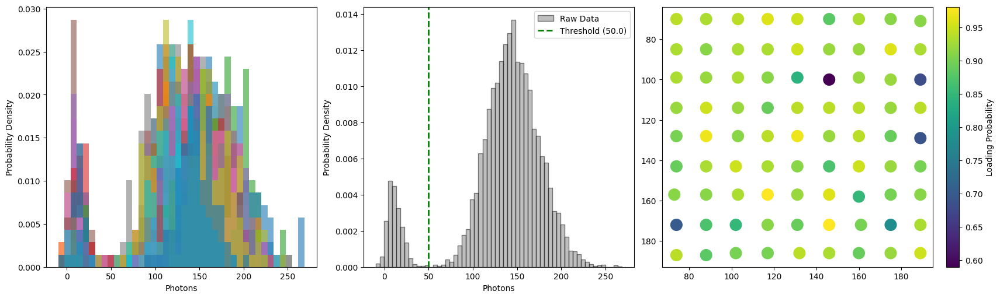

In [274]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [275]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9379


#### Save Data

In [276]:
dataset_title = "rearrange_transport_dx_0um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. Followed by a 0 um global transport in z direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dx_0um_survival_probability


---
## Rearrangement + Transport Test 4 - 0.5 um dx Transport

In [344]:
DX = 0.5

Phasemask 2

In [345]:
W2 = np.ones((9,9))
spacing_um = 7.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.01e-05 | Uniformity: 44.95% | Min/Max ratio: 0.016
Iteration 010 | Mean-Squared Error: 1.68e-07 | Uniformity: 79.33% | Min/Max ratio: 0.409
Iteration 020 | Mean-Squared Error: 8.52e-08 | Uniformity: 79.50% | Min/Max ratio: 0.442
Iteration 030 | Mean-Squared Error: 3.34e-08 | Uniformity: 79.39% | Min/Max ratio: 0.457
Iteration 040 | Mean-Squared Error: 9.42e-09 | Uniformity: 79.35% | Min/Max ratio: 0.459
Iteration 050 | Mean-Squared Error: 1.98e-09 | Uniformity: 79.57% | Min/Max ratio: 0.464
Iteration 060 | Mean-Squared Error: 4.08e-10 | Uniformity: 79.63% | Min/Max ratio: 0.462
Iteration 070 | Mean-Squared Error: 1.06e-10 | Uniformity: 79.64% | Min/Max ratio: 0.461
Iteration 080 | Mean-Squared Error: 4.31e-11 | Uniformity: 79.64% | Min/Max ratio: 0.460
Iteration 090 | Mean-Squared Error: 2.40e-11 | Uniformity: 79.64% | Min/Max ratio: 0.460
It

Phasemask 3

In [346]:
W3 = np.ones((9,9))
spacing_um = 7.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += DX*2

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.28e-05 | Uniformity: 50.97% | Min/Max ratio: 0.080
Iteration 010 | Mean-Squared Error: 2.03e-07 | Uniformity: 79.14% | Min/Max ratio: 0.436
Iteration 020 | Mean-Squared Error: 2.96e-08 | Uniformity: 79.38% | Min/Max ratio: 0.455
Iteration 030 | Mean-Squared Error: 7.97e-09 | Uniformity: 79.56% | Min/Max ratio: 0.463
Iteration 040 | Mean-Squared Error: 1.13e-09 | Uniformity: 79.66% | Min/Max ratio: 0.461
Iteration 050 | Mean-Squared Error: 5.02e-10 | Uniformity: 79.62% | Min/Max ratio: 0.459
Iteration 060 | Mean-Squared Error: 4.14e-10 | Uniformity: 79.60% | Min/Max ratio: 0.458
Iteration 070 | Mean-Squared Error: 4.07e-10 | Uniformity: 79.60% | Min/Max ratio: 0.458
Iteration 080 | Mean-Squared Error: 3.68e-10 | Uniformity: 79.61% | Min/Max ratio: 0.458
Iteration 090 | Mean-Squared Error: 3.45e-10 | Uniformity: 79.61% | Min/Max ratio: 0.458
It

In [347]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=DX+0.1, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear",
    smooth_corners=False,
    only_moving=False,
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [348]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [349]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 21 frames, 18.5329 ms total
Transport complete: 3 frames, 4.7309 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 18 frames, 17.0607 ms total
Transport complete: 3 frames, 5.0333 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 21 frames, 18.7633 ms total
Transport complete: 3 frames, 4.0691 ms total
Images acquired from rearrangement n

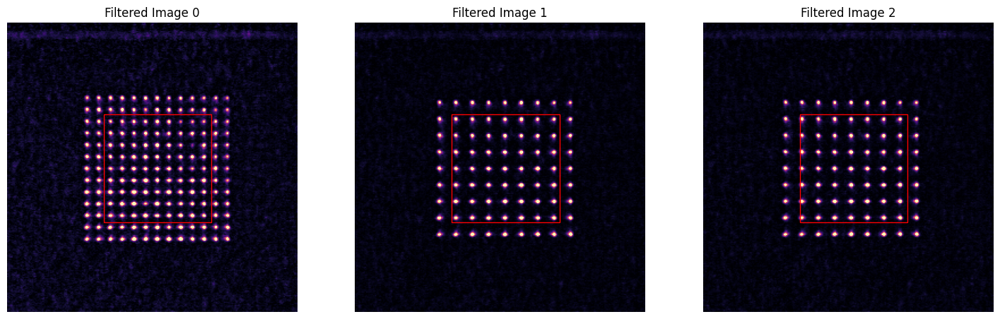

In [350]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 98.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 95.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 100.00 %
Trap (6) Loading Probability : 92.00 %
Trap (7) Loading Probability : 92.00 %
Trap (8) Loading Probability : 90.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 93.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 99.00 %
Trap (15) Loading Probability : 94.00 %
Trap (16) Loading Probability : 90.00 %
Trap (17) Loading Probability : 91.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 98.00 %
Trap (20) Loading Probability : 94.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 93.00 %
Trap

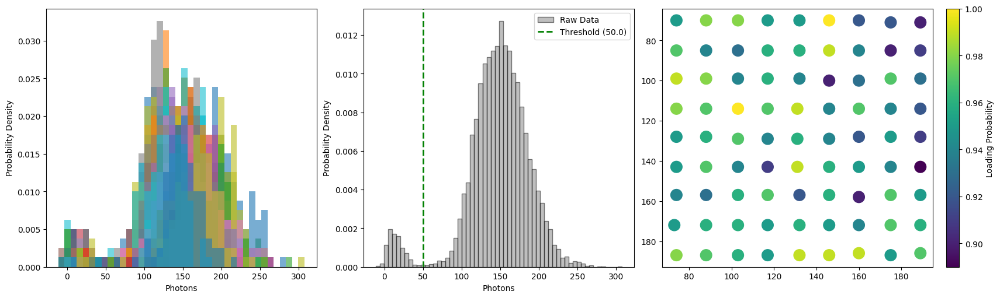

In [351]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 93.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 92.00 %
Trap (4) Loading Probability : 97.00 %
Trap (5) Loading Probability : 91.00 %
Trap (6) Loading Probability : 87.00 %
Trap (7) Loading Probability : 90.00 %
Trap (8) Loading Probability : 86.00 %
Trap (9) Loading Probability : 94.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 91.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 94.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 86.00 %
Trap (17) Loading Probability : 89.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 90.00 %
Trap (22) Loading Probability : 89.00 %
Trap (23) Loading Probability : 96.00 %
Trap 

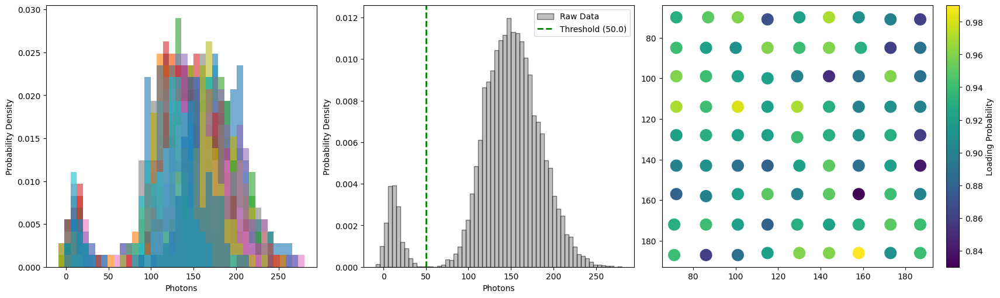

In [352]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [353]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9549


#### Save Data

In [354]:
dataset_title = "rearrange_transport_dx_0_5um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. Followed by a 0.5 um global transport in x direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_dx_0_5um_survival_probability' already exists. Renaming to 'rearrange_transport_dx_0_5um_survival_probability_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dx_0_5um_survival_probability_1


---
## Rearrangement + Transport Test 4 - 1.0 um dx Transport

In [355]:
DX = 1.0

Phasemask 2

In [356]:
W2 = np.ones((9,9))
spacing_um = 7.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.54e-05 | Uniformity: 49.85% | Min/Max ratio: 0.056
Iteration 010 | Mean-Squared Error: 1.58e-07 | Uniformity: 79.30% | Min/Max ratio: 0.442
Iteration 020 | Mean-Squared Error: 7.04e-08 | Uniformity: 79.78% | Min/Max ratio: 0.459
Iteration 030 | Mean-Squared Error: 7.57e-09 | Uniformity: 79.53% | Min/Max ratio: 0.462
Iteration 040 | Mean-Squared Error: 2.69e-08 | Uniformity: 79.19% | Min/Max ratio: 0.455
Iteration 050 | Mean-Squared Error: 2.95e-09 | Uniformity: 79.71% | Min/Max ratio: 0.458
Iteration 060 | Mean-Squared Error: 6.64e-09 | Uniformity: 79.78% | Min/Max ratio: 0.461
Iteration 070 | Mean-Squared Error: 2.65e-08 | Uniformity: 79.62% | Min/Max ratio: 0.449
Iteration 080 | Mean-Squared Error: 6.72e-09 | Uniformity: 79.58% | Min/Max ratio: 0.457
Iteration 090 | Mean-Squared Error: 3.00e-09 | Uniformity: 79.57% | Min/Max ratio: 0.456
It

Phasemask 3

In [357]:
W3 = np.ones((9,9))
spacing_um = 7.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += DX*2

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.06e-05 | Uniformity: 50.50% | Min/Max ratio: 0.074
Iteration 010 | Mean-Squared Error: 3.26e-07 | Uniformity: 78.39% | Min/Max ratio: 0.428
Iteration 020 | Mean-Squared Error: 4.47e-08 | Uniformity: 79.74% | Min/Max ratio: 0.450
Iteration 030 | Mean-Squared Error: 8.92e-09 | Uniformity: 79.62% | Min/Max ratio: 0.459
Iteration 040 | Mean-Squared Error: 2.68e-08 | Uniformity: 79.85% | Min/Max ratio: 0.462
Iteration 050 | Mean-Squared Error: 2.11e-08 | Uniformity: 79.62% | Min/Max ratio: 0.454
Iteration 060 | Mean-Squared Error: 1.18e-08 | Uniformity: 79.55% | Min/Max ratio: 0.450
Iteration 070 | Mean-Squared Error: 1.51e-09 | Uniformity: 79.62% | Min/Max ratio: 0.460
Iteration 080 | Mean-Squared Error: 6.87e-10 | Uniformity: 79.66% | Min/Max ratio: 0.462
Iteration 090 | Mean-Squared Error: 3.10e-10 | Uniformity: 79.67% | Min/Max ratio: 0.462
It

In [358]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=DX+0.1, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear",
    smooth_corners=False,
    only_moving=False,
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [359]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [360]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 20.8723 ms total
Transport complete: 3 frames, 5.2234 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 28 frames, 24.0782 ms total
Transport complete: 3 frames, 5.0800 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 26 frames, 22.0393 ms total
Transport complete: 3 frames, 5.1975 ms total
Images acquired from rearrangement n

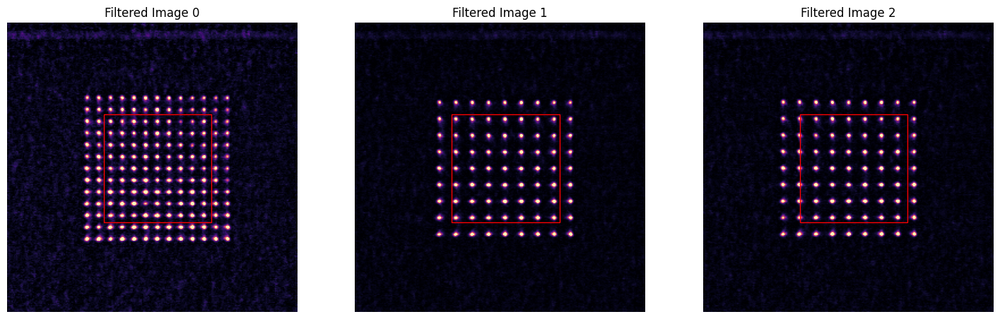

In [361]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 98.00 %
Trap (4) Loading Probability : 93.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 91.00 %
Trap (7) Loading Probability : 93.00 %
Trap (8) Loading Probability : 87.00 %
Trap (9) Loading Probability : 95.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 93.00 %
Trap (13) Loading Probability : 94.00 %
Trap (14) Loading Probability : 91.00 %
Trap (15) Loading Probability : 84.00 %
Trap (16) Loading Probability : 87.00 %
Trap (17) Loading Probability : 89.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 97.00 %
Trap (22) Loading Probability : 93.00 %
Trap (23) Loading Probability : 96.00 %
Trap 

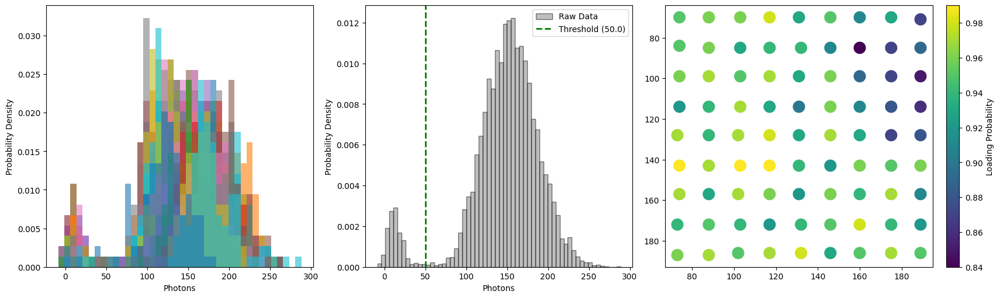

In [362]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 94.00 %
Trap (1) Loading Probability : 94.00 %
Trap (2) Loading Probability : 93.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 77.00 %
Trap (5) Loading Probability : 93.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 92.00 %
Trap (8) Loading Probability : 85.00 %
Trap (9) Loading Probability : 88.00 %
Trap (10) Loading Probability : 89.00 %
Trap (11) Loading Probability : 92.00 %
Trap (12) Loading Probability : 78.00 %
Trap (13) Loading Probability : 70.00 %
Trap (14) Loading Probability : 86.00 %
Trap (15) Loading Probability : 82.00 %
Trap (16) Loading Probability : 77.00 %
Trap (17) Loading Probability : 86.00 %
Trap (18) Loading Probability : 93.00 %
Trap (19) Loading Probability : 88.00 %
Trap (20) Loading Probability : 60.00 %
Trap (21) Loading Probability : 87.00 %
Trap (22) Loading Probability : 87.00 %
Trap (23) Loading Probability : 86.00 %
Trap 

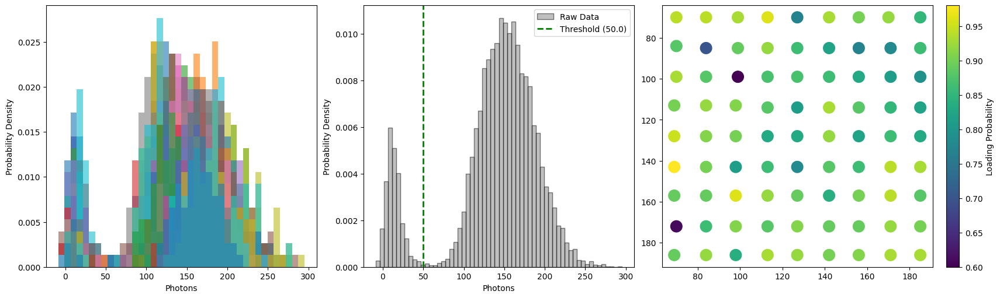

In [363]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [364]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9045


#### Save Data

In [365]:
dataset_title = "rearrange_transport_dx_1um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. Followed by a 1 um global transport in x direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_dx_1um_survival_probability' already exists. Renaming to 'rearrange_transport_dx_1um_survival_probability_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dx_1um_survival_probability_1


---
## Rearrangement + Transport Test 4 - 1.5 um dx Transport

In [366]:
DX = 1.5

Phasemask 2

In [367]:
W2 = np.ones((9,9))
spacing_um = 7.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.44e-05 | Uniformity: 48.96% | Min/Max ratio: 0.100
Iteration 010 | Mean-Squared Error: 1.54e-07 | Uniformity: 79.41% | Min/Max ratio: 0.418
Iteration 020 | Mean-Squared Error: 1.74e-08 | Uniformity: 79.42% | Min/Max ratio: 0.458
Iteration 030 | Mean-Squared Error: 1.03e-08 | Uniformity: 79.62% | Min/Max ratio: 0.457
Iteration 040 | Mean-Squared Error: 5.60e-08 | Uniformity: 79.53% | Min/Max ratio: 0.435
Iteration 050 | Mean-Squared Error: 2.51e-08 | Uniformity: 79.58% | Min/Max ratio: 0.457
Iteration 060 | Mean-Squared Error: 3.78e-08 | Uniformity: 79.65% | Min/Max ratio: 0.465
Iteration 070 | Mean-Squared Error: 1.15e-08 | Uniformity: 79.80% | Min/Max ratio: 0.459
Iteration 080 | Mean-Squared Error: 3.41e-09 | Uniformity: 79.65% | Min/Max ratio: 0.463
Iteration 090 | Mean-Squared Error: 2.98e-09 | Uniformity: 79.64% | Min/Max ratio: 0.464
It

Phasemask 3

In [369]:
W3 = np.ones((9,9))
spacing_um = 7.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += DX*2

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 7.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.37e-05 | Uniformity: 39.15% | Min/Max ratio: 0.068
Iteration 010 | Mean-Squared Error: 2.55e-07 | Uniformity: 79.37% | Min/Max ratio: 0.464
Iteration 020 | Mean-Squared Error: 6.19e-08 | Uniformity: 80.39% | Min/Max ratio: 0.455
Iteration 030 | Mean-Squared Error: 3.60e-08 | Uniformity: 79.99% | Min/Max ratio: 0.454
Iteration 040 | Mean-Squared Error: 5.82e-09 | Uniformity: 79.53% | Min/Max ratio: 0.458
Iteration 050 | Mean-Squared Error: 1.11e-08 | Uniformity: 79.40% | Min/Max ratio: 0.455
Iteration 060 | Mean-Squared Error: 4.52e-09 | Uniformity: 79.58% | Min/Max ratio: 0.460
Iteration 070 | Mean-Squared Error: 6.69e-09 | Uniformity: 79.52% | Min/Max ratio: 0.457
Iteration 080 | Mean-Squared Error: 1.32e-08 | Uniformity: 79.29% | Min/Max ratio: 0.456
Iteration 090 | Mean-Squared Error: 4.28e-09 | Uniformity: 79.54% | Min/Max ratio: 0.458
It

In [370]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=DX+0.1, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear",
    smooth_corners=False,
    only_moving=False,
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [371]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [372]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 19 frames, 18.8504 ms total
Transport complete: 3 frames, 5.5420 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 27 frames, 24.3463 ms total
Transport complete: 3 frames, 5.2607 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 20 frames, 18.8558 ms total
Transport complete: 3 frames, 6.8092 ms total
Images acquired from rearrangement n

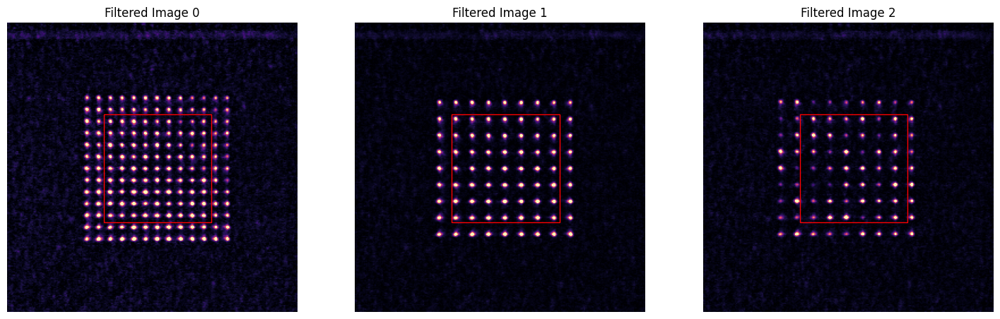

In [373]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 90.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 88.00 %
Trap (7) Loading Probability : 89.00 %
Trap (8) Loading Probability : 83.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 94.00 %
Trap (12) Loading Probability : 95.00 %
Trap (13) Loading Probability : 89.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 79.00 %
Trap (16) Loading Probability : 85.00 %
Trap (17) Loading Probability : 89.00 %
Trap (18) Loading Probability : 97.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 97.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 90.00 %
Trap 

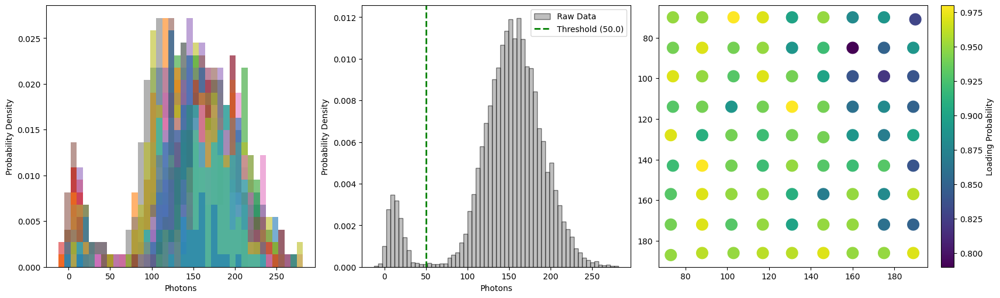

In [374]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [379]:
grid_positions_2 = grid_positions_1
# For each value in grid_positions_2, which is a dictionary, add the DX value to the x-coordinate of the position. The grid_positions_2 is a dictionary where each key corresponds to a trap site, and the value is a tuple representing the (x, y) coordinates of that site. We will create a new dictionary where we add DX to the x-coordinate of each position.
grid_positions_2 = {key: (pos[0], pos[1] - 6) for key, pos in grid_positions_2.items()}

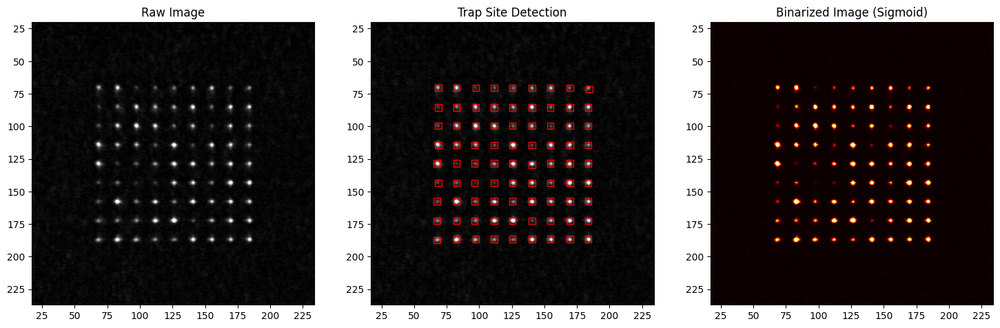

In [380]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)
an.visualize_results(imgs_2_mean_filtered, grid_positions_2, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)

Trap (0) Loading Probability : 63.00 %
Trap (1) Loading Probability : 85.00 %
Trap (2) Loading Probability : 16.00 %
Trap (3) Loading Probability : 29.00 %
Trap (4) Loading Probability : 30.00 %
Trap (5) Loading Probability : 43.00 %
Trap (6) Loading Probability : 58.00 %
Trap (7) Loading Probability : 34.00 %
Trap (8) Loading Probability : 46.00 %
Trap (9) Loading Probability : 39.00 %
Trap (10) Loading Probability : 19.00 %
Trap (11) Loading Probability : 76.00 %
Trap (12) Loading Probability : 48.00 %
Trap (13) Loading Probability : 45.00 %
Trap (14) Loading Probability : 74.00 %
Trap (15) Loading Probability : 30.00 %
Trap (16) Loading Probability : 75.00 %
Trap (17) Loading Probability : 73.00 %
Trap (18) Loading Probability : 25.00 %
Trap (19) Loading Probability : 70.00 %
Trap (20) Loading Probability : 89.00 %
Trap (21) Loading Probability : 73.00 %
Trap (22) Loading Probability : 27.00 %
Trap (23) Loading Probability : 41.00 %
Trap (24) Loading Probability : 18.00 %
Trap (25) 

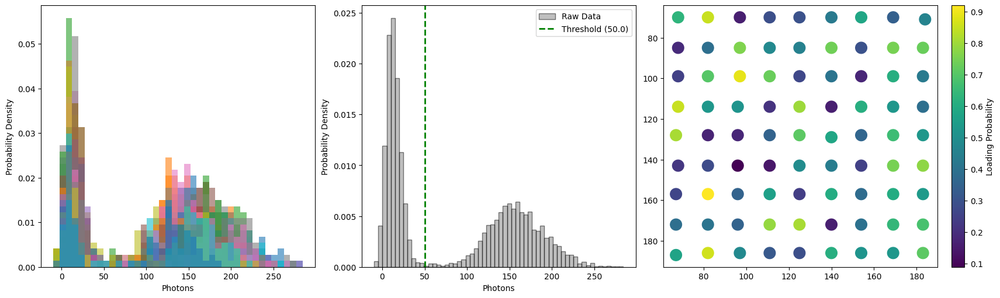

In [381]:
imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [382]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.5272


#### Save Data

In [383]:
dataset_title = "rearrange_transport_dx_1_5um_survival_probability"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. Followed by a 1.5 um global transport in x direction then hold then return.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2,}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_dx_1_5um_survival_probability' already exists. Renaming to 'rearrange_transport_dx_1_5um_survival_probability_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_dx_1_5um_survival_probability_1


---
## Rearrangement + Transport Test 5 - Up and Over - 25.0 Lift

Phasemask 2

In [419]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.53e-05 | Uniformity: 34.65% | Min/Max ratio: 0.037
Iteration 010 | Mean-Squared Error: 9.96e-08 | Uniformity: 75.83% | Min/Max ratio: 0.390
Iteration 020 | Mean-Squared Error: 1.98e-08 | Uniformity: 75.09% | Min/Max ratio: 0.394
Iteration 030 | Mean-Squared Error: 7.44e-09 | Uniformity: 75.03% | Min/Max ratio: 0.393
Iteration 040 | Mean-Squared Error: 5.31e-09 | Uniformity: 75.13% | Min/Max ratio: 0.394
Iteration 050 | Mean-Squared Error: 2.87e-09 | Uniformity: 75.14% | Min/Max ratio: 0.396
Iteration 060 | Mean-Squared Error: 1.07e-09 | Uniformity: 75.14% | Min/Max ratio: 0.398
Iteration 070 | Mean-Squared Error: 5.70e-10 | Uniformity: 75.18% | Min/Max ratio: 0.399
Iteration 080 | Mean-Squared Error: 3.81e-10 | Uniformity: 75.18% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 2

Phasemask 3

In [420]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.70e-05 | Uniformity: 40.33% | Min/Max ratio: 0.029
Iteration 010 | Mean-Squared Error: 1.38e-07 | Uniformity: 74.57% | Min/Max ratio: 0.369
Iteration 020 | Mean-Squared Error: 6.92e-09 | Uniformity: 75.24% | Min/Max ratio: 0.395
Iteration 030 | Mean-Squared Error: 4.88e-09 | Uniformity: 75.32% | Min/Max ratio: 0.395
Iteration 040 | Mean-Squared Error: 2.21e-09 | Uniformity: 75.27% | Min/Max ratio: 0.398
Iteration 050 | Mean-Squared Error: 2.20e-09 | Uniformity: 75.23% | Min/Max ratio: 0.396
Iteration 060 | Mean-Squared Error: 2.33e-09 | Uniformity: 75.19% | Min/Max ratio: 0.397
Iteration 070 | Mean-Squared Error: 1.48e-09 | Uniformity: 75.18% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 1.14e-09 | Uniformity: 75.19% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 9

In [449]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=2.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=True,
    only_moving=True,
    d_lift = 25.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [450]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [451]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 27.7897 ms total
Transport complete: 86 frames, 72.3752 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 20.4753 ms total
Transport complete: 86 frames, 72.6906 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 22.1383 ms total
Transport complete: 86 frames, 73.0502 ms total
Images acquired from rearrange

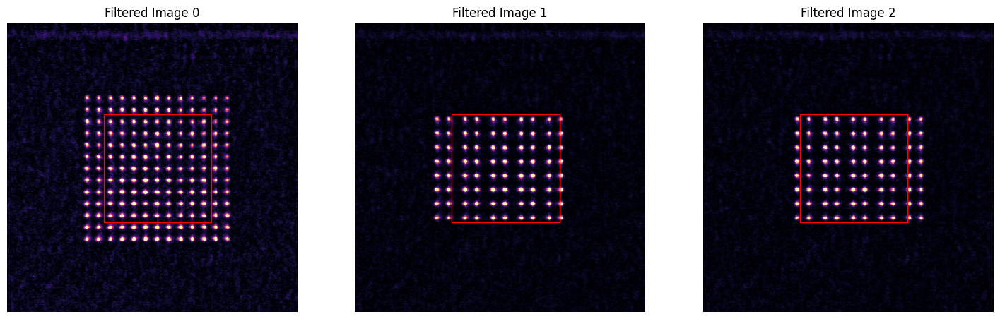

In [452]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 99.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 96.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 94.00 %
Trap (11) Loading Probability : 95.00 %
Trap (12) Loading Probability : 97.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 97.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 97.00 %
Trap (21) Loading Probability : 94.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 99.00 %
Trap 

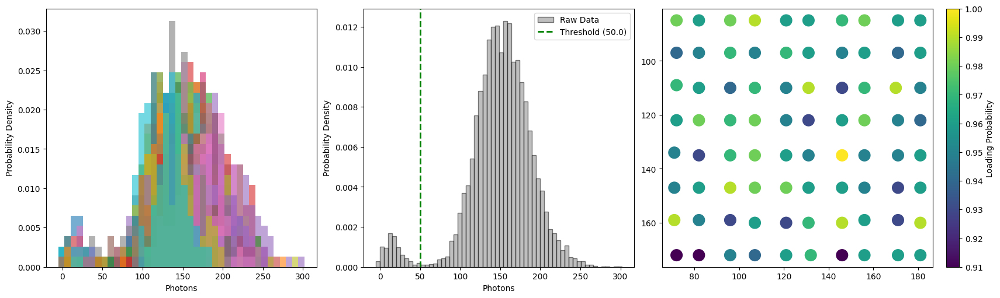

In [455]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 96.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 94.00 %
Trap (5) Loading Probability : 89.00 %
Trap (6) Loading Probability : 96.00 %
Trap (7) Loading Probability : 93.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 91.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 91.00 %
Trap (12) Loading Probability : 93.00 %
Trap (13) Loading Probability : 93.00 %
Trap (14) Loading Probability : 91.00 %
Trap (15) Loading Probability : 91.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 88.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 91.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 97.00 %
Trap (22) Loading Probability : 93.00 %
Trap (23) Loading Probability : 92.00 %
Trap 

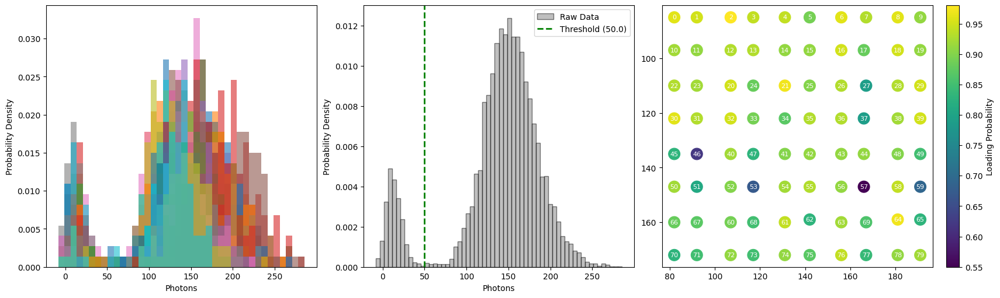

In [458]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [457]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8935


#### Save Data

In [460]:
dataset_title = "rearrange_transport_leapfrog_25um"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 25.0 um dz leapfrog. 1 equalisation iteration. Smooth corners.
    z step = 2.0 um, xy step = 0.5 um
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_leapfrog_25um' already exists. Renaming to 'rearrange_transport_leapfrog_25um_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_25um_1


---
## Rearrangement + Transport Test 5 - Up and Over - 15.0 Lift

Phasemask 2

In [461]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.95e-05 | Uniformity: 39.64% | Min/Max ratio: 0.049
Iteration 010 | Mean-Squared Error: 4.28e-08 | Uniformity: 75.50% | Min/Max ratio: 0.396
Iteration 020 | Mean-Squared Error: 1.33e-08 | Uniformity: 75.27% | Min/Max ratio: 0.394
Iteration 030 | Mean-Squared Error: 5.52e-09 | Uniformity: 75.25% | Min/Max ratio: 0.396
Iteration 040 | Mean-Squared Error: 4.08e-09 | Uniformity: 75.21% | Min/Max ratio: 0.395
Iteration 050 | Mean-Squared Error: 5.30e-09 | Uniformity: 75.23% | Min/Max ratio: 0.395
Iteration 060 | Mean-Squared Error: 7.88e-09 | Uniformity: 75.17% | Min/Max ratio: 0.397
Iteration 070 | Mean-Squared Error: 4.01e-09 | Uniformity: 75.12% | Min/Max ratio: 0.397
Iteration 080 | Mean-Squared Error: 8.13e-10 | Uniformity: 75.15% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 2

Phasemask 3

In [462]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.67e-05 | Uniformity: 42.43% | Min/Max ratio: 0.077
Iteration 010 | Mean-Squared Error: 9.80e-08 | Uniformity: 75.11% | Min/Max ratio: 0.382
Iteration 020 | Mean-Squared Error: 2.79e-08 | Uniformity: 75.02% | Min/Max ratio: 0.390
Iteration 030 | Mean-Squared Error: 1.02e-08 | Uniformity: 75.19% | Min/Max ratio: 0.392
Iteration 040 | Mean-Squared Error: 2.53e-09 | Uniformity: 75.19% | Min/Max ratio: 0.398
Iteration 050 | Mean-Squared Error: 1.35e-09 | Uniformity: 75.23% | Min/Max ratio: 0.400
Iteration 060 | Mean-Squared Error: 3.25e-09 | Uniformity: 75.29% | Min/Max ratio: 0.401
Iteration 070 | Mean-Squared Error: 3.88e-09 | Uniformity: 75.29% | Min/Max ratio: 0.397
Iteration 080 | Mean-Squared Error: 1.21e-09 | Uniformity: 75.24% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 4

In [463]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=2.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=True,
    only_moving=True,
    d_lift = 15.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [464]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [465]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 22.1037 ms total
Transport complete: 67 frames, 60.4998 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 23.1418 ms total
Transport complete: 67 frames, 61.0145 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 21.9831 ms total
Transport complete: 67 frames, 60.9603 ms total
Images acquired from rearrange

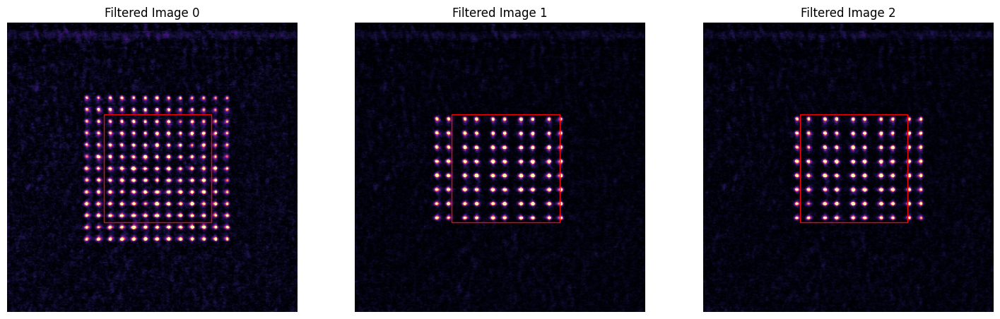

In [466]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 98.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 91.00 %
Trap (10) Loading Probability : 98.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 97.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 94.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 93.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 97.00 %
Trap (21) Loading Probability : 94.00 %
Trap (22) Loading Probability : 96.00 %
Trap (23) Loading Probability : 98.00 %
Trap 

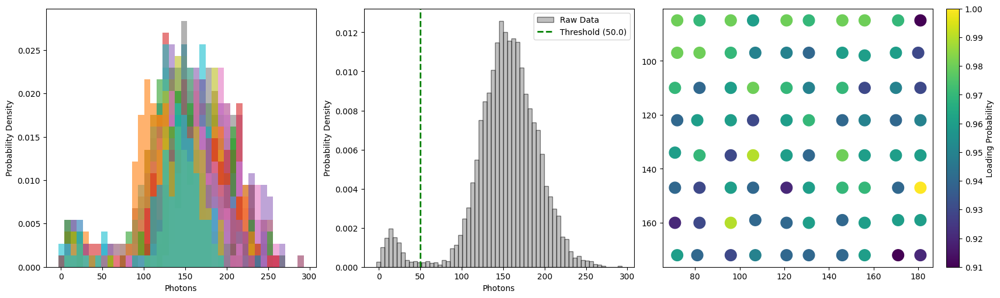

In [467]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 88.00 %
Trap (1) Loading Probability : 91.00 %
Trap (2) Loading Probability : 94.00 %
Trap (3) Loading Probability : 93.00 %
Trap (4) Loading Probability : 90.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 96.00 %
Trap (7) Loading Probability : 94.00 %
Trap (8) Loading Probability : 89.00 %
Trap (9) Loading Probability : 94.00 %
Trap (10) Loading Probability : 90.00 %
Trap (11) Loading Probability : 92.00 %
Trap (12) Loading Probability : 91.00 %
Trap (13) Loading Probability : 91.00 %
Trap (14) Loading Probability : 89.00 %
Trap (15) Loading Probability : 89.00 %
Trap (16) Loading Probability : 92.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 86.00 %
Trap (19) Loading Probability : 91.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 93.00 %
Trap (22) Loading Probability : 73.00 %
Trap (23) Loading Probability : 59.00 %
Trap (24) Loading Probability : 91.00 %
Trap (25) 

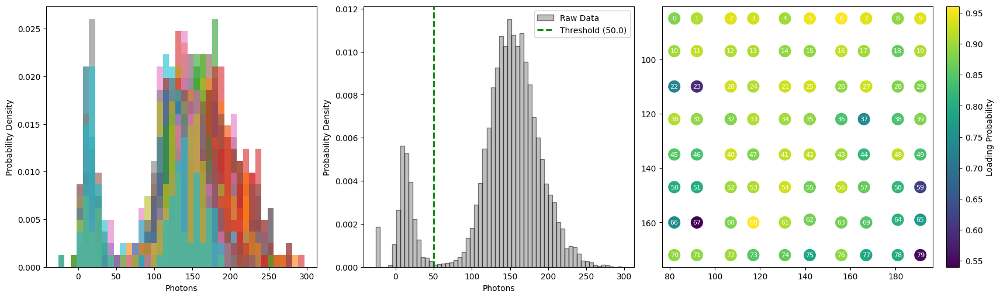

In [468]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [469]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8679


#### Save Data

In [470]:
dataset_title = "rearrange_transport_leapfrog_15um"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 15.0 um dz leapfrog. 1 equalisation iteration. Smooth corners.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_15um


---
## Rearrangement + Transport Test 5 - Up and Over - 5.0 Lift

Phasemask 2

In [471]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.48e-05 | Uniformity: 41.18% | Min/Max ratio: 0.030
Iteration 010 | Mean-Squared Error: 6.02e-08 | Uniformity: 75.31% | Min/Max ratio: 0.359
Iteration 020 | Mean-Squared Error: 2.45e-08 | Uniformity: 75.14% | Min/Max ratio: 0.389
Iteration 030 | Mean-Squared Error: 1.29e-08 | Uniformity: 75.08% | Min/Max ratio: 0.401
Iteration 040 | Mean-Squared Error: 2.41e-09 | Uniformity: 75.11% | Min/Max ratio: 0.397
Iteration 050 | Mean-Squared Error: 4.08e-09 | Uniformity: 75.13% | Min/Max ratio: 0.397
Iteration 060 | Mean-Squared Error: 4.37e-09 | Uniformity: 75.14% | Min/Max ratio: 0.397
Iteration 070 | Mean-Squared Error: 3.24e-09 | Uniformity: 75.15% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 2.53e-09 | Uniformity: 75.15% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 2

Phasemask 3

In [472]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.65e-05 | Uniformity: 40.50% | Min/Max ratio: 0.025
Iteration 010 | Mean-Squared Error: 8.74e-08 | Uniformity: 74.97% | Min/Max ratio: 0.378
Iteration 020 | Mean-Squared Error: 1.27e-08 | Uniformity: 75.09% | Min/Max ratio: 0.401
Iteration 030 | Mean-Squared Error: 5.70e-09 | Uniformity: 75.25% | Min/Max ratio: 0.400
Iteration 040 | Mean-Squared Error: 2.62e-09 | Uniformity: 75.22% | Min/Max ratio: 0.401
Iteration 050 | Mean-Squared Error: 2.52e-09 | Uniformity: 75.20% | Min/Max ratio: 0.401
Iteration 060 | Mean-Squared Error: 4.82e-09 | Uniformity: 75.25% | Min/Max ratio: 0.397
Iteration 070 | Mean-Squared Error: 5.61e-09 | Uniformity: 75.17% | Min/Max ratio: 0.393
Iteration 080 | Mean-Squared Error: 2.95e-09 | Uniformity: 75.15% | Min/Max ratio: 0.397
Iteration 090 | Mean-Squared Error: 1

In [473]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=2.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=True,
    only_moving=True,
    d_lift = 5.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [474]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [475]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 25 frames, 24.1408 ms total
Transport complete: 48 frames, 44.8900 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 25 frames, 23.8773 ms total
Transport complete: 48 frames, 44.9764 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 25 frames, 24.0575 ms total
Transport complete: 48 frames, 45.7784 ms total
Images acquired from rearrange

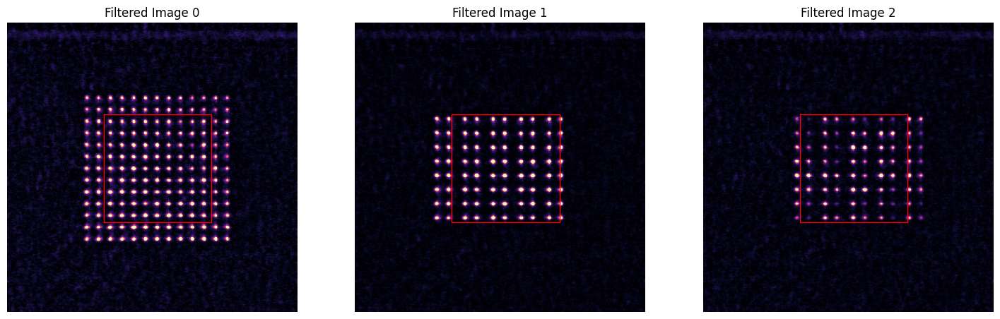

In [476]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 100.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 100.00 %
Trap (9) Loading Probability : 94.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 99.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 97.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 98.00 %
Trap (17) Loading Probability : 98.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 98.00 %
Trap (20) Loading Probability : 96.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 97.00 %
Tra

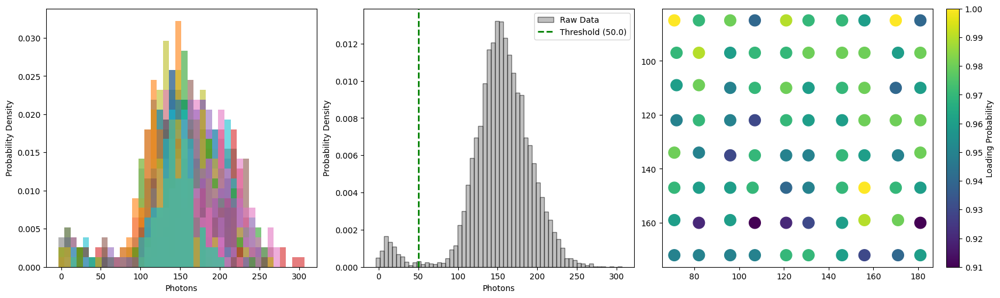

In [477]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 35.00 %
Trap (1) Loading Probability : 11.00 %
Trap (2) Loading Probability : 61.00 %
Trap (3) Loading Probability : 47.00 %
Trap (4) Loading Probability : 42.00 %
Trap (5) Loading Probability : 19.00 %
Trap (6) Loading Probability : 43.00 %
Trap (7) Loading Probability : 22.00 %
Trap (8) Loading Probability : 79.00 %
Trap (9) Loading Probability : 67.00 %
Trap (10) Loading Probability : 43.00 %
Trap (11) Loading Probability : 24.00 %
Trap (12) Loading Probability : 56.00 %
Trap (13) Loading Probability : 31.00 %
Trap (14) Loading Probability : 64.00 %
Trap (15) Loading Probability : 53.00 %
Trap (16) Loading Probability : 86.00 %
Trap (17) Loading Probability : 87.00 %
Trap (18) Loading Probability : 47.00 %
Trap (19) Loading Probability : 20.00 %
Trap (20) Loading Probability : 48.00 %
Trap (21) Loading Probability : 92.00 %
Trap (22) Loading Probability : 61.00 %
Trap (23) Loading Probability : 38.00 %
Trap (24) Loading Probability : 17.00 %
Trap (25) 

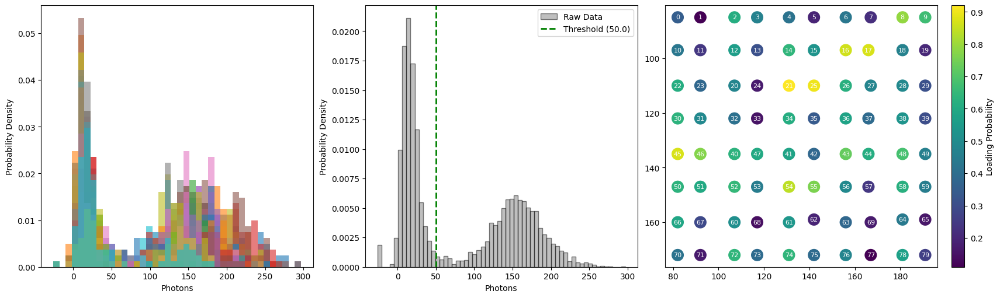

In [478]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [479]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.4834


#### Save Data

In [481]:
dataset_title = "rearrange_transport_leapfrog_5um"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 5.0 um dz leapfrog. 1 equalisation iteration. Smooth corners.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_5um


---
## Rearrangement + Transport Test 5 - Up and Over - 25.0 Lift - No Smooth Corners, 1.0 Step Size

Phasemask 2

In [499]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.09e-05 | Uniformity: 44.21% | Min/Max ratio: 0.093
Iteration 010 | Mean-Squared Error: 6.57e-08 | Uniformity: 75.34% | Min/Max ratio: 0.394
Iteration 020 | Mean-Squared Error: 1.32e-08 | Uniformity: 75.31% | Min/Max ratio: 0.400
Iteration 030 | Mean-Squared Error: 7.95e-09 | Uniformity: 75.19% | Min/Max ratio: 0.395
Iteration 040 | Mean-Squared Error: 5.01e-09 | Uniformity: 75.13% | Min/Max ratio: 0.398
Iteration 050 | Mean-Squared Error: 4.17e-09 | Uniformity: 75.08% | Min/Max ratio: 0.398
Iteration 060 | Mean-Squared Error: 3.30e-09 | Uniformity: 75.17% | Min/Max ratio: 0.399
Iteration 070 | Mean-Squared Error: 2.95e-09 | Uniformity: 75.25% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 1.44e-09 | Uniformity: 75.23% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 6

Phasemask 3

In [500]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.10e-05 | Uniformity: 44.19% | Min/Max ratio: 0.056
Iteration 010 | Mean-Squared Error: 4.00e-08 | Uniformity: 75.54% | Min/Max ratio: 0.388
Iteration 020 | Mean-Squared Error: 1.12e-08 | Uniformity: 75.18% | Min/Max ratio: 0.401
Iteration 030 | Mean-Squared Error: 1.06e-08 | Uniformity: 75.13% | Min/Max ratio: 0.399
Iteration 040 | Mean-Squared Error: 6.46e-09 | Uniformity: 75.16% | Min/Max ratio: 0.395
Iteration 050 | Mean-Squared Error: 6.08e-09 | Uniformity: 75.27% | Min/Max ratio: 0.399
Iteration 060 | Mean-Squared Error: 3.72e-09 | Uniformity: 75.25% | Min/Max ratio: 0.396
Iteration 070 | Mean-Squared Error: 3.48e-09 | Uniformity: 75.18% | Min/Max ratio: 0.392
Iteration 080 | Mean-Squared Error: 5.90e-09 | Uniformity: 75.09% | Min/Max ratio: 0.394
Iteration 090 | Mean-Squared Error: 6

In [501]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=True,
    d_lift = 25.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [502]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [504]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 15 frames, 16.9424 ms total
Transport complete: 71 frames, 61.4817 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception: 
Rearrangement complete: 22 frames, 25.5360 ms total
Transport complete: 71 frames, 87.1037 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 27 frames, 26.0732 ms total
Transport complete: 71 frames, 59.

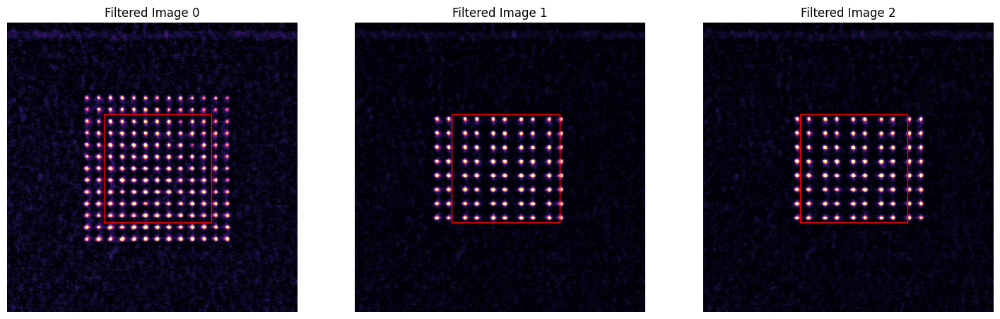

In [505]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 100.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 98.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 93.00 %
Trap (6) Loading Probability : 95.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 99.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 99.00 %
Trap (12) Loading Probability : 93.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 98.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 97.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 95.00 %
Trap

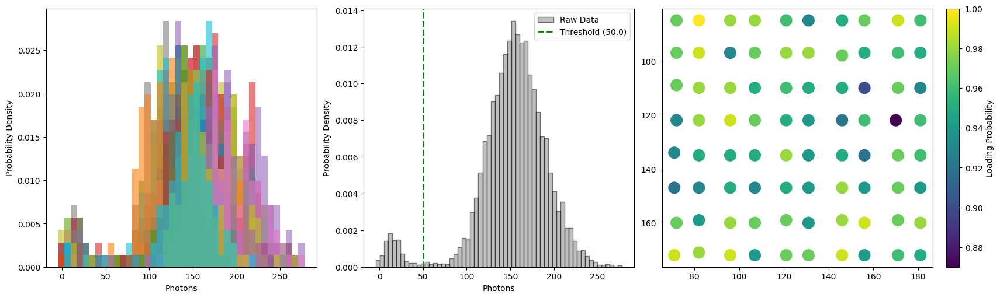

In [506]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 90.00 %
Trap (2) Loading Probability : 91.00 %
Trap (3) Loading Probability : 90.00 %
Trap (4) Loading Probability : 89.00 %
Trap (5) Loading Probability : 89.00 %
Trap (6) Loading Probability : 89.00 %
Trap (7) Loading Probability : 91.00 %
Trap (8) Loading Probability : 90.00 %
Trap (9) Loading Probability : 89.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 90.00 %
Trap (12) Loading Probability : 91.00 %
Trap (13) Loading Probability : 84.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 90.00 %
Trap (16) Loading Probability : 88.00 %
Trap (17) Loading Probability : 88.00 %
Trap (18) Loading Probability : 92.00 %
Trap (19) Loading Probability : 89.00 %
Trap (20) Loading Probability : 93.00 %
Trap (21) Loading Probability : 88.00 %
Trap (22) Loading Probability : 87.00 %
Trap (23) Loading Probability : 91.00 %
Trap 

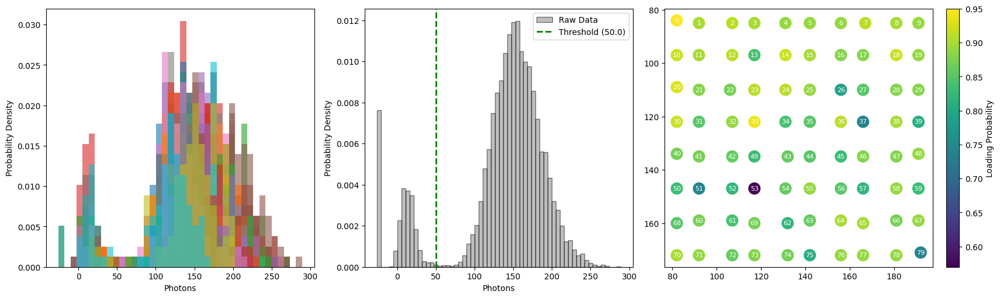

In [507]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [508]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8703


#### Save Data

In [509]:
dataset_title = "rearrange_transport_leapfrog_25um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 25.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_25um_1dz_step


---
## Rearrangement + Transport Test 5 - Up and Over - 35.0 Lift - No Smooth Corners, 1.0 Step Size

Phasemask 2

In [510]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.80e-05 | Uniformity: 45.82% | Min/Max ratio: 0.067
Iteration 010 | Mean-Squared Error: 1.16e-07 | Uniformity: 75.36% | Min/Max ratio: 0.388
Iteration 020 | Mean-Squared Error: 8.37e-09 | Uniformity: 75.09% | Min/Max ratio: 0.395
Iteration 030 | Mean-Squared Error: 1.92e-08 | Uniformity: 74.88% | Min/Max ratio: 0.388
Iteration 040 | Mean-Squared Error: 3.91e-09 | Uniformity: 75.22% | Min/Max ratio: 0.398
Iteration 050 | Mean-Squared Error: 3.28e-09 | Uniformity: 75.30% | Min/Max ratio: 0.398
Iteration 060 | Mean-Squared Error: 2.38e-09 | Uniformity: 75.23% | Min/Max ratio: 0.398
Iteration 070 | Mean-Squared Error: 1.13e-09 | Uniformity: 75.22% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 4.43e-10 | Uniformity: 75.20% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 2

Phasemask 3

In [511]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.70e-05 | Uniformity: 48.53% | Min/Max ratio: 0.078
Iteration 010 | Mean-Squared Error: 9.02e-08 | Uniformity: 75.26% | Min/Max ratio: 0.386
Iteration 020 | Mean-Squared Error: 1.66e-08 | Uniformity: 75.36% | Min/Max ratio: 0.394
Iteration 030 | Mean-Squared Error: 1.80e-08 | Uniformity: 75.18% | Min/Max ratio: 0.396
Iteration 040 | Mean-Squared Error: 6.67e-09 | Uniformity: 75.14% | Min/Max ratio: 0.399
Iteration 050 | Mean-Squared Error: 4.19e-09 | Uniformity: 75.10% | Min/Max ratio: 0.399
Iteration 060 | Mean-Squared Error: 7.75e-10 | Uniformity: 75.15% | Min/Max ratio: 0.399
Iteration 070 | Mean-Squared Error: 2.28e-10 | Uniformity: 75.18% | Min/Max ratio: 0.400
Iteration 080 | Mean-Squared Error: 1.64e-10 | Uniformity: 75.19% | Min/Max ratio: 0.400
Iteration 090 | Mean-Squared Error: 2

In [512]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=True,
    d_lift = 35.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [513]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [514]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 21 frames, 21.4038 ms total
Transport complete: 91 frames, 77.3611 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 28 frames, 26.6683 ms total
Transport complete: 91 frames, 77.6042 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 21.3614 ms total
Transport complete: 91 frames, 75.0768 ms total
Images acquired from rearrange

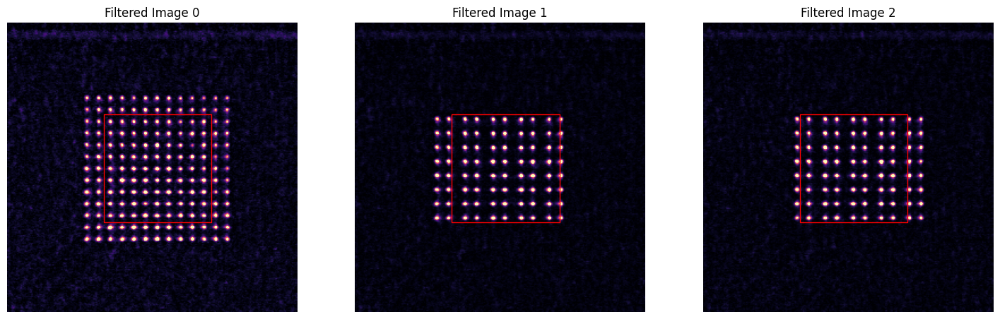

In [515]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 96.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 94.00 %
Trap (8) Loading Probability : 93.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 96.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 94.00 %
Trap (14) Loading Probability : 96.00 %
Trap (15) Loading Probability : 95.00 %
Trap (16) Loading Probability : 97.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 97.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 95.00 %
Trap (22) Loading Probability : 96.00 %
Trap (23) Loading Probability : 95.00 %
Trap 

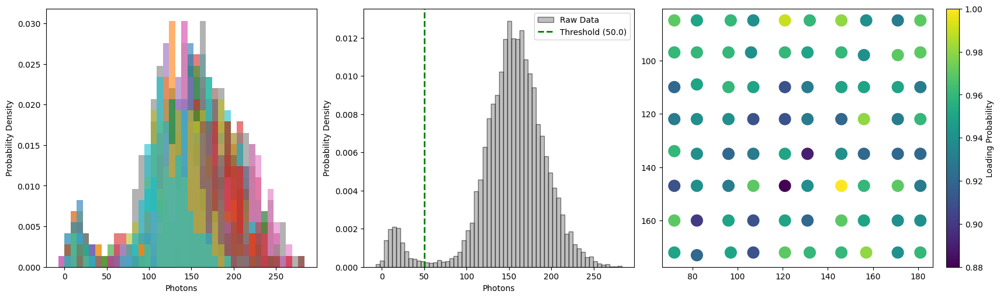

In [516]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 88.00 %
Trap (1) Loading Probability : 93.00 %
Trap (2) Loading Probability : 88.00 %
Trap (3) Loading Probability : 92.00 %
Trap (4) Loading Probability : 92.00 %
Trap (5) Loading Probability : 92.00 %
Trap (6) Loading Probability : 90.00 %
Trap (7) Loading Probability : 90.00 %
Trap (8) Loading Probability : 93.00 %
Trap (9) Loading Probability : 84.00 %
Trap (10) Loading Probability : 90.00 %
Trap (11) Loading Probability : 85.00 %
Trap (12) Loading Probability : 89.00 %
Trap (13) Loading Probability : 90.00 %
Trap (14) Loading Probability : 91.00 %
Trap (15) Loading Probability : 88.00 %
Trap (16) Loading Probability : 89.00 %
Trap (17) Loading Probability : 89.00 %
Trap (18) Loading Probability : 91.00 %
Trap (19) Loading Probability : 91.00 %
Trap (20) Loading Probability : 89.00 %
Trap (21) Loading Probability : 90.00 %
Trap (22) Loading Probability : 84.00 %
Trap (23) Loading Probability : 87.00 %
Trap 

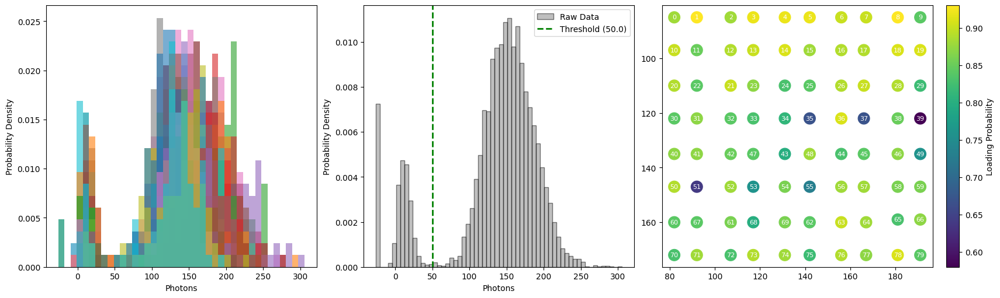

In [517]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [518]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8574


#### Save Data

In [519]:
dataset_title = "rearrange_transport_leapfrog_35um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 35.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_35um_1dz_step


---
## Rearrangement + Transport Test 5 - Up and Over - 15.0 Lift - No Smooth Corners, 1.0 Step Size

Phasemask 2

In [520]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.98e-05 | Uniformity: 45.83% | Min/Max ratio: 0.046
Iteration 010 | Mean-Squared Error: 8.32e-08 | Uniformity: 74.85% | Min/Max ratio: 0.382
Iteration 020 | Mean-Squared Error: 2.18e-08 | Uniformity: 75.17% | Min/Max ratio: 0.397
Iteration 030 | Mean-Squared Error: 8.04e-09 | Uniformity: 75.17% | Min/Max ratio: 0.399
Iteration 040 | Mean-Squared Error: 9.60e-09 | Uniformity: 75.25% | Min/Max ratio: 0.397
Iteration 050 | Mean-Squared Error: 1.17e-08 | Uniformity: 75.39% | Min/Max ratio: 0.401
Iteration 060 | Mean-Squared Error: 3.96e-09 | Uniformity: 75.30% | Min/Max ratio: 0.402
Iteration 070 | Mean-Squared Error: 6.05e-10 | Uniformity: 75.21% | Min/Max ratio: 0.400
Iteration 080 | Mean-Squared Error: 2.09e-10 | Uniformity: 75.19% | Min/Max ratio: 0.400
Iteration 090 | Mean-Squared Error: 2

Phasemask 3

In [521]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.81e-05 | Uniformity: 47.40% | Min/Max ratio: 0.053
Iteration 010 | Mean-Squared Error: 4.47e-08 | Uniformity: 75.39% | Min/Max ratio: 0.386
Iteration 020 | Mean-Squared Error: 1.69e-08 | Uniformity: 75.28% | Min/Max ratio: 0.399
Iteration 030 | Mean-Squared Error: 1.67e-08 | Uniformity: 74.94% | Min/Max ratio: 0.390
Iteration 040 | Mean-Squared Error: 7.12e-09 | Uniformity: 75.20% | Min/Max ratio: 0.396
Iteration 050 | Mean-Squared Error: 5.62e-09 | Uniformity: 75.29% | Min/Max ratio: 0.397
Iteration 060 | Mean-Squared Error: 5.35e-09 | Uniformity: 75.20% | Min/Max ratio: 0.398
Iteration 070 | Mean-Squared Error: 5.21e-09 | Uniformity: 75.13% | Min/Max ratio: 0.397
Iteration 080 | Mean-Squared Error: 2.58e-09 | Uniformity: 75.20% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 2

In [522]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=True,
    d_lift = 15.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [523]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [524]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 23.5998 ms total
Transport complete: 51 frames, 44.8798 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 23.3987 ms total
Transport complete: 51 frames, 45.0901 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 21.8668 ms total
Transport complete: 51 frames, 45.5459 ms total
Images acquired from rearrange

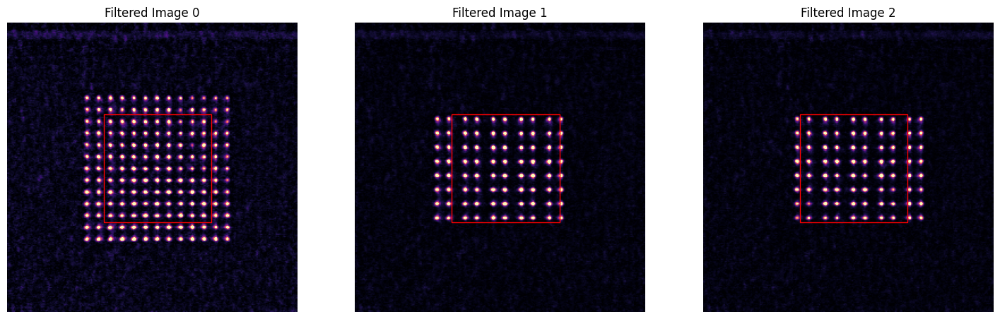

In [525]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 92.00 %
Trap (2) Loading Probability : 94.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 99.00 %
Trap (6) Loading Probability : 96.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 92.00 %
Trap (10) Loading Probability : 99.00 %
Trap (11) Loading Probability : 94.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 95.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 94.00 %
Trap (17) Loading Probability : 96.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 96.00 %
Trap 

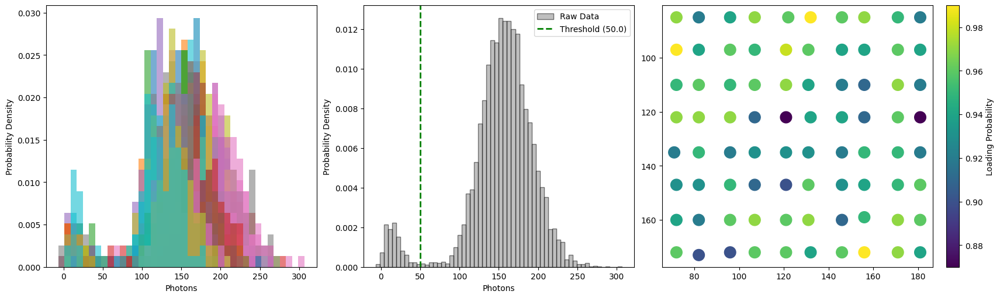

In [526]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 89.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 89.00 %
Trap (3) Loading Probability : 84.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 93.00 %
Trap (6) Loading Probability : 96.00 %
Trap (7) Loading Probability : 94.00 %
Trap (8) Loading Probability : 90.00 %
Trap (9) Loading Probability : 94.00 %
Trap (10) Loading Probability : 89.00 %
Trap (11) Loading Probability : 97.00 %
Trap (12) Loading Probability : 87.00 %
Trap (13) Loading Probability : 90.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 95.00 %
Trap (16) Loading Probability : 88.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 90.00 %
Trap (19) Loading Probability : 90.00 %
Trap (20) Loading Probability : 89.00 %
Trap (21) Loading Probability : 91.00 %
Trap (22) Loading Probability : 84.00 %
Trap (23) Loading Probability : 91.00 %
Trap (24) Loading Probability : 91.00 %
Trap (25) 

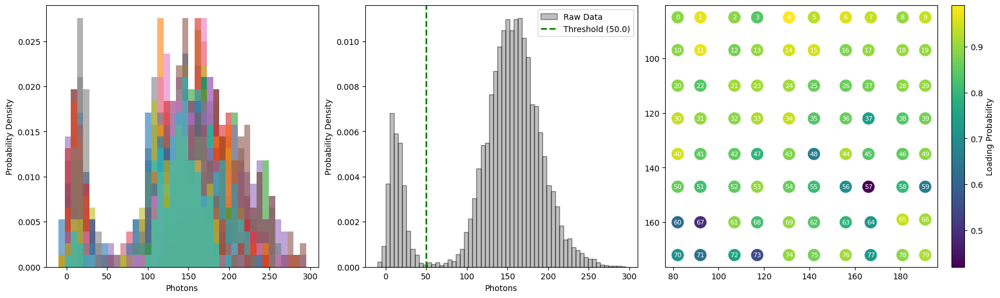

In [527]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [528]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8510


#### Save Data

In [529]:
dataset_title = "rearrange_transport_leapfrog_15um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 15.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_15um_1dz_step


---
## Rearrangement + Transport Test 5 - Up and Over - 5.0 Lift - No Smooth Corners, 1.0 Step Size

Phasemask 2

In [530]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.29e-05 | Uniformity: 33.20% | Min/Max ratio: 0.029
Iteration 010 | Mean-Squared Error: 8.93e-08 | Uniformity: 74.72% | Min/Max ratio: 0.385
Iteration 020 | Mean-Squared Error: 2.23e-08 | Uniformity: 75.17% | Min/Max ratio: 0.392
Iteration 030 | Mean-Squared Error: 2.01e-08 | Uniformity: 75.42% | Min/Max ratio: 0.395
Iteration 040 | Mean-Squared Error: 8.08e-09 | Uniformity: 75.35% | Min/Max ratio: 0.398
Iteration 050 | Mean-Squared Error: 1.09e-09 | Uniformity: 75.24% | Min/Max ratio: 0.400
Iteration 060 | Mean-Squared Error: 3.44e-10 | Uniformity: 75.20% | Min/Max ratio: 0.400
Iteration 070 | Mean-Squared Error: 3.09e-10 | Uniformity: 75.19% | Min/Max ratio: 0.400
Iteration 080 | Mean-Squared Error: 3.87e-10 | Uniformity: 75.19% | Min/Max ratio: 0.400
Iteration 090 | Mean-Squared Error: 5

Phasemask 3

In [531]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.34e-05 | Uniformity: 41.75% | Min/Max ratio: 0.055
Iteration 010 | Mean-Squared Error: 1.35e-07 | Uniformity: 75.38% | Min/Max ratio: 0.385
Iteration 020 | Mean-Squared Error: 3.65e-08 | Uniformity: 75.08% | Min/Max ratio: 0.385
Iteration 030 | Mean-Squared Error: 1.53e-08 | Uniformity: 75.48% | Min/Max ratio: 0.396
Iteration 040 | Mean-Squared Error: 8.77e-09 | Uniformity: 75.21% | Min/Max ratio: 0.396
Iteration 050 | Mean-Squared Error: 1.01e-08 | Uniformity: 75.05% | Min/Max ratio: 0.397
Iteration 060 | Mean-Squared Error: 3.24e-09 | Uniformity: 75.14% | Min/Max ratio: 0.399
Iteration 070 | Mean-Squared Error: 2.33e-09 | Uniformity: 75.18% | Min/Max ratio: 0.396
Iteration 080 | Mean-Squared Error: 3.18e-09 | Uniformity: 75.20% | Min/Max ratio: 0.395
Iteration 090 | Mean-Squared Error: 2

In [532]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=True,
    d_lift = 5.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 12.0).
Transport node initialised.


In [533]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [534]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 23.6847 ms total
Transport complete: 31 frames, 32.5811 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 25 frames, 24.8586 ms total
Transport complete: 31 frames, 32.6342 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 20 frames, 19.9221 ms total
Transport complete: 31 frames, 29.7345 ms total
Images acquired from rearrange

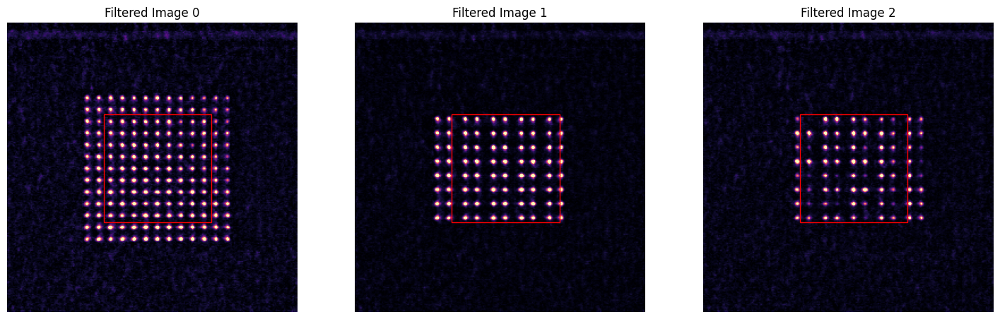

In [535]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 96.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 100.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 95.00 %
Trap (7) Loading Probability : 93.00 %
Trap (8) Loading Probability : 96.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 98.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 96.00 %
Trap (16) Loading Probability : 97.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 94.00 %
Trap (19) Loading Probability : 93.00 %
Trap (20) Loading Probability : 95.00 %
Trap (21) Loading Probability : 98.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 97.00 %
Trap

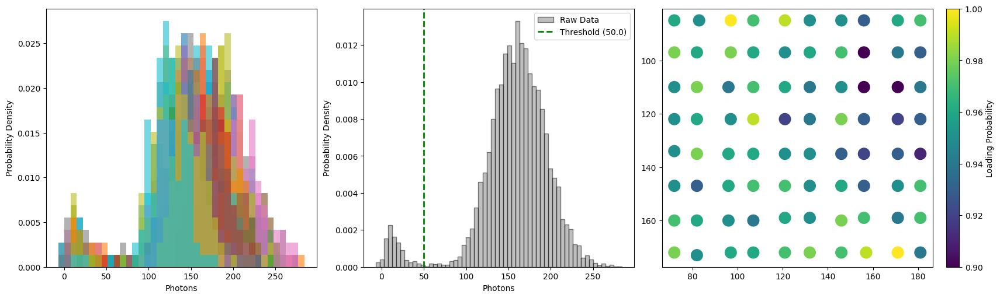

In [536]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Trap (0) Loading Probability : 39.00 %
Trap (1) Loading Probability : 5.00 %
Trap (2) Loading Probability : 89.00 %
Trap (3) Loading Probability : 91.00 %
Trap (4) Loading Probability : 61.00 %
Trap (5) Loading Probability : 43.00 %
Trap (6) Loading Probability : 48.00 %
Trap (7) Loading Probability : 32.00 %
Trap (8) Loading Probability : 63.00 %
Trap (9) Loading Probability : 50.00 %
Trap (10) Loading Probability : 91.00 %
Trap (11) Loading Probability : 90.00 %
Trap (12) Loading Probability : 79.00 %
Trap (13) Loading Probability : 67.00 %
Trap (14) Loading Probability : 89.00 %
Trap (15) Loading Probability : 84.00 %
Trap (16) Loading Probability : 81.00 %
Trap (17) Loading Probability : 45.00 %
Trap (18) Loading Probability : 61.00 %
Trap (19) Loading Probability : 46.00 %
Trap (20) Loading Probability : 40.00 %
Trap (21) Loading Probability : 63.00 %
Trap (22) Loading Probability : 17.00 %
Trap (23) Loading Probability : 51.00 %
Trap (24) Loading Probability : 66.00 %
Trap (25) L

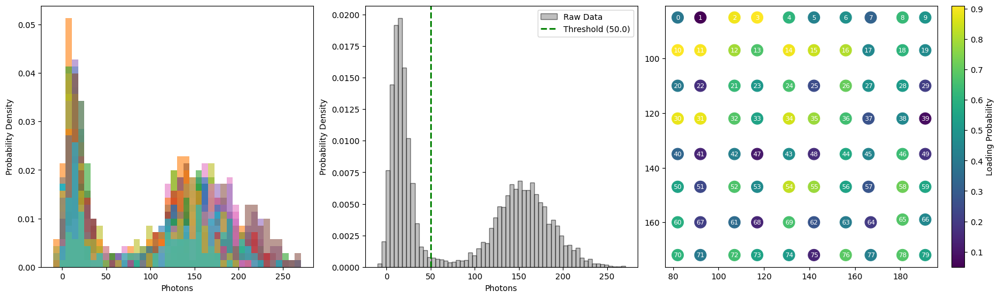

In [537]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

#feature_size, window = 10, 5
#grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [538]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.5175


#### Save Data

In [539]:
dataset_title = "rearrange_transport_leapfrog_5um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 5.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_5um_1dz_step


---
## Rearrangement + Transport Test 1 - Baseline 100 ms Survival

Phasemask 2

In [626]:
W2 = np.ones((9,9))
spacing_um = 5.0

w_n, theta_n, x_n2, y_n2, z_n2 = PM.generate_weighted_array(W2, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.23e-05 | Uniformity: 52.17% | Min/Max ratio: 0.112
Iteration 010 | Mean-Squared Error: 1.21e-07 | Uniformity: 85.20% | Min/Max ratio: 0.564
Iteration 020 | Mean-Squared Error: 1.25e-07 | Uniformity: 84.68% | Min/Max ratio: 0.571
Iteration 030 | Mean-Squared Error: 4.43e-08 | Uniformity: 85.30% | Min/Max ratio: 0.554
Iteration 040 | Mean-Squared Error: 1.08e-08 | Uniformity: 85.13% | Min/Max ratio: 0.563
Iteration 050 | Mean-Squared Error: 7.59e-09 | Uniformity: 85.08% | Min/Max ratio: 0.560
Iteration 060 | Mean-Squared Error: 6.32e-09 | Uniformity: 85.14% | Min/Max ratio: 0.563
Iteration 070 | Mean-Squared Error: 2.73e-09 | Uniformity: 85.12% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.50e-09 | Uniformity: 85.11% | Min/Max ratio: 0.564
Iteration 090 | Mean-Squared Error: 3.78e-09 | Uniformity: 85.08% | Min/Max ratio: 0.560
It

Phasemask 3

In [627]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 0.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.29e-05 | Uniformity: 53.08% | Min/Max ratio: 0.121
Iteration 010 | Mean-Squared Error: 3.64e-07 | Uniformity: 85.59% | Min/Max ratio: 0.543
Iteration 020 | Mean-Squared Error: 3.07e-08 | Uniformity: 85.14% | Min/Max ratio: 0.550
Iteration 030 | Mean-Squared Error: 6.10e-09 | Uniformity: 85.04% | Min/Max ratio: 0.558
Iteration 040 | Mean-Squared Error: 5.38e-09 | Uniformity: 85.03% | Min/Max ratio: 0.559
Iteration 050 | Mean-Squared Error: 5.12e-09 | Uniformity: 85.15% | Min/Max ratio: 0.569
Iteration 060 | Mean-Squared Error: 5.42e-09 | Uniformity: 85.24% | Min/Max ratio: 0.568
Iteration 070 | Mean-Squared Error: 3.34e-09 | Uniformity: 85.20% | Min/Max ratio: 0.563
Iteration 080 | Mean-Squared Error: 1.63e-09 | Uniformity: 85.15% | Min/Max ratio: 0.563
Iteration 090 | Mean-Squared Error: 1.23e-09 | Uniformity: 85.14% | Min/Max ratio: 0.563
It

In [628]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data2,
    d0=0.5, d0_z=0.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 13.4).
Transport node initialised.


In [629]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [637]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.9915 ms total
Transport complete: 2 frames, 5.0923 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 30 frames, 25.0659 ms total
Transport complete: 2 frames, 4.4966 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 24 frames, 21.1956 ms total
Transport complete: 2 frames, 4.9867 ms total
Images acquired from rearrangement n

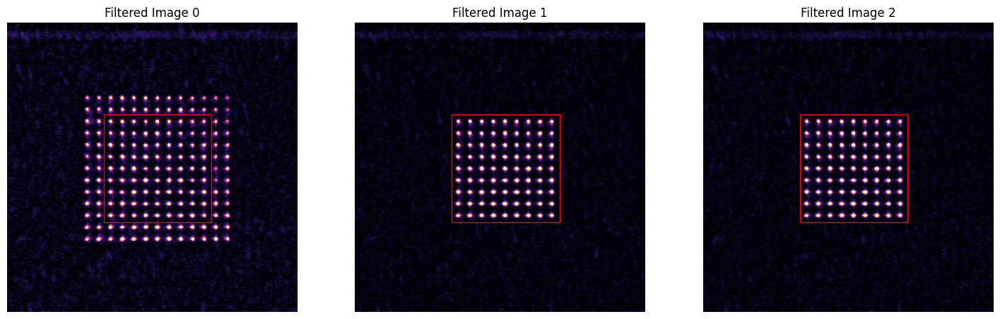

In [638]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 95.00 %
Trap (1) Loading Probability : 99.00 %
Trap (2) Loading Probability : 97.00 %
Trap (3) Loading Probability : 95.00 %
Trap (4) Loading Probability : 97.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 96.00 %
Trap (11) Loading Probability : 99.00 %
Trap (12) Loading Probability : 98.00 %
Trap (13) Loading Probability : 98.00 %
Trap (14) Loading Probability : 95.00 %
Trap (15) Loading Probability : 99.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 94.00 %
Trap (18) Loading Probability : 98.00 %
Trap (19) Loading Probability : 96.00 %
Trap (20) Loading Probability : 94.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 96.00 %
Trap (23) Loading Probability : 96.00 %
Trap 

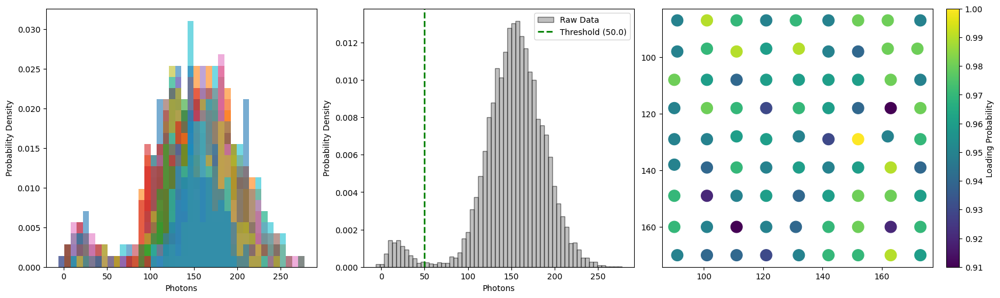

In [639]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 9*9, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
81 Atoms Detected.
Trap (0) Loading Probability : 93.00 %
Trap (1) Loading Probability : 96.00 %
Trap (2) Loading Probability : 94.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 94.00 %
Trap (5) Loading Probability : 91.00 %
Trap (6) Loading Probability : 94.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 92.00 %
Trap (9) Loading Probability : 93.00 %
Trap (10) Loading Probability : 95.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 95.00 %
Trap (13) Loading Probability : 99.00 %
Trap (14) Loading Probability : 93.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 91.00 %
Trap (22) Loading Probability : 95.00 %
Trap (23) Loading Probability : 95.00 %
Trap 

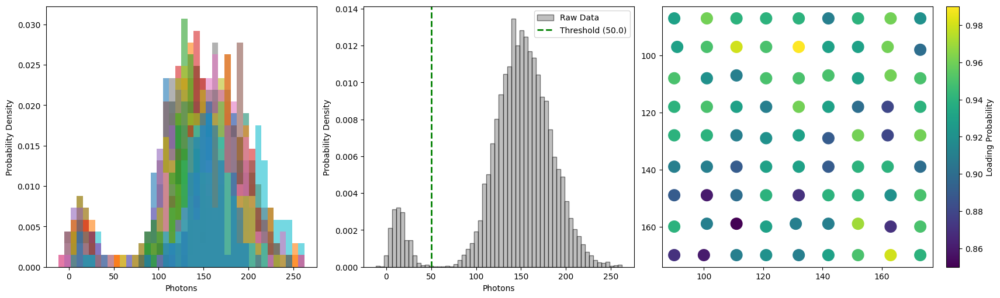

In [640]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 9*9, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [641]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9496


#### Save Data

In [642]:
dataset_title = "rearrange_transport_100ms_baseline_survival_probability"
context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 5 um spacing. Baseline survival probability after 100 ms hold.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "baseline_survival_probability": baseline_survival_probability,
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_100ms_baseline_survival_probability


---
## Rearrangement + Transport Test 1 - Kagome

Phasemask 2

In [664]:
W2 = np.ones((9,9))
spacing_um = 5.0

x_n2, y_n2, z_n2 = PM.generate_kagome_lattice(169/2, 5.0)
x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

w_n = np.ones_like(x_n2)  # gauss2d(x_n2, y_n2, A, x0, y0, sx, sy, offset)
theta_n = np.random.uniform(0, 2*np.pi, size=w_n.shape)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

Target sites: 84.5 | Closest symmetric match: 90 sites
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.58e-05 | Uniformity: 64.27% | Min/Max ratio: 0.074
Iteration 010 | Mean-Squared Error: 2.80e-07 | Uniformity: 95.24% | Min/Max ratio: 0.753
Iteration 020 | Mean-Squared Error: 1.88e-08 | Uniformity: 98.77% | Min/Max ratio: 0.929
Iteration 030 | Mean-Squared Error: 4.24e-08 | Uniformity: 98.15% | Min/Max ratio: 0.908
Iteration 040 | Mean-Squared Error: 7.60e-09 | Uniformity: 99.22% | Min/Max ratio: 0.958
Iteration 050 | Mean-Squared Error: 3.03e-09 | Uniformity: 99.50% | Min/Max ratio: 0.978
Iteration 060 | Mean-Squared Error: 7.62e-10 | Uniformity: 99.75% | Min/Max ratio: 0.988
Iteration 070 | Mean-Squared Error: 1.62e-10 | Uniformity: 99.89% | Min/Max ratio: 0.995
Iteration 080 | Mean-Squared Error: 6.07e-11 | Uniformity: 99.93% | Min/Max ratio: 0.997
Iteration 090 | Mean-Squared Error: 3.10e-11 | Uniformity: 99.95% | Min/Max ratio: 0.998

In [665]:
len(w_n)

90

Phasemask 3

In [666]:
W3 = np.ones((9,9))
spacing_um = 5.0
    
w_n, theta_n, x_n3, y_n3, z_n3 = PM.generate_weighted_array(W3, spacing_um, init_phase_randomness=1.0, angle_deg=2.5)
w_n = gauss2d(x_n3, y_n3, A, x0, y0, sx, sy, offset)

x_n3 += 0.0

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.44e-05 | Uniformity: 55.21% | Min/Max ratio: 0.091
Iteration 010 | Mean-Squared Error: 1.39e-07 | Uniformity: 84.35% | Min/Max ratio: 0.557
Iteration 020 | Mean-Squared Error: 2.96e-08 | Uniformity: 84.70% | Min/Max ratio: 0.542
Iteration 030 | Mean-Squared Error: 1.79e-08 | Uniformity: 85.08% | Min/Max ratio: 0.563
Iteration 040 | Mean-Squared Error: 4.00e-08 | Uniformity: 85.51% | Min/Max ratio: 0.554
Iteration 050 | Mean-Squared Error: 1.60e-08 | Uniformity: 85.14% | Min/Max ratio: 0.557
Iteration 060 | Mean-Squared Error: 2.43e-09 | Uniformity: 85.14% | Min/Max ratio: 0.559
Iteration 070 | Mean-Squared Error: 8.03e-10 | Uniformity: 85.13% | Min/Max ratio: 0.561
Iteration 080 | Mean-Squared Error: 3.35e-10 | Uniformity: 85.14% | Min/Max ratio: 0.562
Iteration 090 | Mean-Squared Error: 1.35e-10 | Uniformity: 85.15% | Min/Max ratio: 0.563
It

In [667]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data2,
    d0=0.5, d0_z=0.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="linear"
)

Occupancy via PSF detector (window 9, threshold 13.4).
Transport node initialised.


In [668]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [669]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 36 frames, 29.4366 ms total
Transport complete: 2 frames, 4.0089 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 27 frames, 22.9501 ms total
Transport complete: 2 frames, 4.0016 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 33 frames, 27.5623 ms total
Transport complete: 2 frames, 3.8505 ms total
Images acquired from rearrangement n

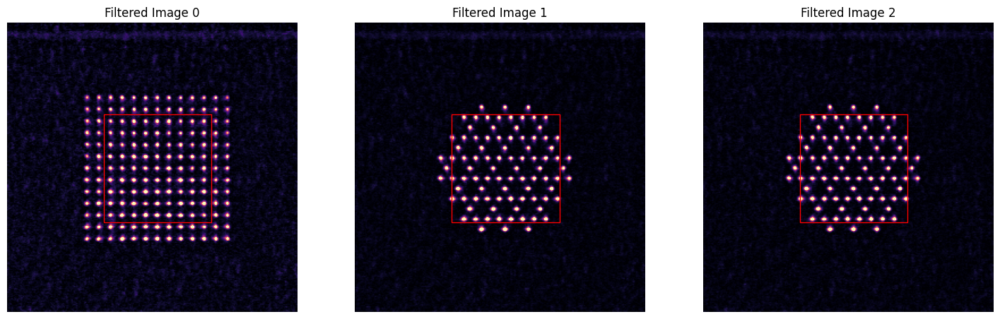

In [670]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
90 Atoms Detected.
Trap (0) Loading Probability : 99.00 %
Trap (1) Loading Probability : 97.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 97.00 %
Trap (4) Loading Probability : 99.00 %
Trap (5) Loading Probability : 95.00 %
Trap (6) Loading Probability : 97.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 96.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 99.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 94.00 %
Trap (15) Loading Probability : 95.00 %
Trap (16) Loading Probability : 95.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 95.00 %
Trap (19) Loading Probability : 93.00 %
Trap (20) Loading Probability : 98.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 91.00 %
Trap (23) Loading Probability : 97.00 %
Trap 

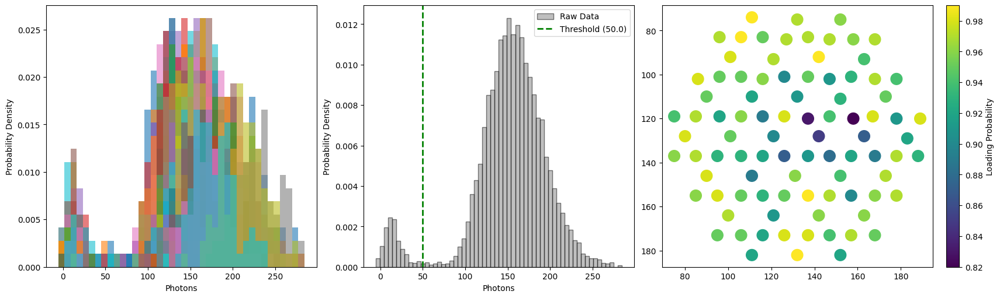

In [671]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 90, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
90 Atoms Detected.
Trap (0) Loading Probability : 98.00 %
Trap (1) Loading Probability : 92.00 %
Trap (2) Loading Probability : 93.00 %
Trap (3) Loading Probability : 95.00 %
Trap (4) Loading Probability : 96.00 %
Trap (5) Loading Probability : 91.00 %
Trap (6) Loading Probability : 95.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 95.00 %
Trap (9) Loading Probability : 95.00 %
Trap (10) Loading Probability : 92.00 %
Trap (11) Loading Probability : 97.00 %
Trap (12) Loading Probability : 96.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 90.00 %
Trap (15) Loading Probability : 92.00 %
Trap (16) Loading Probability : 92.00 %
Trap (17) Loading Probability : 93.00 %
Trap (18) Loading Probability : 91.00 %
Trap (19) Loading Probability : 87.00 %
Trap (20) Loading Probability : 92.00 %
Trap (21) Loading Probability : 89.00 %
Trap (22) Loading Probability : 97.00 %
Trap (23) Loading Probability : 90.00 %
Trap 

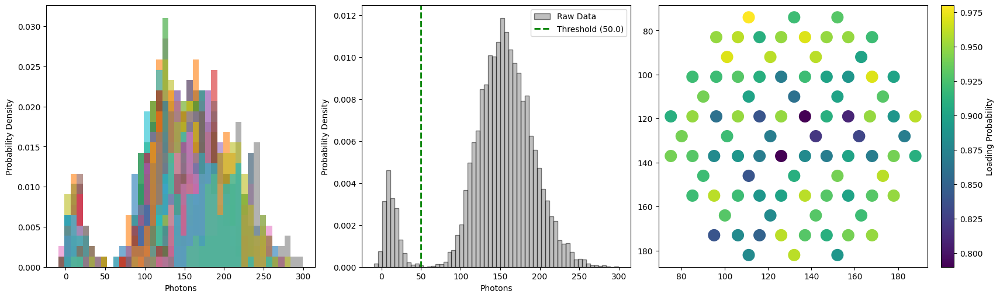

In [672]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 90, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

In [673]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9539


#### Save Data

In [674]:
dataset_title = "rearrange_transport_13x13_to_90kagome_5um_spacing"
context_info = """ 
    Rearrangement 13x13 array to 90 site kagome lattice with a 5 um spacing.
"""
pickles = {
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :]}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_13x13_to_90kagome_5um_spacing' already exists. Renaming to 'rearrange_transport_13x13_to_90kagome_5um_spacing_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_13x13_to_90kagome_5um_spacing_1


---
## Rearrangement + Transport Test 5 - Up and Over - 25.0 Lift - No Smooth Corners, 1.0 Step Size - Relock Repump

Phasemask 2

In [675]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.68e-05 | Uniformity: 41.40% | Min/Max ratio: 0.079
Iteration 010 | Mean-Squared Error: 1.90e-07 | Uniformity: 75.60% | Min/Max ratio: 0.377
Iteration 020 | Mean-Squared Error: 1.24e-08 | Uniformity: 75.34% | Min/Max ratio: 0.400
Iteration 030 | Mean-Squared Error: 3.73e-09 | Uniformity: 75.27% | Min/Max ratio: 0.399
Iteration 040 | Mean-Squared Error: 1.53e-09 | Uniformity: 75.24% | Min/Max ratio: 0.400
Iteration 050 | Mean-Squared Error: 1.31e-09 | Uniformity: 75.18% | Min/Max ratio: 0.399
Iteration 060 | Mean-Squared Error: 1.38e-09 | Uniformity: 75.12% | Min/Max ratio: 0.398
Iteration 070 | Mean-Squared Error: 1.51e-09 | Uniformity: 75.11% | Min/Max ratio: 0.397
Iteration 080 | Mean-Squared Error: 1.26e-09 | Uniformity: 75.13% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 7

Phasemask 3

In [676]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.50e-05 | Uniformity: 40.34% | Min/Max ratio: 0.072
Iteration 010 | Mean-Squared Error: 7.86e-08 | Uniformity: 75.37% | Min/Max ratio: 0.389
Iteration 020 | Mean-Squared Error: 1.72e-08 | Uniformity: 75.25% | Min/Max ratio: 0.386
Iteration 030 | Mean-Squared Error: 4.07e-09 | Uniformity: 75.26% | Min/Max ratio: 0.401
Iteration 040 | Mean-Squared Error: 6.98e-09 | Uniformity: 75.25% | Min/Max ratio: 0.400
Iteration 050 | Mean-Squared Error: 1.23e-08 | Uniformity: 75.12% | Min/Max ratio: 0.394
Iteration 060 | Mean-Squared Error: 5.04e-09 | Uniformity: 75.16% | Min/Max ratio: 0.395
Iteration 070 | Mean-Squared Error: 1.20e-09 | Uniformity: 75.16% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 1.05e-09 | Uniformity: 75.14% | Min/Max ratio: 0.400
Iteration 090 | Mean-Squared Error: 7

In [ ]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=1.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=False,
    only_moving=True,
    d_lift = 25.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 13.4).
Transport node initialised.


In [688]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [689]:
N_iterations = 1  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 1
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception: 
Rearrangement complete: 32 frames, 30.6611 ms total
Transport complete: 133 frames, 114.3710 ms total
Images acquired from rearrangement node.


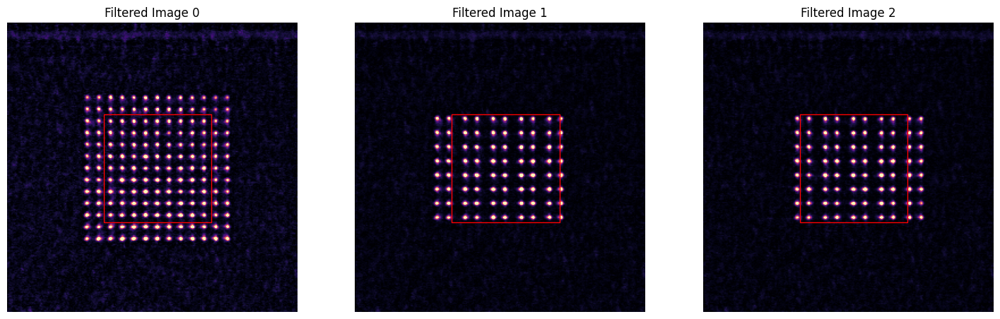

In [682]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 100.00 %
Trap (2) Loading Probability : 98.00 %
Trap (3) Loading Probability : 96.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 97.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 96.00 %
Trap (8) Loading Probability : 99.00 %
Trap (9) Loading Probability : 98.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 99.00 %
Trap (12) Loading Probability : 94.00 %
Trap (13) Loading Probability : 97.00 %
Trap (14) Loading Probability : 99.00 %
Trap (15) Loading Probability : 94.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 98.00 %
Trap (18) Loading Probability : 99.00 %
Trap (19) Loading Probability : 98.00 %
Trap (20) Loading Probability : 99.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 98.00 %
Trap (23) Loading Probability : 97.00 %
Trap

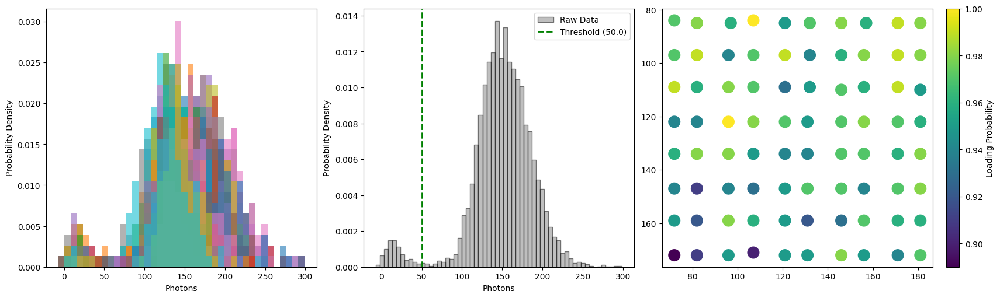

In [683]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 96.00 %
Trap (1) Loading Probability : 95.00 %
Trap (2) Loading Probability : 99.00 %
Trap (3) Loading Probability : 94.00 %
Trap (4) Loading Probability : 93.00 %
Trap (5) Loading Probability : 92.00 %
Trap (6) Loading Probability : 93.00 %
Trap (7) Loading Probability : 98.00 %
Trap (8) Loading Probability : 93.00 %
Trap (9) Loading Probability : 93.00 %
Trap (10) Loading Probability : 98.00 %
Trap (11) Loading Probability : 96.00 %
Trap (12) Loading Probability : 90.00 %
Trap (13) Loading Probability : 94.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 93.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 90.00 %
Trap (18) Loading Probability : 96.00 %
Trap (19) Loading Probability : 94.00 %
Trap (20) Loading Probability : 94.00 %
Trap (21) Loading Probability : 96.00 %
Trap (22) Loading Probability : 94.00 %
Trap (23) Loading Probability : 94.00 %
Trap 

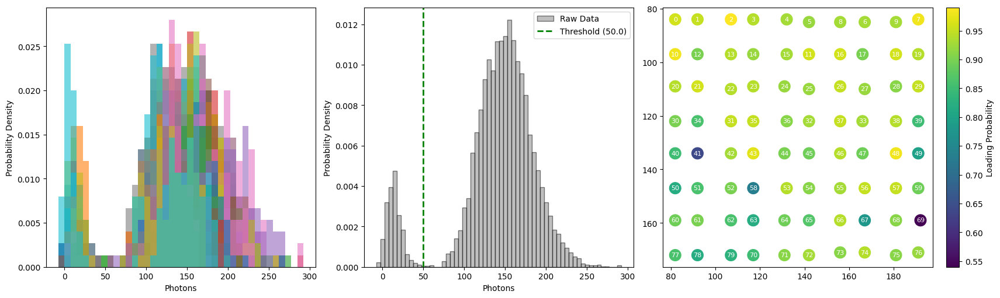

In [684]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [685]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.9084


#### Save Data

In [686]:
dataset_title = "rearrange_transport_leapfrog_25um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 25.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_leapfrog_25um_1dz_step' already exists. Renaming to 'rearrange_transport_leapfrog_25um_1dz_step_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_25um_1dz_step_1


---
## Rearrangement + Transport Test 5 - Up and Over - 25.0 Lift - No Smooth Corners, 1.0 Step Size - Relock Repump

Phasemask 2

In [691]:
W2a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n2_a, y_n2_a, z_n2_a = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W2a.flatten() * gauss2d(x_n2_a, y_n2_a, A, x0, y0, sx, sy, offset)
y_n2_a *= 0.5

w_n_b, theta_n_b, x_n2_b, y_n2_b, z_n2_b = PM.generate_weighted_array(W2a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W2a.flatten() * gauss2d(x_n2_b, y_n2_b, A, x0, y0, sx, sy, offset)
y_n2_b *= 0.5
x_n2_b += 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n2 = np.concatenate((x_n2_a, x_n2_b))
y_n2 = np.concatenate((y_n2_a, y_n2_b))
z_n2 = np.concatenate((z_n2_a, z_n2_b))

x_n2, y_n2 = pm.rotate_positions(x_n2, y_n2, angle_degrees=2.5)

terms2 = [w_n, theta_n, x_n2, y_n2, z_n2]
pm_array2, terms2, _ = PM.superposition_optimization(terms2, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.88e-05 | Uniformity: 36.66% | Min/Max ratio: 0.043
Iteration 010 | Mean-Squared Error: 1.12e-07 | Uniformity: 75.08% | Min/Max ratio: 0.381
Iteration 020 | Mean-Squared Error: 6.99e-09 | Uniformity: 75.20% | Min/Max ratio: 0.393
Iteration 030 | Mean-Squared Error: 9.09e-10 | Uniformity: 75.15% | Min/Max ratio: 0.398
Iteration 040 | Mean-Squared Error: 8.55e-10 | Uniformity: 75.13% | Min/Max ratio: 0.397
Iteration 050 | Mean-Squared Error: 9.58e-10 | Uniformity: 75.13% | Min/Max ratio: 0.397
Iteration 060 | Mean-Squared Error: 7.33e-10 | Uniformity: 75.15% | Min/Max ratio: 0.398
Iteration 070 | Mean-Squared Error: 4.61e-10 | Uniformity: 75.17% | Min/Max ratio: 0.399
Iteration 080 | Mean-Squared Error: 3.23e-10 | Uniformity: 75.18% | Min/Max ratio: 0.399
Iteration 090 | Mean-Squared Error: 1

Phasemask 3

In [692]:
W3a = np.ones((8,5))
spacing_um = 12.0

w_n_a, theta_n_a, x_n3_a, y_n3_a, z_n3_a = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_a = W3a.flatten() * gauss2d(x_n3_a, y_n3_a, A, x0, y0, sx, sy, offset)
y_n3_a *= 0.5

w_n_b, theta_n_b, x_n3_b, y_n3_b, z_n3_b = PM.generate_weighted_array(W3a, spacing_um, init_phase_randomness=1.0, angle_deg=0.0)
w_n_b = W3a.flatten() * gauss2d(x_n3_b, y_n3_b, A, x0, y0, sx, sy, offset)
y_n3_b *= 0.5
x_n3_b -= 5.0

w_n = np.concatenate((w_n_a, w_n_b))
theta_n = np.concatenate((theta_n_a, theta_n_b))
x_n3 = np.concatenate((x_n3_a, x_n3_b))
y_n3 = np.concatenate((y_n3_a, y_n3_b))
z_n3 = np.concatenate((z_n3_a, z_n3_b))

x_n3, y_n3 = pm.rotate_positions(x_n3, y_n3, angle_degrees=2.5)

terms3 = [w_n, theta_n, x_n3, y_n3, z_n3]
pm_array3, terms3, _ = PM.superposition_optimization(terms3, max_iter=2000, damping=0.5, verbose=True)

--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Target Generation ---
Grid: 8x5
Spacing: 12.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 2.40e-05 | Uniformity: 41.23% | Min/Max ratio: 0.055
Iteration 010 | Mean-Squared Error: 6.67e-08 | Uniformity: 74.84% | Min/Max ratio: 0.375
Iteration 020 | Mean-Squared Error: 1.18e-08 | Uniformity: 75.21% | Min/Max ratio: 0.397
Iteration 030 | Mean-Squared Error: 5.35e-09 | Uniformity: 75.16% | Min/Max ratio: 0.395
Iteration 040 | Mean-Squared Error: 6.50e-09 | Uniformity: 75.18% | Min/Max ratio: 0.399
Iteration 050 | Mean-Squared Error: 8.03e-09 | Uniformity: 75.24% | Min/Max ratio: 0.400
Iteration 060 | Mean-Squared Error: 7.18e-09 | Uniformity: 75.16% | Min/Max ratio: 0.399
Iteration 070 | Mean-Squared Error: 3.48e-09 | Uniformity: 75.17% | Min/Max ratio: 0.398
Iteration 080 | Mean-Squared Error: 2.51e-09 | Uniformity: 75.19% | Min/Max ratio: 0.398
Iteration 090 | Mean-Squared Error: 1

In [693]:
import asyncio
from pytweezer.coordinators.transport import Transport
import time

coordinator = Transport({"camera": hamcam, "slm": slm, "phasemask_generator": PM}, {})

data1 = np.stack(terms1[:5])
data2 = np.stack(terms2[:5])
data3 = np.stack(terms3[:5])

await asyncio.to_thread(
    coordinator.initialise,
    data1, data2, data3,
    d0=0.5, d0_z=1.0,
    fps=1/(1e-6), 
    threshold=an.convert_photons_to_counts(threshold_1)*1.0,
    grid_positions=grid_positions, 
    d0_transport=0.5, d0_z_transport=2.0,
    profile="linear", 
    window_size=5, 
    feature_size=10, 
    detector=scorer,
    path_fn="lift",
    smooth_corners=True,
    only_moving=True,
    d_lift = 25.0,
    refine_iters = 1
)

Occupancy via PSF detector (window 9, threshold 13.4).
Transport node initialised.


In [694]:
# Experiment and camera setup
n_iterations = 1
exp.set_motmaster_experiment("RbTweezerBasic2026_2_Assemble")
exp.set_iterations(n_iterations)
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)

{'ok': True,
 'command': 'interface_method',
 'method': 'set_run_until_stopped',
 'state': 'accepted'}

In [696]:
N_iterations = 100  # adjust before running
imgs_software = []
err_indices = []
timings_log = []

for it in range(N_iterations):
    print(f"Running experiment iteration {it+1} / {N_iterations}")
    transport_task = asyncio.create_task(asyncio.to_thread(coordinator.arm_transport_pattern))

    time.sleep(0.1)
    exp.start_motmaster_experiment({
                "tMOTLoadRepVCO": ExpParams.get_parameter("tMOTLoadRepVCO"), "tMOTLoadCoolVCO": ExpParams.get_parameter("tMOTLoadCoolVCO"),
                "tMOTLoadRepVVA": ExpParams.get_parameter("tMOTLoadRepVVA"), "tMOTLoadCoolVVA": ExpParams.get_parameter("tMOTLoadCoolVVA"),
                "tMolCoolVCO1": ExpParams.get_parameter("tMolCoolVCO1"), "tMolRepVCO1": ExpParams.get_parameter("tMolRepVCO1"), 
                "tMolCoolVVA1": ExpParams.get_parameter("tMolCoolVVA1"), "tMolRepVVA1": ExpParams.get_parameter("tMolRepVVA1"),
                "tMolCoolVCO2": ExpParams.get_parameter("tMolCoolVCO2"), "tMolRepVCO2": ExpParams.get_parameter("tMolRepVCO2"), 
                "tMolCoolVVA2": ExpParams.get_parameter("tMolCoolVVA2"), "tMolRepVVA2": ExpParams.get_parameter("tMolRepVVA2"),
                "tImgCoolVCO1": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA1": ExpParams.get_parameter("tImgCoolVVA"), 
                "tImgCoolVCO2": ExpParams.get_parameter("tImgCoolVCO"), "tImgCoolVVA2": ExpParams.get_parameter("tImgCoolVVA"),
                "tMolassesShimXccValue": ExpParams.get_parameter("tMolassesShimXccValue"), "tMolassesShimYccValue": ExpParams.get_parameter("tMolassesShimYccValue"), "tMolassesShimZccValue": ExpParams.get_parameter("tMolassesShimZccValue"),
                "tMOTShimXccValue": ExpParams.get_parameter("tMOTShimXccValue"), "tMOTShimYccValue": ExpParams.get_parameter("tMOTShimYccValue"), "tMOTShimZccValue": ExpParams.get_parameter("tMOTShimZccValue"),
                "BackgroundDrop": 0, "tTweezerSetVVA0": 9.0, "tTweezerSetVVA1": 10.0})
    img0, imgs1, imgs2, timings = await transport_task
    print("Images acquired from rearrangement node.")

    if imgs1.sum() == 0:
        print(f"Empty image received at iteration {it+1}. Discarding...")
        err_indices.append(it)
    else:
        imgs_software.append([img0, imgs1, imgs2])
        timings_log.append(timings)

Running experiment iteration 1 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Reset-image acquisition failed. Exception: 
Rearrangement complete: 27 frames, 25.7997 ms total
Transport complete: 86 frames, 87.0653 ms total
Images acquired from rearrangement node.
Running experiment iteration 2 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 22 frames, 20.7910 ms total
Transport complete: 86 frames, 73.4446 ms total
Images acquired from rearrangement node.
Running experiment iteration 3 / 100
Waiting for initial image...
Rearranging...
Rearrangement complete.
Waiting for second image...
Transporting...
Transport complete.
Waiting for reset image...
Rearrangement complete: 27 frames, 24.2028 ms total
Transport complete: 86 frames, 75.

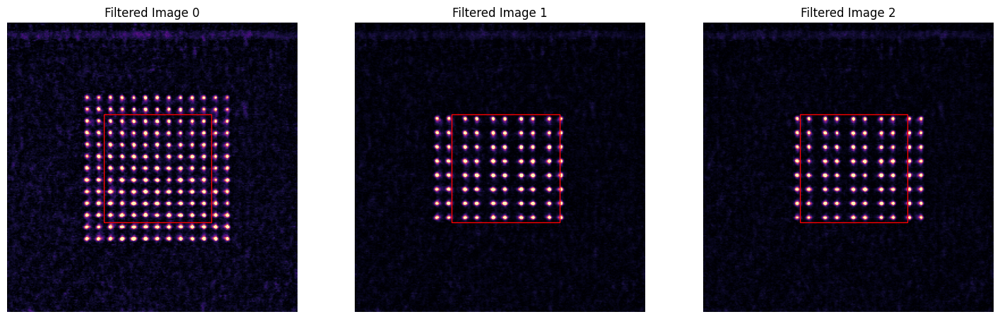

In [698]:
num_imgs_per_it = 3
tot_imgs = np.array(imgs_software)

plt.figure(figsize=(6*num_imgs_per_it, 6))
for n in range(num_imgs_per_it):
    imgs_n = tot_imgs[:, n, :, :]
    imgs__n_mean = imgs_n.mean(axis=0)
    imgs_n_mean_filtered = an.morphological_tophat_high_pass(imgs__n_mean, feature_size=feature_size)
    plt.subplot(1, num_imgs_per_it, n + 1)
    plt.imshow(imgs_n_mean_filtered, cmap='magma', vmax=0.4*imgs_n_mean_filtered.max())

    # Draw a box around the centre of the image to indicate the region of interest
    center_x, center_y = imgs_n_mean_filtered.shape[1] // 2+4, imgs_n_mean_filtered.shape[0] // 2
    box_size = 95  # Size of the box
    rect = plt.Rectangle((center_x - box_size // 2, center_y - box_size // 2), box_size, box_size, edgecolor='red', facecolor='none', linewidth=1)
    plt.gca().add_patch(rect)

    plt.title(f'Filtered Image {n}')
    plt.axis('off')
plt.show()

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 97.00 %
Trap (1) Loading Probability : 98.00 %
Trap (2) Loading Probability : 96.00 %
Trap (3) Loading Probability : 93.00 %
Trap (4) Loading Probability : 95.00 %
Trap (5) Loading Probability : 99.00 %
Trap (6) Loading Probability : 98.00 %
Trap (7) Loading Probability : 97.00 %
Trap (8) Loading Probability : 97.00 %
Trap (9) Loading Probability : 97.00 %
Trap (10) Loading Probability : 97.00 %
Trap (11) Loading Probability : 98.00 %
Trap (12) Loading Probability : 97.00 %
Trap (13) Loading Probability : 96.00 %
Trap (14) Loading Probability : 98.00 %
Trap (15) Loading Probability : 99.00 %
Trap (16) Loading Probability : 96.00 %
Trap (17) Loading Probability : 95.00 %
Trap (18) Loading Probability : 98.00 %
Trap (19) Loading Probability : 95.00 %
Trap (20) Loading Probability : 98.00 %
Trap (21) Loading Probability : 95.00 %
Trap (22) Loading Probability : 92.00 %
Trap (23) Loading Probability : 96.00 %
Trap 

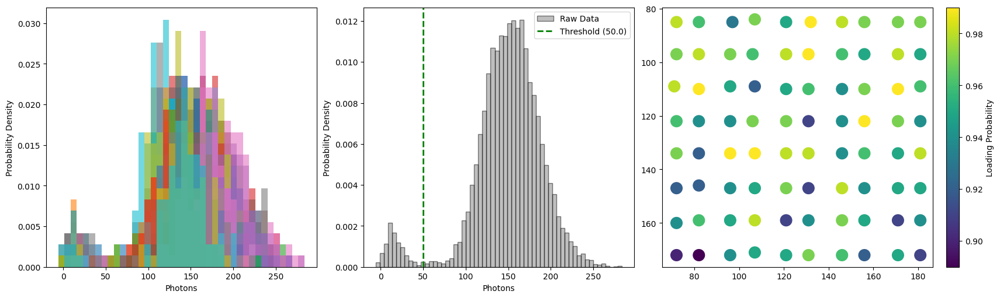

In [699]:
n = 1
imgs_1 = tot_imgs[:, n, :, :]
imgs_1_mean = imgs_1.mean(axis=0)
imgs_1_mean_filtered = an.morphological_tophat_high_pass(imgs_1_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_1, _ = an.detect_trap_sites(imgs_1_mean_filtered, 80, detection_step=100)

imgs_1_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_1]
photons1, loading_probabilities1, threshold1, fidelity1 = an.get_array_loading_statistics(imgs_1_filtered, grid_positions_1, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=False)

Looking for trap sites...
80 Atoms Detected.
Trap (0) Loading Probability : 88.00 %
Trap (1) Loading Probability : 88.00 %
Trap (2) Loading Probability : 89.00 %
Trap (3) Loading Probability : 91.00 %
Trap (4) Loading Probability : 91.00 %
Trap (5) Loading Probability : 83.00 %
Trap (6) Loading Probability : 87.00 %
Trap (7) Loading Probability : 89.00 %
Trap (8) Loading Probability : 89.00 %
Trap (9) Loading Probability : 90.00 %
Trap (10) Loading Probability : 90.00 %
Trap (11) Loading Probability : 90.00 %
Trap (12) Loading Probability : 86.00 %
Trap (13) Loading Probability : 73.00 %
Trap (14) Loading Probability : 92.00 %
Trap (15) Loading Probability : 86.00 %
Trap (16) Loading Probability : 88.00 %
Trap (17) Loading Probability : 85.00 %
Trap (18) Loading Probability : 87.00 %
Trap (19) Loading Probability : 76.00 %
Trap (20) Loading Probability : 89.00 %
Trap (21) Loading Probability : 82.00 %
Trap (22) Loading Probability : 84.00 %
Trap (23) Loading Probability : 86.00 %
Trap 

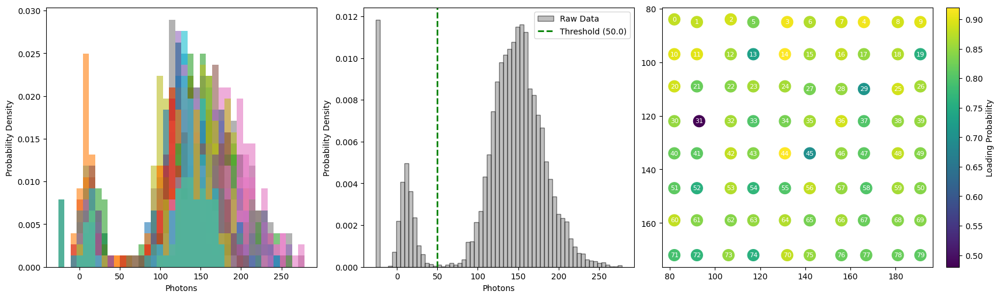

In [700]:
n = 2
imgs_2 = tot_imgs[:, n, :, :]
imgs_2_mean = imgs_2.mean(axis=0)
imgs_2_mean_filtered = an.morphological_tophat_high_pass(imgs_2_mean, feature_size=feature_size)

feature_size, window = 10, 5
grid_positions_2, _ = an.detect_trap_sites(imgs_2_mean_filtered, 80, detection_step=100)

imgs_2_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs_2]
photons2, loading_probabilities2, threshold2, fidelity2 = an.get_array_loading_statistics(imgs_2_filtered, grid_positions_2, threshold=50, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=False, verbose=True, show_site_labels=True)

In [701]:
baseline_survival_probability = extract_survival_probability(imgs_1_filtered, imgs_2_filtered, grid_positions_1, grid_positions_2, threshold=50, window_size=window)
print(f"Baseline survival probability: {baseline_survival_probability:.4f}")

Baseline survival probability: 0.8500


#### Save Data

In [ ]:
dataset_title = "rearrange_transport_leapfrog_25um_1dz_step"

context_info = """ 
    Rearrangement 13x13 array to 9x9 array with a 7 um spacing. 25.0 um dz leapfrog. 1 equalisation iteration. No smooth corners.
    1.0 dz step size - instead of 2.0.
"""
pickles = {"grid_positions": grid_positions, 
           "imgs1": tot_imgs[:, 0, :, :], 
           "imgs2": tot_imgs[:, 1, :, :],
           "imgs3": tot_imgs[:, 2, :, :],
           "photons1": photons1,
           "photons2": photons2,
           "loading_probabilities1": loading_probabilities1,
           "loading_probabilities2": loading_probabilities2}

images = {"imgs1": tot_imgs[:, 0, :, :], "imgs2": tot_imgs[:, 1, :, :], "imgs3": tot_imgs[:, 2, :, :]}

DM.save_dataset(dataset_title, context_info, pickles=pickles, images=images)

Dataset 'rearrange_transport_leapfrog_25um_1dz_step' already exists. Renaming to 'rearrange_transport_leapfrog_25um_1dz_step_1'.
Successfully saved to C:\Users\tweez\Box\Working folder\caftweezers\Data\2026\Oct\13Oct26\rearrange_transport_leapfrog_25um_1dz_step_1
